In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 1024     # Increased batch size for better training stability
EPOCHS = 300          # More epochs for better convergence
LOG_INTERVAL = 50     # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
LATENT_DIM = 256
HIDDEN_DIM = 4096
COUPLING_HIDDEN_DIM = 512
N_COUPLE_LAYERS = 8

# VAE-specific hyperparameters
LR = 5e-4             # Lower learning rate for more stable training
BETA = 0.5            # Reduced beta to prevent posterior collapse
BETA_WARMUP = 50      # Epochs to gradually increase beta
WEIGHT_DECAY = 1e-5   # L2 regularization

# Visualization settings
SAVE_PLT_INTERVAL = 10  # How often to save plots (every 10 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE} (increased for stability)")
print(f"Epochs: {EPOCHS} (more epochs for convergence)")
print(f"Hidden dimension: {HIDDEN_DIM} (larger capacity)")
print(f"Latent dimension: {LATENT_DIM} (increased for better representation)")
print(f"Learning rate: {LR} (lower for stability)")
print(f"Beta (KL weight): {BETA} (reduced to prevent collapse)")
print(f"Beta warmup epochs: {BETA_WARMUP}")
print(f"Weight decay: {WEIGHT_DECAY}")
print(f"Device: {device}")


Batch size: 1024 (increased for stability)
Epochs: 300 (more epochs for convergence)
Hidden dimension: 4096 (larger capacity)
Latent dimension: 256 (increased for better representation)
Learning rate: 0.0005 (lower for stability)
Beta (KL weight): 0.5 (reduced to prevent collapse)
Beta warmup epochs: 50
Weight decay: 1e-05
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")


Batch size: 1024
Training batches: 59
Test batches: 10


In [5]:
class CouplingLayer(nn.Module):
    """
    A coupling layer that transforms data using neural networks.

    The key idea:
    - Split input x into two parts using a mask
    - Transform one part based on the other part
    - Combine them back together
    """

    def __init__(self, input_dim, output_dim, hid_dim, mask):
        super().__init__()

        # The mask determines which dimensions to transform
        # mask = [0, 1] means: don't transform dimension 0, transform dimension 1
        self.register_buffer("mask", mask, persistent=False)

        # Neural networks to compute scaling (s) and translation (t) factors
        # These networks take the "untransformed" part and predict how to transform the other part

        # Scaling network (s): predicts how much to scale each dimension
        self.s_fc1 = nn.Linear(input_dim, hid_dim)
        self.s_fc2 = nn.Linear(hid_dim, hid_dim)
        self.s_fc3 = nn.Linear(hid_dim, hid_dim)
        self.s_fc4 = nn.Linear(hid_dim, output_dim)

        # Translation network (t): predicts how much to shift each dimension
        self.t_fc1 = nn.Linear(input_dim, hid_dim)
        self.t_fc2 = nn.Linear(hid_dim, hid_dim)
        self.t_fc3 = nn.Linear(hid_dim, hid_dim)
        self.t_fc4 = nn.Linear(hid_dim, output_dim)

    def forward(self, x):
        """
        Transform x to y using the coupling layer.
        Returns: y (transformed data) and log_det_jacobian (for computing likelihood)
        """
        # Apply mask to get the "untransformed" part
        x_m = x * self.mask

        # Compute scaling and translation factors from the untransformed part
        s_out = torch.tanh(self.s_fc4(F.relu(self.s_fc3(F.relu(self.s_fc2(F.relu(self.s_fc1(x_m))))))))
        t_out = self.t_fc4(F.relu(self.t_fc3(F.relu(self.t_fc2(F.relu(self.t_fc1(x_m)))))))

        # Apply the transformation: y = x_m + (1-mask) * (x * exp(s) + t)
        # This means: keep the masked part unchanged, transform the unmasked part
        y = x_m + (1 - self.mask) * (x * torch.exp(s_out) + t_out)

        # Compute log determinant of Jacobian (needed for likelihood computation)
        log_det_jacobian = s_out.sum(dim=1)

        return y, log_det_jacobian

    def backward(self, y):
        """
        Reverse transformation: convert y back to x.
        This is what makes the flow invertible!
        """
        # Apply mask to get the "untransformed" part
        y_m = y * self.mask

        # Compute scaling and translation factors
        s_out = torch.tanh(self.s_fc4(F.relu(self.s_fc3(F.relu(self.s_fc2(F.relu(self.s_fc1(y_m))))))))

        t_out = self.t_fc4(F.relu(self.t_fc3(F.relu(self.t_fc2(F.relu(self.t_fc1(y_m)))))))

        # Reverse the transformation: x = y_m + (1-mask) * (y - t) * exp(-s)
        x = y_m + (1 - self.mask) * (y - t_out) * torch.exp(-s_out)

        return x


In [6]:
class VAE(nn.Module):
    """
    Variational Autoencoder with better architecture and training stability.
    """
    
    def __init__(self, input_dim, latent_dim, hidden_dim, coupling_hid_dim, mask, n_layers=6):
        super().__init__()
        
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim

        self.coupling_layers = nn.ModuleList()

        # First layer uses the given mask
        self.coupling_layers.append(CouplingLayer(latent_dim, latent_dim, coupling_hid_dim, mask))

        # Middle layers alternate the mask pattern
        # This ensures all dimensions get transformed
        for _ in range(n_layers - 2):
            mask = 1 - mask  # Flip the mask
            self.coupling_layers.append(CouplingLayer(latent_dim, latent_dim, coupling_hid_dim, mask))

        # Last layer uses the opposite mask
        self.coupling_layers.append(CouplingLayer(latent_dim, latent_dim, coupling_hid_dim, 1 - mask))
        
        # Encoder network with batch normalization and dropout
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),

            nn.Linear(hidden_dim // 2, latent_dim),
        )
        
        # Encoder outputs (mean and log variance)
        self.fc_mu = nn.Linear(latent_dim, latent_dim)
        self.fc_logvar = nn.Linear(latent_dim, latent_dim)
        
        # Decoder network with batch normalization and dropout
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),

            nn.Linear(latent_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim // 2, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, input_dim),
        )
        
        # Initialize weights properly
        self._initialize_weights()
    
    def _initialize_weights(self):
        """Initialize network weights for better training."""
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
    
    def encode(self, x):
        """
        Encode input data into latent space.
        
        Args:
            x: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            mu: Mean of latent distribution
            logvar: Log variance of latent distribution
        """
        x = self.encoder(x)

        for coupling_layer in self.coupling_layers:
            x, _ = coupling_layer(x)

        mu = self.fc_mu(x)
        logvar = self.fc_logvar(x)
        # Clamp logvar to prevent numerical instability
        logvar = torch.clamp(logvar, min=-10, max=10)
        return mu, logvar
    
    def reparameterize(self, mu, logvar):
        """
        Reparameterization trick for sampling from latent distribution.
        
        Args:
            mu: Mean of latent distribution
            logvar: Log variance of latent distribution
        
        Returns:
            z: Sampled latent vector
        """
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    
    def decode(self, z):
        """
        Decode latent vector back to data space.
        
        Args:
            z: Latent vector of shape (batch_size, latent_dim)
        
        Returns:
            reconstructed: Reconstructed data
        """

        for coupling_layer in reversed(self.coupling_layers):
            z = coupling_layer.backward(z)

        return self.decoder(z)
    
    def forward(self, x):
        """
        Forward pass through the VAE.
        
        Args:
            x: Input data tensor
        
        Returns:
            reconstructed: Reconstructed data
            mu: Mean of latent distribution
            logvar: Log variance of latent distribution
        """
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decode(z)
        return reconstructed, mu, logvar


In [7]:
mask = torch.from_numpy(np.concat([np.zeros(LATENT_DIM // 2), np.ones(LATENT_DIM // 2)]).astype(np.float32))

# Initialize model
vae = VAE(INPUT_DIM, LATENT_DIM, HIDDEN_DIM, COUPLING_HIDDEN_DIM, mask, N_COUPLE_LAYERS)

# Move model to device
vae = vae.to(device)

# Set up optimizer with weight decay
optimizer = torch.optim.Adam(vae.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

# Learning rate scheduler for better convergence
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=20
)

print(f"Model parameters: {sum(p.numel() for p in vae.parameters()):,}")
print(f"Learning rate: {LR}")
print(f"Weight decay: {WEIGHT_DECAY}")
print(f"Model moved to device: {device}")
print(f"Learning rate scheduler: ReduceLROnPlateau")

# Let's see what our model looks like
print("\nVAE architecture:")
print(vae)


Model parameters: 70,674,192
Learning rate: 0.0005
Weight decay: 1e-05
Model moved to device: cuda
Learning rate scheduler: ReduceLROnPlateau

VAE architecture:
VAE(
  (coupling_layers): ModuleList(
    (0-7): 8 x CouplingLayer(
      (s_fc1): Linear(in_features=256, out_features=512, bias=True)
      (s_fc2): Linear(in_features=512, out_features=512, bias=True)
      (s_fc3): Linear(in_features=512, out_features=512, bias=True)
      (s_fc4): Linear(in_features=512, out_features=256, bias=True)
      (t_fc1): Linear(in_features=256, out_features=512, bias=True)
      (t_fc2): Linear(in_features=512, out_features=512, bias=True)
      (t_fc3): Linear(in_features=512, out_features=512, bias=True)
      (t_fc4): Linear(in_features=512, out_features=256, bias=True)
    )
  )
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=4096, bias=True)
    (1): BatchNorm1d(4096, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dr

In [8]:
def vae_loss(reconstructed, original, mu, logvar, beta=1.0):
    """
    Compute the VAE loss function with better numerical stability.
    
    Args:
        reconstructed: Reconstructed data from decoder
        original: Original input data
        mu: Mean of latent distribution
        logvar: Log variance of latent distribution
        beta: Weight for KL divergence term
    
    Returns:
        total_loss: Total VAE loss
        recon_loss: Reconstruction loss
        kl_loss: KL divergence loss
    """
    # Reconstruction loss (MSE with mean reduction for better scaling)
    recon_loss = F.mse_loss(reconstructed, original, reduction='mean')
    
    # KL divergence loss with numerical stability
    # KL(q(z|x) || p(z)) where p(z) = N(0, I)
    # closed form analytical solution for KL divergence
    kl_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    
    # Total loss
    total_loss = recon_loss + beta * kl_loss
    
    return total_loss, recon_loss, kl_loss

def get_beta_schedule(epoch, max_epochs, warmup_epochs):
    """
    Get beta value with warmup schedule to prevent posterior collapse.
    
    Args:
        epoch: Current epoch
        max_epochs: Total number of epochs
        warmup_epochs: Number of epochs for warmup
    
    Returns:
        beta: Current beta value
    """
    if epoch < warmup_epochs:
        # Linear warmup from 0 to BETA
        return BETA * (epoch / warmup_epochs)
    else:
        # Cyclical annealing to prevent posterior collapse
        cycle_length = 50
        cycle_position = (epoch - warmup_epochs) % cycle_length
        cycle_progress = cycle_position / cycle_length
        return BETA * (0.5 + 0.5 * np.cos(np.pi * cycle_progress))

def train_epoch(epoch):
    """
    Train the VAE for one epoch with beta scheduling.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_total_loss: Average total loss for this epoch
        avg_recon_loss: Average reconstruction loss
        avg_kl_loss: Average KL divergence loss
        current_beta: Current beta value used
    """
    vae.train()
    
    # Get current beta value with scheduling
    current_beta = get_beta_schedule(epoch, EPOCHS, BETA_WARMUP)
    
    total_losses = []
    recon_losses = []
    kl_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        data = data.to(device)
        
        # Clear gradients
        optimizer.zero_grad()
        
        # Forward pass
        reconstructed, mu, logvar = vae(data)
        
        # Compute loss with current beta
        total_loss, recon_loss, kl_loss = vae_loss(reconstructed, data, mu, logvar, current_beta)
        
        # Backward pass
        total_loss.backward()
        
        # Gradient clipping for stability
        torch.nn.utils.clip_grad_norm_(vae.parameters(), max_norm=1.0)
        
        optimizer.step()
        
        # Track losses
        total_losses.append(total_loss.item())
        recon_losses.append(recon_loss.item())
        kl_losses.append(kl_loss.item())
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tTotal Loss: {:.6f}\tRecon Loss: {:.6f}\tKL Loss: {:.6f}\tBeta: {:.3f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), total_loss.item(), recon_loss.item(), kl_loss.item(), current_beta))
    
    # Calculate average losses
    avg_total_loss = sum(total_losses) / len(total_losses)
    avg_recon_loss = sum(recon_losses) / len(recon_losses)
    avg_kl_loss = sum(kl_losses) / len(kl_losses)
    
    # Update learning rate scheduler
    scheduler.step(avg_total_loss)
    
    print('====> Epoch: {} Average Total Loss: {:.4f}, Average Recon Loss: {:.4f}, Average KL Loss: {:.4f}, Beta: {:.3f}'.format(
        epoch, avg_total_loss, avg_recon_loss, avg_kl_loss, current_beta))
    
    return avg_total_loss, avg_recon_loss, avg_kl_loss, current_beta

In [9]:
def generate_samples(num_samples=1000):
    """
    Generate new samples using the VAE decoder.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        generated_samples: Generated data as numpy array
    """
    vae.eval()
    
    with torch.no_grad():
        # Sample from standard Gaussian in latent space
        z = torch.randn(num_samples, LATENT_DIM, device=device)
        
        # Decode to generate samples
        generated_samples = vae.decode(z)
        
        # Convert to numpy for visualization
        generated_samples = generated_samples.cpu().numpy()
    
    return generated_samples

def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

def visualize_training_progress(epoch, total_losses, recon_losses, kl_losses, save_plot=False):
    """
    Visualize the current state of our VAE training.
    
    Args:
        epoch: Current epoch number
        total_losses: List of total losses
        recon_losses: List of reconstruction losses
        kl_losses: List of KL divergence losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Loss plots
    if len(total_losses) > 0:
        epochs_range = range(1, len(total_losses) + 1)
        
        # Total loss
        plt.subplot(2, 3, 4)
        plt.plot(epochs_range, total_losses, 'g-', label='Total Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Total Loss')
        plt.title('Total Loss Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Reconstruction and KL losses
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, recon_losses, 'b-', label='Reconstruction Loss', linewidth=2)
        plt.plot(epochs_range, kl_losses, 'r-', label='KL Divergence Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Loss Components')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, total_losses, 'g-', label='Total Loss', linewidth=2)
        plt.plot(epochs_range, recon_losses, 'b-', label='Reconstruction Loss', linewidth=1, alpha=0.7)
        plt.plot(epochs_range, kl_losses, 'r-', label='KL Divergence Loss', linewidth=1, alpha=0.7)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('All Losses Combined')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    # Save plot if requested
    if save_plot:
        if not os.path.exists('vae_results'):
            os.makedirs('vae_results')
        plt.savefig(f'vae_results/vae_progress_epoch_{epoch}.png', dpi=150, bbox_inches='tight')
        print(f"💾 Saved plot: vae_results/vae_progress_epoch_{epoch}.png")
    
    plt.show()


🎯 Starting VAE training...
📊 Initial state (before training):
💾 Saved plot: vae_results/vae_progress_epoch_0.png


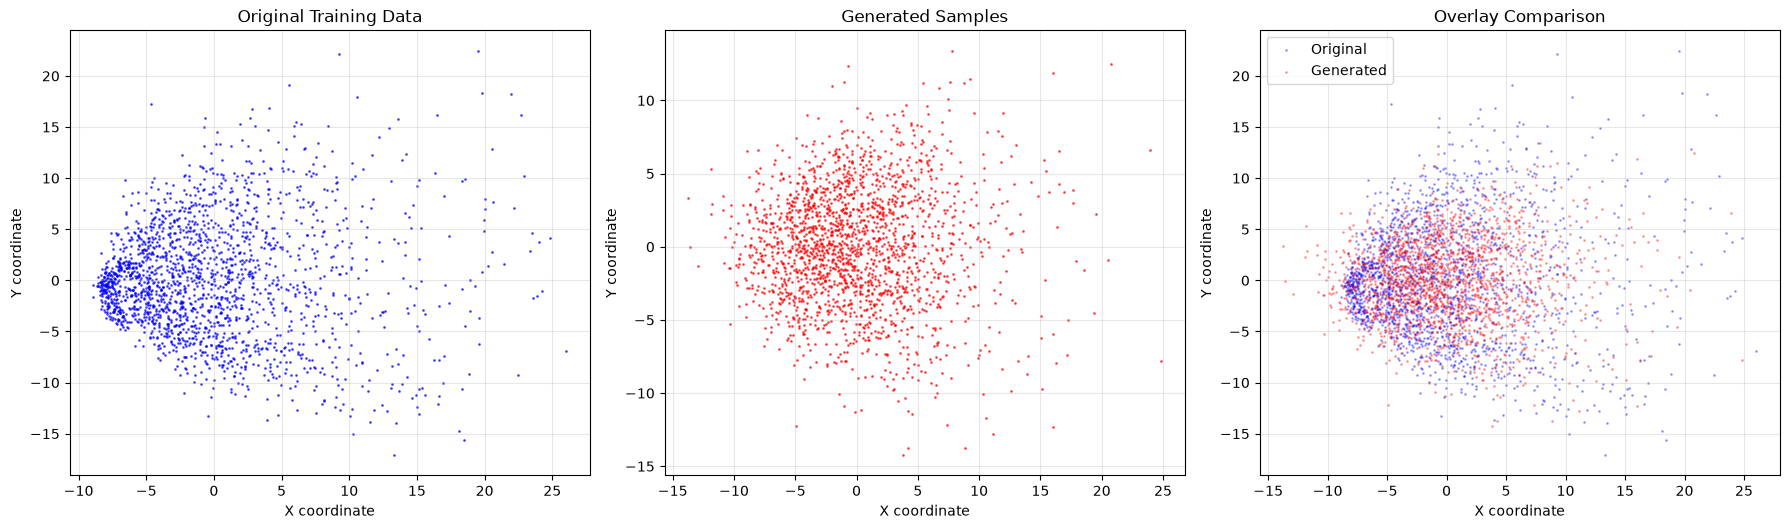


📊 Epoch 1/300
----------------------------------------
Epoch: 1 [0/60000 (0%)]	Total Loss: 1.072759	Recon Loss: 1.056384	KL Loss: 1.637529	Beta: 0.010
Epoch: 1 [51200/60000 (85%)]	Total Loss: 0.092071	Recon Loss: 0.089132	KL Loss: 0.293899	Beta: 0.010
====> Epoch: 1 Average Total Loss: 3.4426, Average Recon Loss: 0.7562, Average KL Loss: 268.6395, Beta: 0.010
📈 Epoch 1 Summary:
   Total Loss: 3.4426
   Reconstruction Loss: 0.7562
   KL Divergence Loss: 268.6395
   Beta: 0.010
   Learning Rate: 0.000500

📊 Epoch 2/300
----------------------------------------
Epoch: 2 [0/60000 (0%)]	Total Loss: 0.080386	Recon Loss: 0.075151	KL Loss: 0.261732	Beta: 0.020
Epoch: 2 [51200/60000 (85%)]	Total Loss: 0.059447	Recon Loss: 0.056203	KL Loss: 0.162206	Beta: 0.020
====> Epoch: 2 Average Total Loss: 0.0676, Average Recon Loss: 0.0638, Average KL Loss: 0.1898, Beta: 0.020
📈 Epoch 2 Summary:
   Total Loss: 0.0676
   Reconstruction Loss: 0.0638
   KL Divergence Loss: 0.1898
   Beta: 0.020
   Learning R

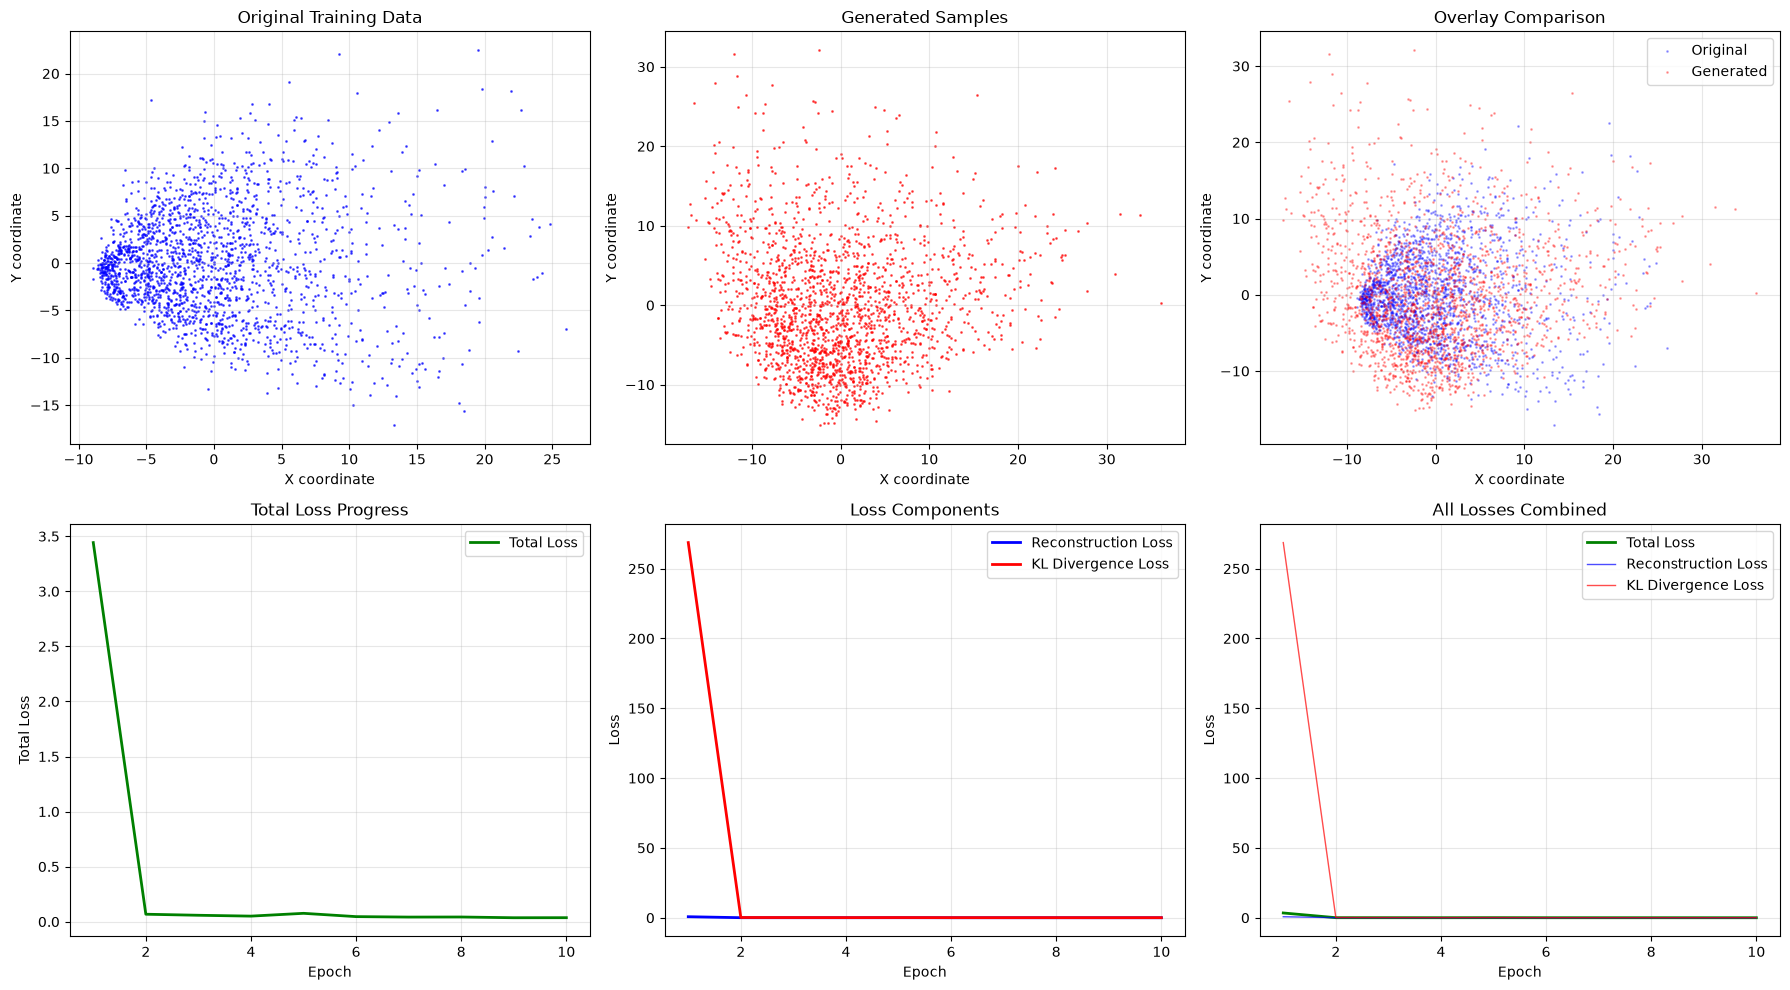

📈 Epoch 10 Summary:
   Total Loss: 0.0362
   Reconstruction Loss: 0.0283
   KL Divergence Loss: 0.0786
   Beta: 0.100
   Learning Rate: 0.000500

📊 Epoch 11/300
----------------------------------------
Epoch: 11 [0/60000 (0%)]	Total Loss: 0.034775	Recon Loss: 0.026665	KL Loss: 0.073730	Beta: 0.110
Epoch: 11 [51200/60000 (85%)]	Total Loss: 0.038905	Recon Loss: 0.029610	KL Loss: 0.084501	Beta: 0.110
====> Epoch: 11 Average Total Loss: 0.0364, Average Recon Loss: 0.0281, Average KL Loss: 0.0750, Beta: 0.110
📈 Epoch 11 Summary:
   Total Loss: 0.0364
   Reconstruction Loss: 0.0281
   KL Divergence Loss: 0.0750
   Beta: 0.110
   Learning Rate: 0.000500

📊 Epoch 12/300
----------------------------------------
Epoch: 12 [0/60000 (0%)]	Total Loss: 0.036717	Recon Loss: 0.028135	KL Loss: 0.071520	Beta: 0.120
Epoch: 12 [51200/60000 (85%)]	Total Loss: 0.033407	Recon Loss: 0.025500	KL Loss: 0.065892	Beta: 0.120
====> Epoch: 12 Average Total Loss: 0.0341, Average Recon Loss: 0.0262, Average KL Loss: 

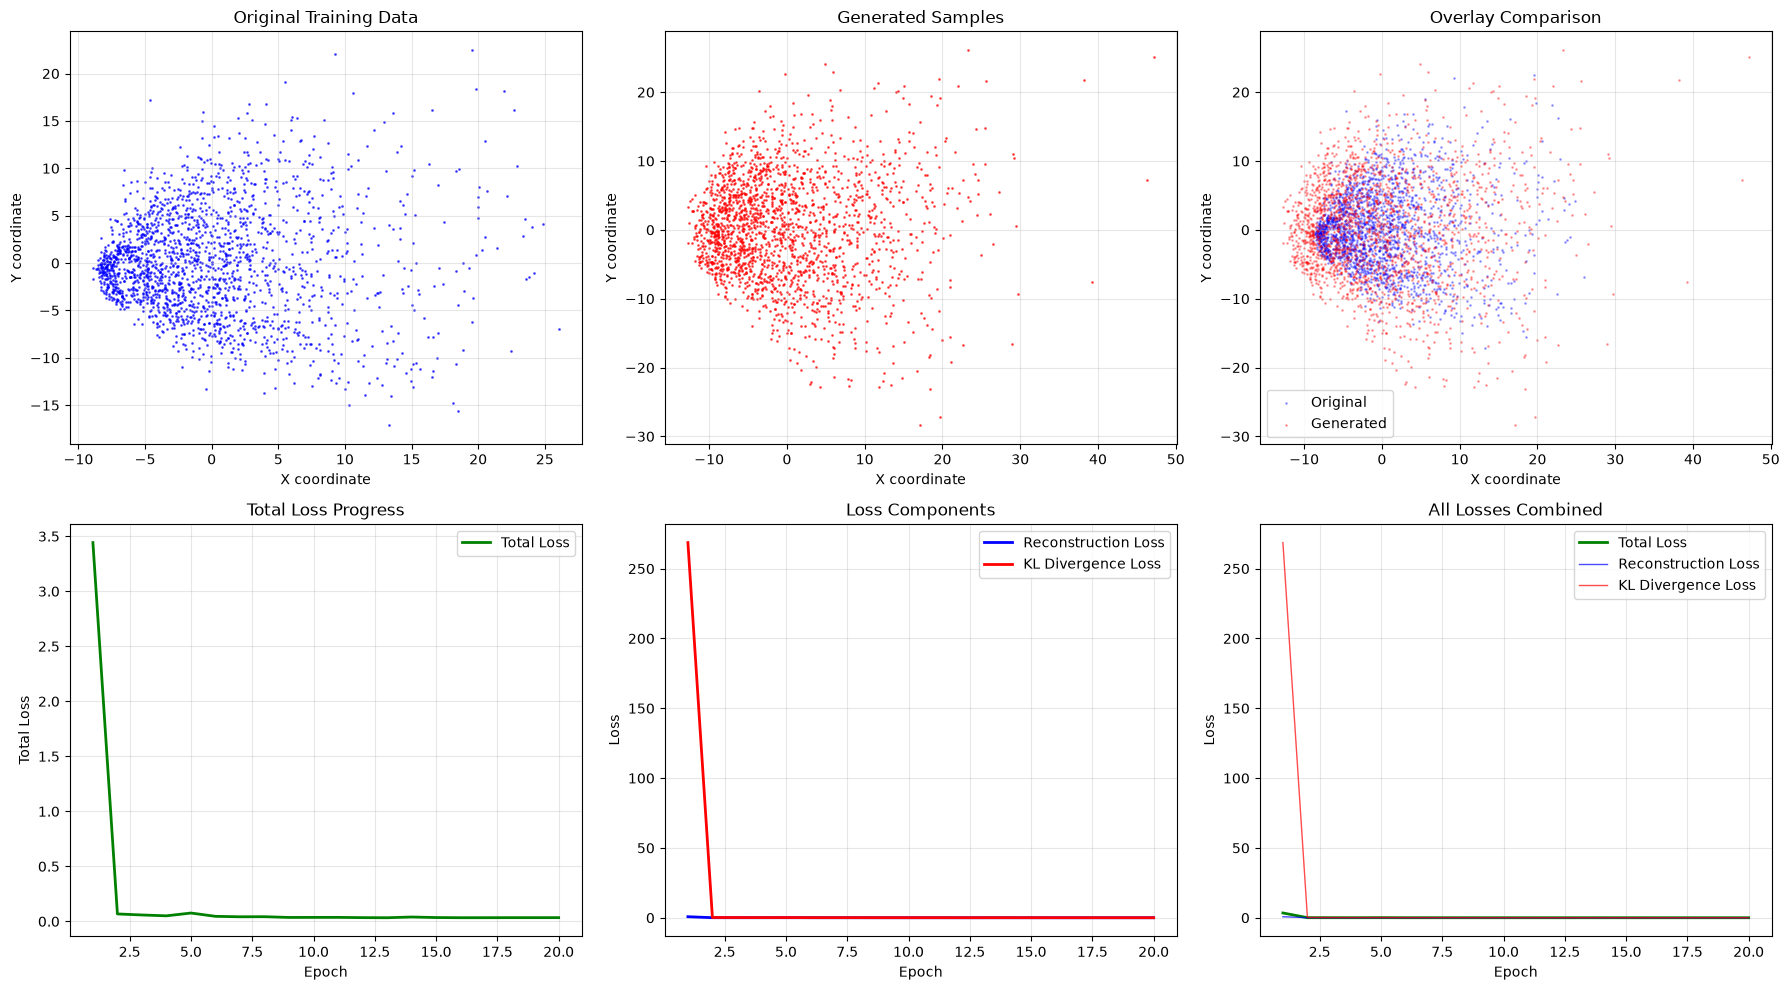

📈 Epoch 20 Summary:
   Total Loss: 0.0340
   Reconstruction Loss: 0.0236
   KL Divergence Loss: 0.0520
   Beta: 0.200
   Learning Rate: 0.000500

📊 Epoch 21/300
----------------------------------------
Epoch: 21 [0/60000 (0%)]	Total Loss: 0.034929	Recon Loss: 0.023912	KL Loss: 0.052462	Beta: 0.210
Epoch: 21 [51200/60000 (85%)]	Total Loss: 0.034179	Recon Loss: 0.023574	KL Loss: 0.050502	Beta: 0.210
====> Epoch: 21 Average Total Loss: 0.0342, Average Recon Loss: 0.0235, Average KL Loss: 0.0510, Beta: 0.210
📈 Epoch 21 Summary:
   Total Loss: 0.0342
   Reconstruction Loss: 0.0235
   KL Divergence Loss: 0.0510
   Beta: 0.210
   Learning Rate: 0.000500

📊 Epoch 22/300
----------------------------------------
Epoch: 22 [0/60000 (0%)]	Total Loss: 0.033858	Recon Loss: 0.022547	KL Loss: 0.051412	Beta: 0.220
Epoch: 22 [51200/60000 (85%)]	Total Loss: 0.034711	Recon Loss: 0.023736	KL Loss: 0.049889	Beta: 0.220
====> Epoch: 22 Average Total Loss: 0.0346, Average Recon Loss: 0.0236, Average KL Loss: 

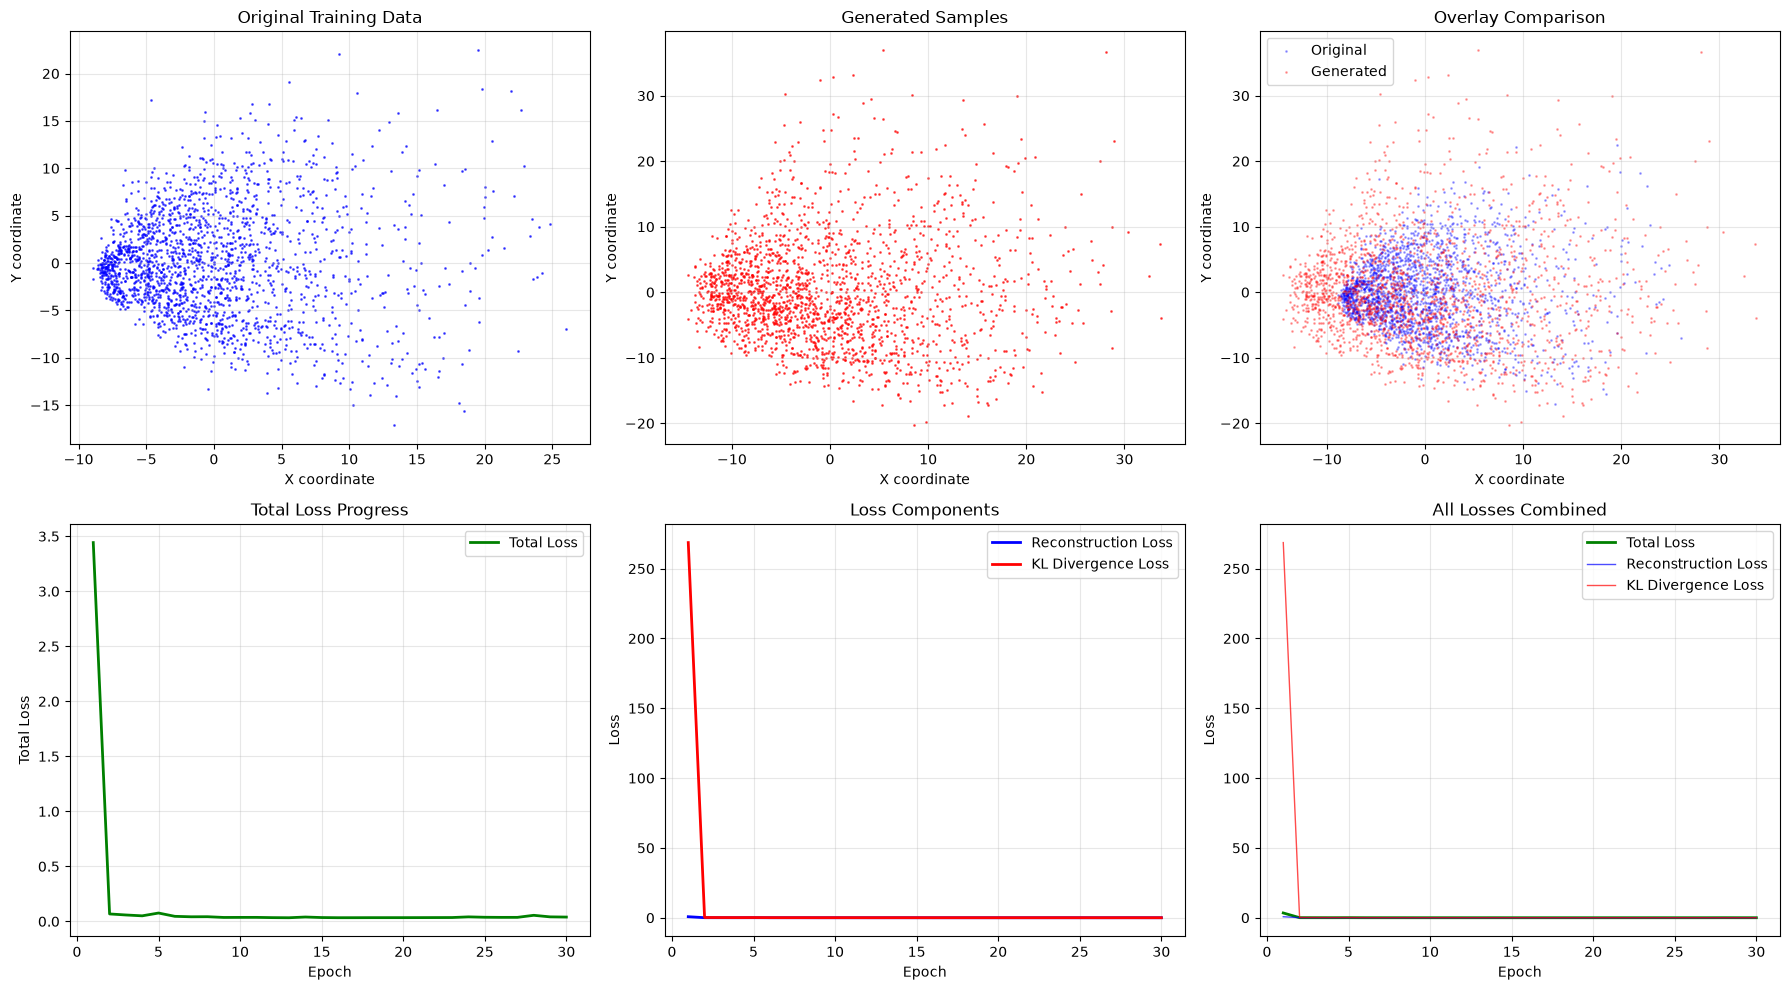

📈 Epoch 30 Summary:
   Total Loss: 0.0392
   Reconstruction Loss: 0.0271
   KL Divergence Loss: 0.0403
   Beta: 0.300
   Learning Rate: 0.000500

📊 Epoch 31/300
----------------------------------------
Epoch: 31 [0/60000 (0%)]	Total Loss: 0.038445	Recon Loss: 0.025727	KL Loss: 0.041024	Beta: 0.310
Epoch: 31 [51200/60000 (85%)]	Total Loss: 0.038408	Recon Loss: 0.025970	KL Loss: 0.040121	Beta: 0.310
====> Epoch: 31 Average Total Loss: 0.0386, Average Recon Loss: 0.0262, Average KL Loss: 0.0401, Beta: 0.310
📈 Epoch 31 Summary:
   Total Loss: 0.0386
   Reconstruction Loss: 0.0262
   KL Divergence Loss: 0.0401
   Beta: 0.310
   Learning Rate: 0.000500

📊 Epoch 32/300
----------------------------------------
Epoch: 32 [0/60000 (0%)]	Total Loss: 0.039088	Recon Loss: 0.026006	KL Loss: 0.040883	Beta: 0.320
Epoch: 32 [51200/60000 (85%)]	Total Loss: 0.038429	Recon Loss: 0.025581	KL Loss: 0.040150	Beta: 0.320
====> Epoch: 32 Average Total Loss: 0.0386, Average Recon Loss: 0.0259, Average KL Loss: 

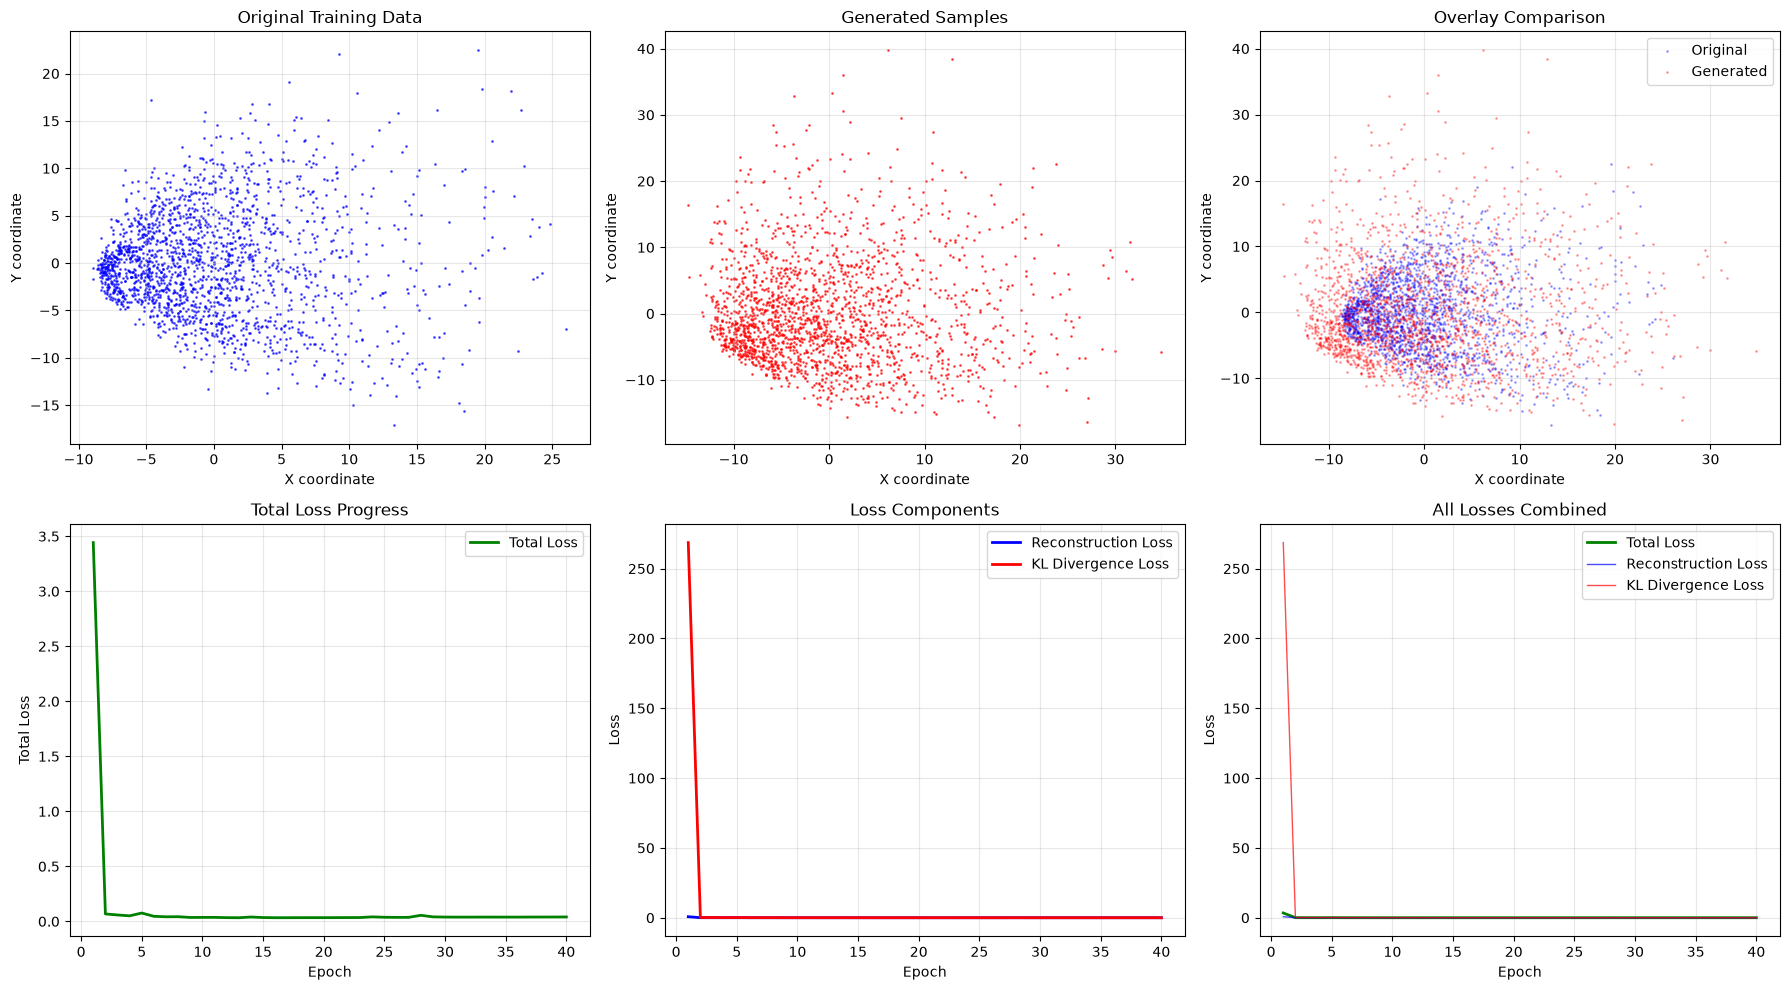

📈 Epoch 40 Summary:
   Total Loss: 0.0401
   Reconstruction Loss: 0.0254
   KL Divergence Loss: 0.0368
   Beta: 0.400
   Learning Rate: 0.000250

📊 Epoch 41/300
----------------------------------------
Epoch: 41 [0/60000 (0%)]	Total Loss: 0.040085	Recon Loss: 0.025008	KL Loss: 0.036773	Beta: 0.410
Epoch: 41 [51200/60000 (85%)]	Total Loss: 0.040751	Recon Loss: 0.025508	KL Loss: 0.037176	Beta: 0.410
====> Epoch: 41 Average Total Loss: 0.0404, Average Recon Loss: 0.0255, Average KL Loss: 0.0364, Beta: 0.410
📈 Epoch 41 Summary:
   Total Loss: 0.0404
   Reconstruction Loss: 0.0255
   KL Divergence Loss: 0.0364
   Beta: 0.410
   Learning Rate: 0.000250

📊 Epoch 42/300
----------------------------------------
Epoch: 42 [0/60000 (0%)]	Total Loss: 0.041015	Recon Loss: 0.025696	KL Loss: 0.036472	Beta: 0.420
Epoch: 42 [51200/60000 (85%)]	Total Loss: 0.041273	Recon Loss: 0.026099	KL Loss: 0.036131	Beta: 0.420
====> Epoch: 42 Average Total Loss: 0.0408, Average Recon Loss: 0.0257, Average KL Loss: 

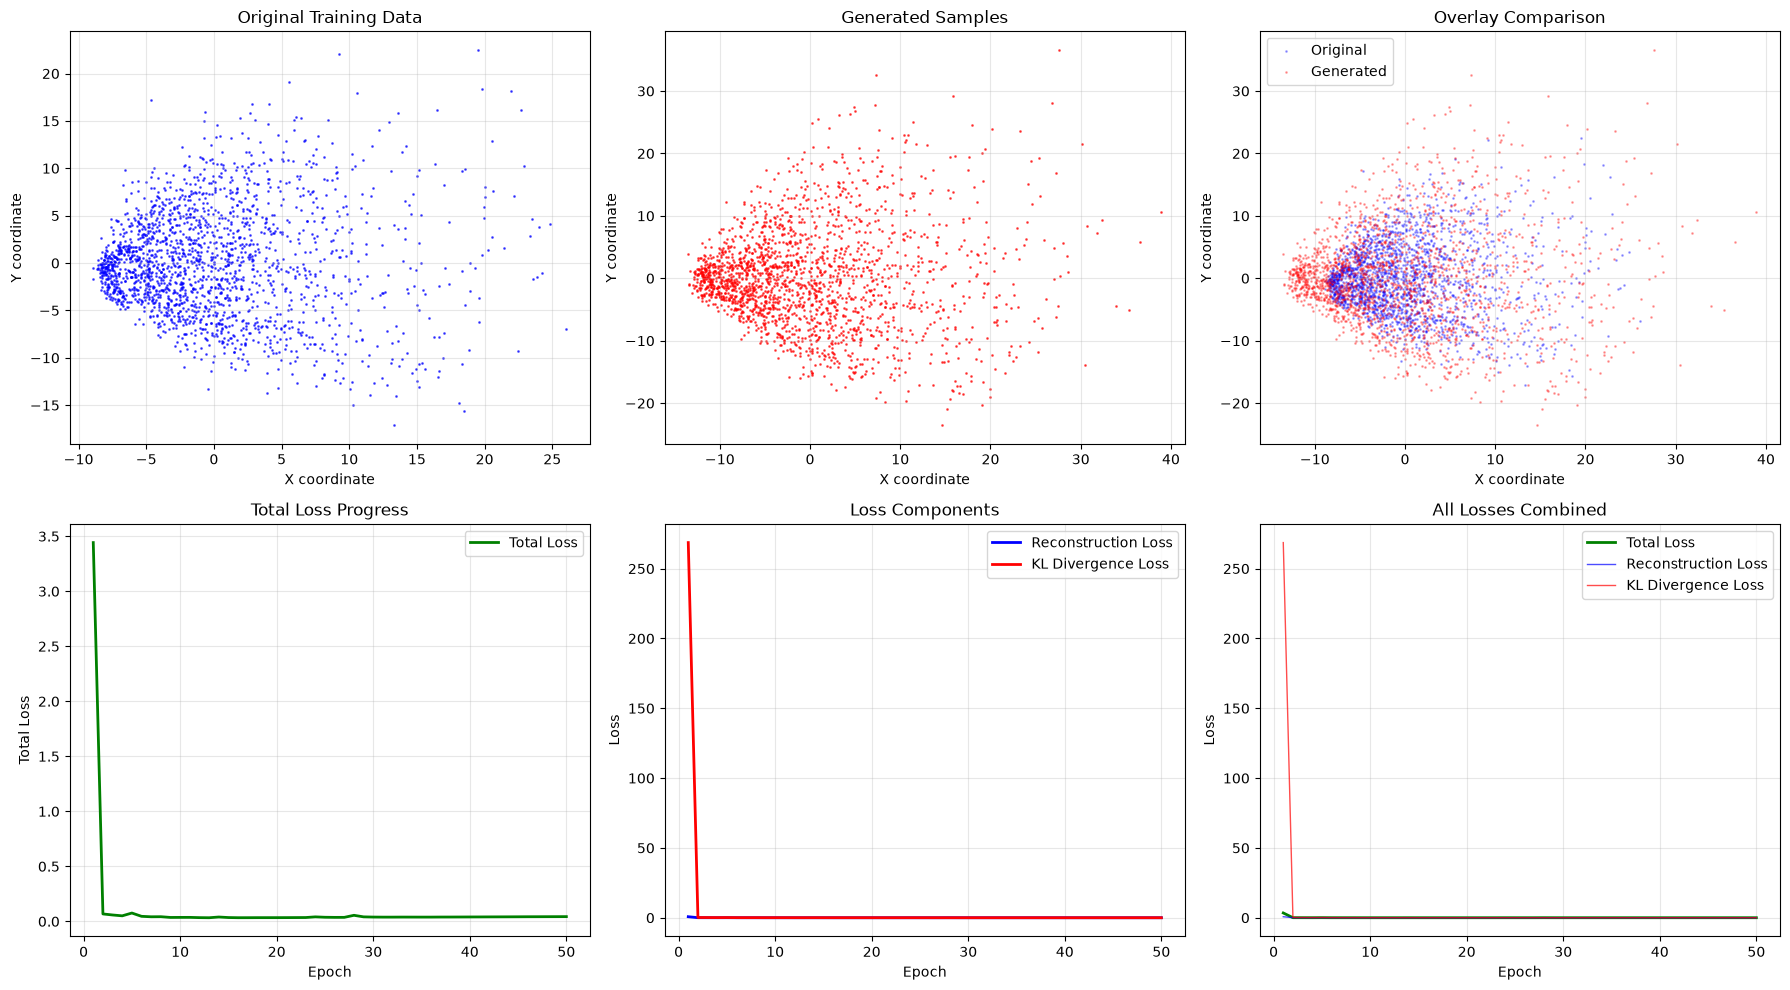

📈 Epoch 50 Summary:
   Total Loss: 0.0432
   Reconstruction Loss: 0.0269
   KL Divergence Loss: 0.0325
   Beta: 0.500
   Learning Rate: 0.000250

📊 Epoch 51/300
----------------------------------------
Epoch: 51 [0/60000 (0%)]	Total Loss: 0.043585	Recon Loss: 0.027331	KL Loss: 0.032542	Beta: 0.500
Epoch: 51 [51200/60000 (85%)]	Total Loss: 0.043001	Recon Loss: 0.026782	KL Loss: 0.032471	Beta: 0.500
====> Epoch: 51 Average Total Loss: 0.0432, Average Recon Loss: 0.0270, Average KL Loss: 0.0324, Beta: 0.500
📈 Epoch 51 Summary:
   Total Loss: 0.0432
   Reconstruction Loss: 0.0270
   KL Divergence Loss: 0.0324
   Beta: 0.500
   Learning Rate: 0.000250

📊 Epoch 52/300
----------------------------------------
Epoch: 52 [0/60000 (0%)]	Total Loss: 0.043123	Recon Loss: 0.027181	KL Loss: 0.032010	Beta: 0.498
Epoch: 52 [51200/60000 (85%)]	Total Loss: 0.044056	Recon Loss: 0.027715	KL Loss: 0.032811	Beta: 0.498
====> Epoch: 52 Average Total Loss: 0.0430, Average Recon Loss: 0.0268, Average KL Loss: 

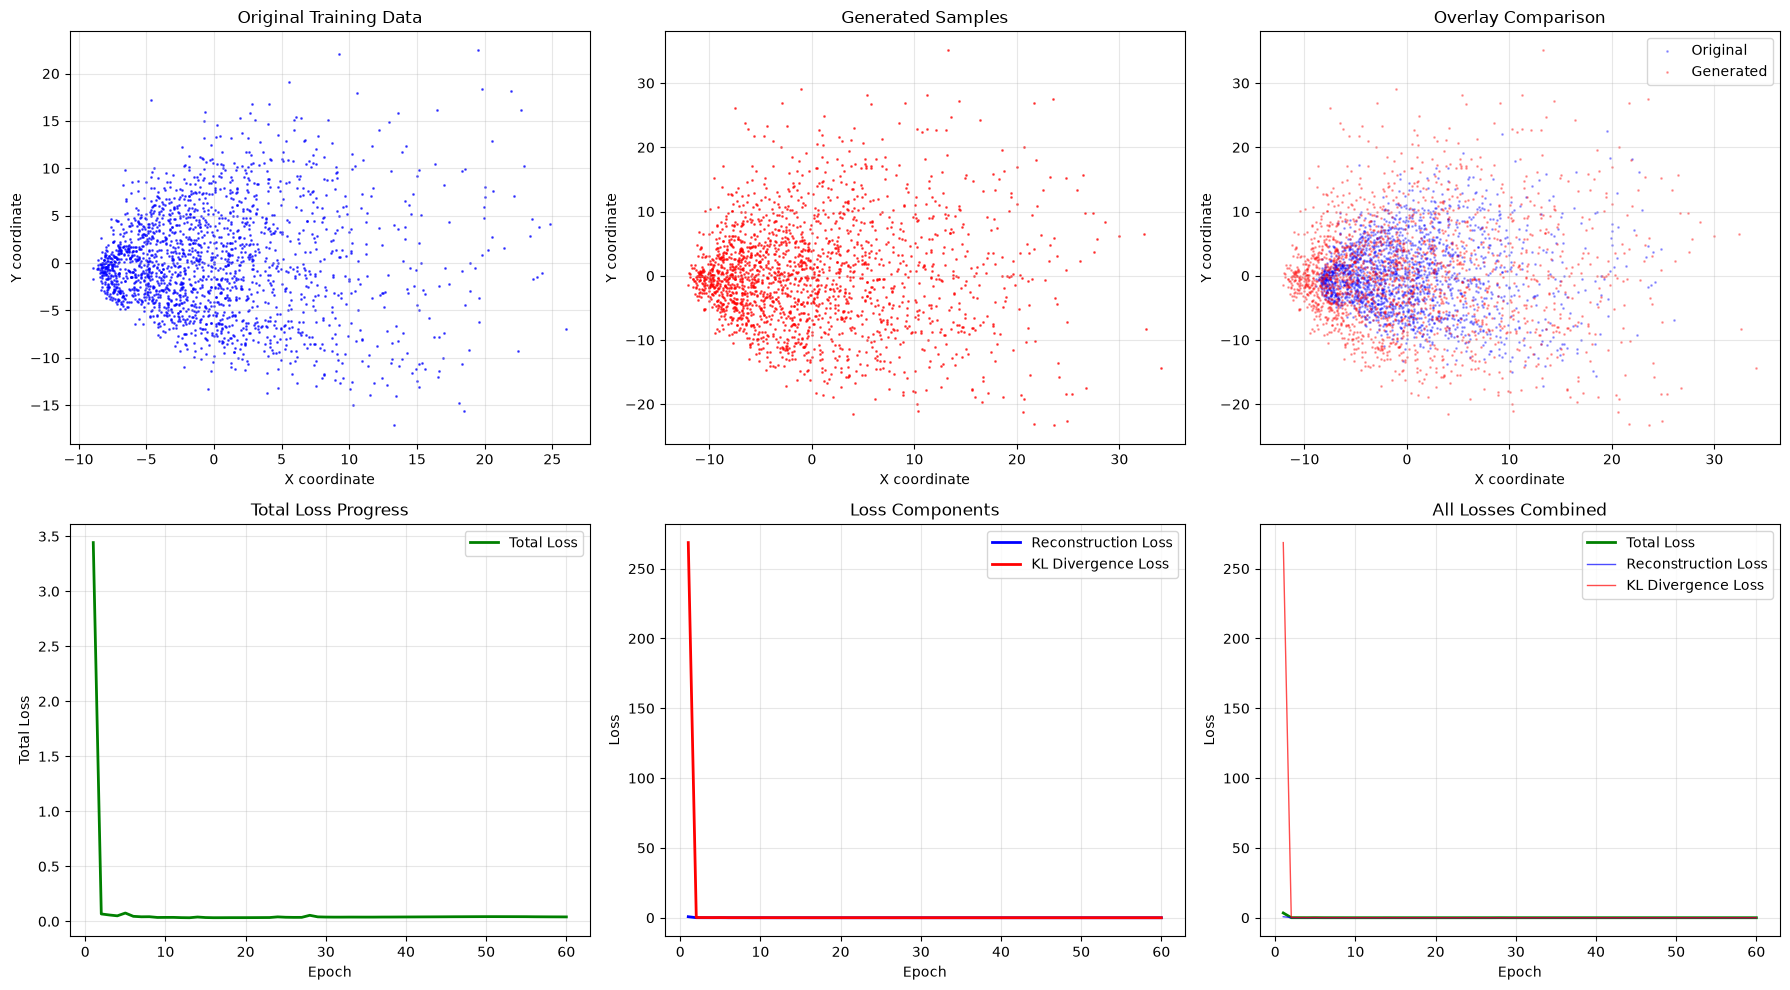

📈 Epoch 60 Summary:
   Total Loss: 0.0406
   Reconstruction Loss: 0.0249
   KL Divergence Loss: 0.0348
   Beta: 0.452
   Learning Rate: 0.000125

📊 Epoch 61/300
----------------------------------------
Epoch: 61 [0/60000 (0%)]	Total Loss: 0.039448	Recon Loss: 0.024176	KL Loss: 0.034503	Beta: 0.443
Epoch: 61 [51200/60000 (85%)]	Total Loss: 0.040631	Recon Loss: 0.024791	KL Loss: 0.035785	Beta: 0.443
====> Epoch: 61 Average Total Loss: 0.0402, Average Recon Loss: 0.0247, Average KL Loss: 0.0352, Beta: 0.443
📈 Epoch 61 Summary:
   Total Loss: 0.0402
   Reconstruction Loss: 0.0247
   KL Divergence Loss: 0.0352
   Beta: 0.443
   Learning Rate: 0.000125

📊 Epoch 62/300
----------------------------------------
Epoch: 62 [0/60000 (0%)]	Total Loss: 0.039762	Recon Loss: 0.024618	KL Loss: 0.035035	Beta: 0.432
Epoch: 62 [51200/60000 (85%)]	Total Loss: 0.040440	Recon Loss: 0.024894	KL Loss: 0.035967	Beta: 0.432
====> Epoch: 62 Average Total Loss: 0.0399, Average Recon Loss: 0.0245, Average KL Loss: 

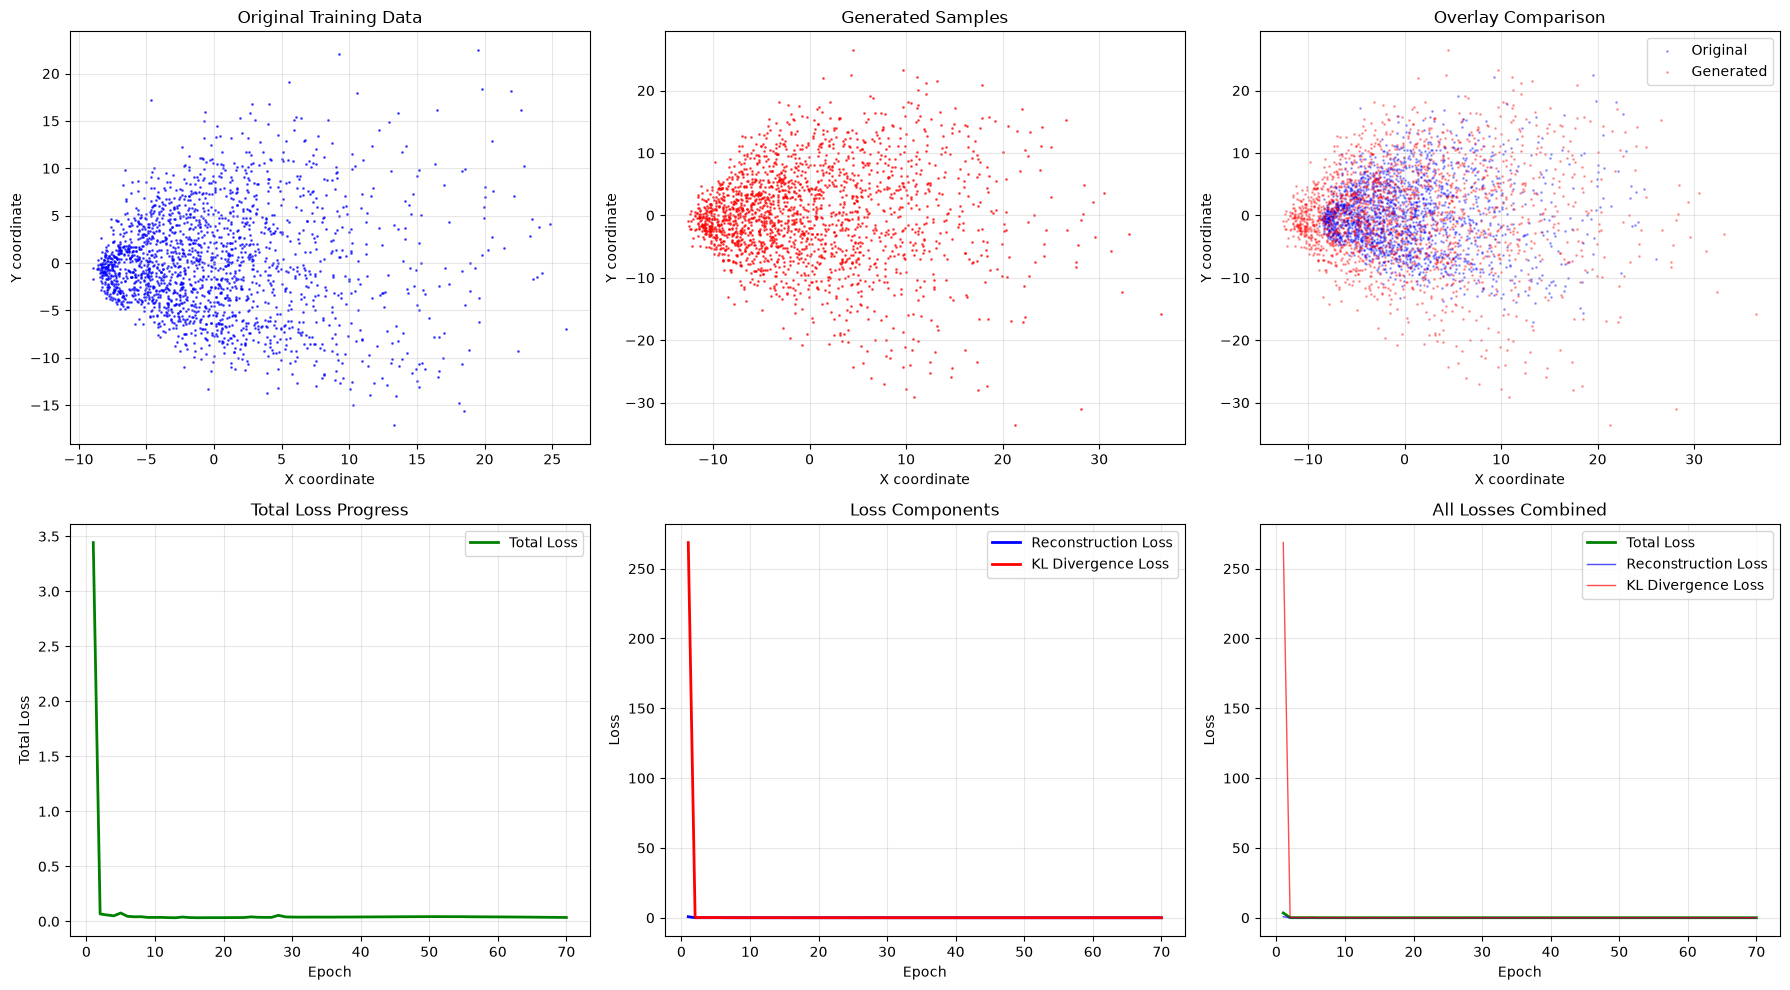

📈 Epoch 70 Summary:
   Total Loss: 0.0355
   Reconstruction Loss: 0.0220
   KL Divergence Loss: 0.0412
   Beta: 0.327
   Learning Rate: 0.000125

📊 Epoch 71/300
----------------------------------------
Epoch: 71 [0/60000 (0%)]	Total Loss: 0.035023	Recon Loss: 0.022115	KL Loss: 0.041346	Beta: 0.312
Epoch: 71 [51200/60000 (85%)]	Total Loss: 0.035539	Recon Loss: 0.022368	KL Loss: 0.042193	Beta: 0.312
====> Epoch: 71 Average Total Loss: 0.0348, Average Recon Loss: 0.0217, Average KL Loss: 0.0420, Beta: 0.312
📈 Epoch 71 Summary:
   Total Loss: 0.0348
   Reconstruction Loss: 0.0217
   KL Divergence Loss: 0.0420
   Beta: 0.312
   Learning Rate: 0.000125

📊 Epoch 72/300
----------------------------------------
Epoch: 72 [0/60000 (0%)]	Total Loss: 0.033926	Recon Loss: 0.021406	KL Loss: 0.042177	Beta: 0.297
Epoch: 72 [51200/60000 (85%)]	Total Loss: 0.034326	Recon Loss: 0.021541	KL Loss: 0.043070	Beta: 0.297
====> Epoch: 72 Average Total Loss: 0.0341, Average Recon Loss: 0.0213, Average KL Loss: 

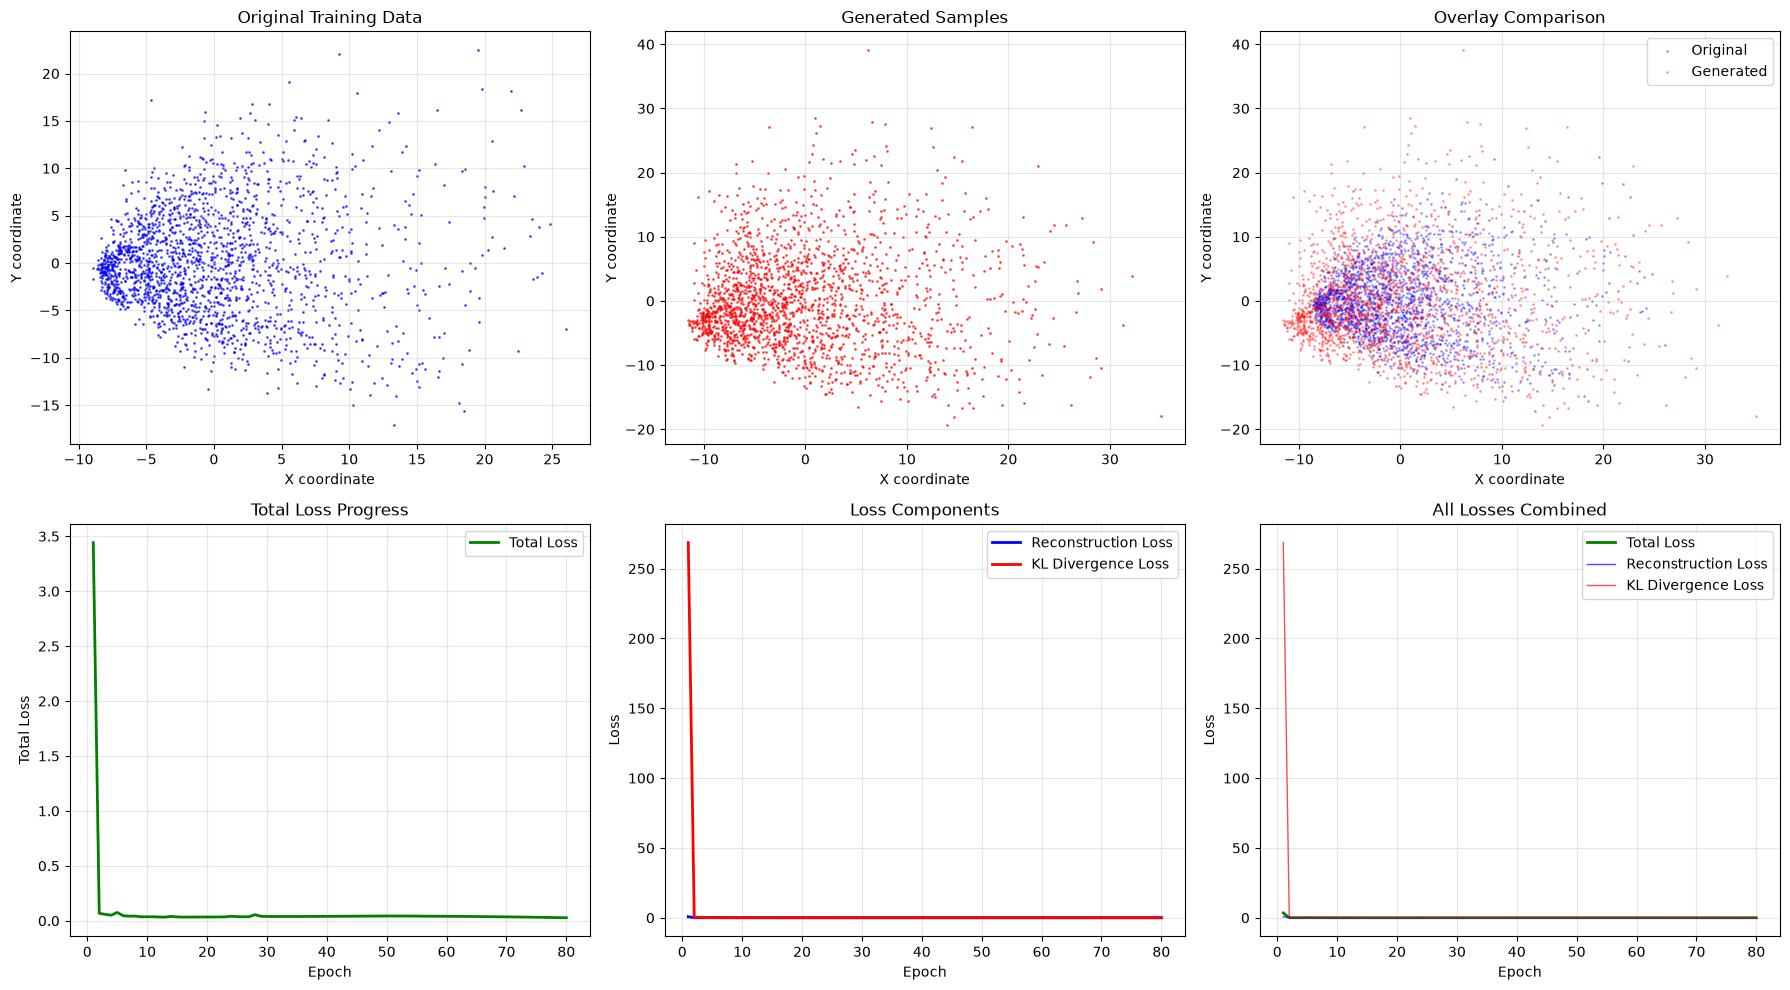

📈 Epoch 80 Summary:
   Total Loss: 0.0275
   Reconstruction Loss: 0.0182
   KL Divergence Loss: 0.0538
   Beta: 0.173
   Learning Rate: 0.000125

📊 Epoch 81/300
----------------------------------------
Epoch: 81 [0/60000 (0%)]	Total Loss: 0.026354	Recon Loss: 0.017765	KL Loss: 0.054374	Beta: 0.158
Epoch: 81 [51200/60000 (85%)]	Total Loss: 0.026752	Recon Loss: 0.018075	KL Loss: 0.054926	Beta: 0.158
====> Epoch: 81 Average Total Loss: 0.0266, Average Recon Loss: 0.0178, Average KL Loss: 0.0556, Beta: 0.158
📈 Epoch 81 Summary:
   Total Loss: 0.0266
   Reconstruction Loss: 0.0178
   KL Divergence Loss: 0.0556
   Beta: 0.158
   Learning Rate: 0.000125

📊 Epoch 82/300
----------------------------------------
Epoch: 82 [0/60000 (0%)]	Total Loss: 0.026238	Recon Loss: 0.018189	KL Loss: 0.056067	Beta: 0.144
Epoch: 82 [51200/60000 (85%)]	Total Loss: 0.025296	Recon Loss: 0.017136	KL Loss: 0.056839	Beta: 0.144
====> Epoch: 82 Average Total Loss: 0.0257, Average Recon Loss: 0.0174, Average KL Loss: 

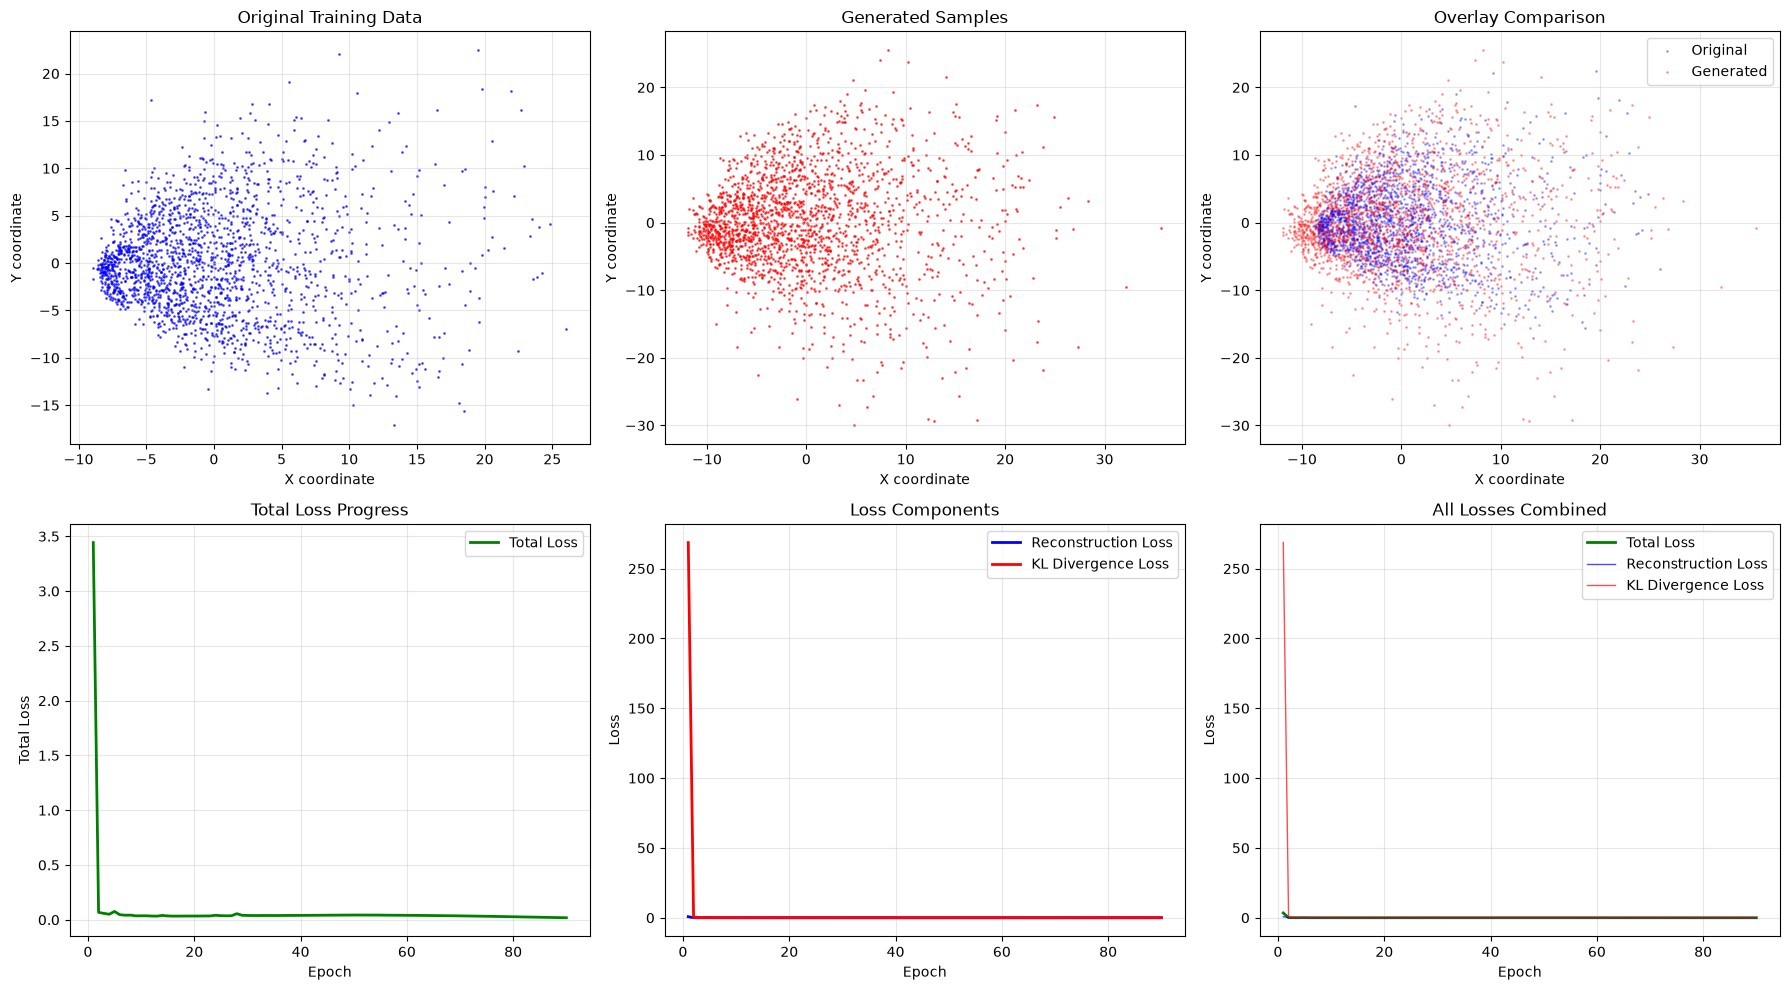

📈 Epoch 90 Summary:
   Total Loss: 0.0185
   Reconstruction Loss: 0.0147
   KL Divergence Loss: 0.0790
   Beta: 0.048
   Learning Rate: 0.000125

📊 Epoch 91/300
----------------------------------------
Epoch: 91 [0/60000 (0%)]	Total Loss: 0.017526	Recon Loss: 0.014463	KL Loss: 0.078682	Beta: 0.039
Epoch: 91 [51200/60000 (85%)]	Total Loss: 0.017531	Recon Loss: 0.014289	KL Loss: 0.083316	Beta: 0.039
====> Epoch: 91 Average Total Loss: 0.0177, Average Recon Loss: 0.0144, Average KL Loss: 0.0831, Beta: 0.039
📈 Epoch 91 Summary:
   Total Loss: 0.0177
   Reconstruction Loss: 0.0144
   KL Divergence Loss: 0.0831
   Beta: 0.039
   Learning Rate: 0.000125

📊 Epoch 92/300
----------------------------------------
Epoch: 92 [0/60000 (0%)]	Total Loss: 0.016595	Recon Loss: 0.014013	KL Loss: 0.083503	Beta: 0.031
Epoch: 92 [51200/60000 (85%)]	Total Loss: 0.016991	Recon Loss: 0.014259	KL Loss: 0.088339	Beta: 0.031
====> Epoch: 92 Average Total Loss: 0.0168, Average Recon Loss: 0.0141, Average KL Loss: 

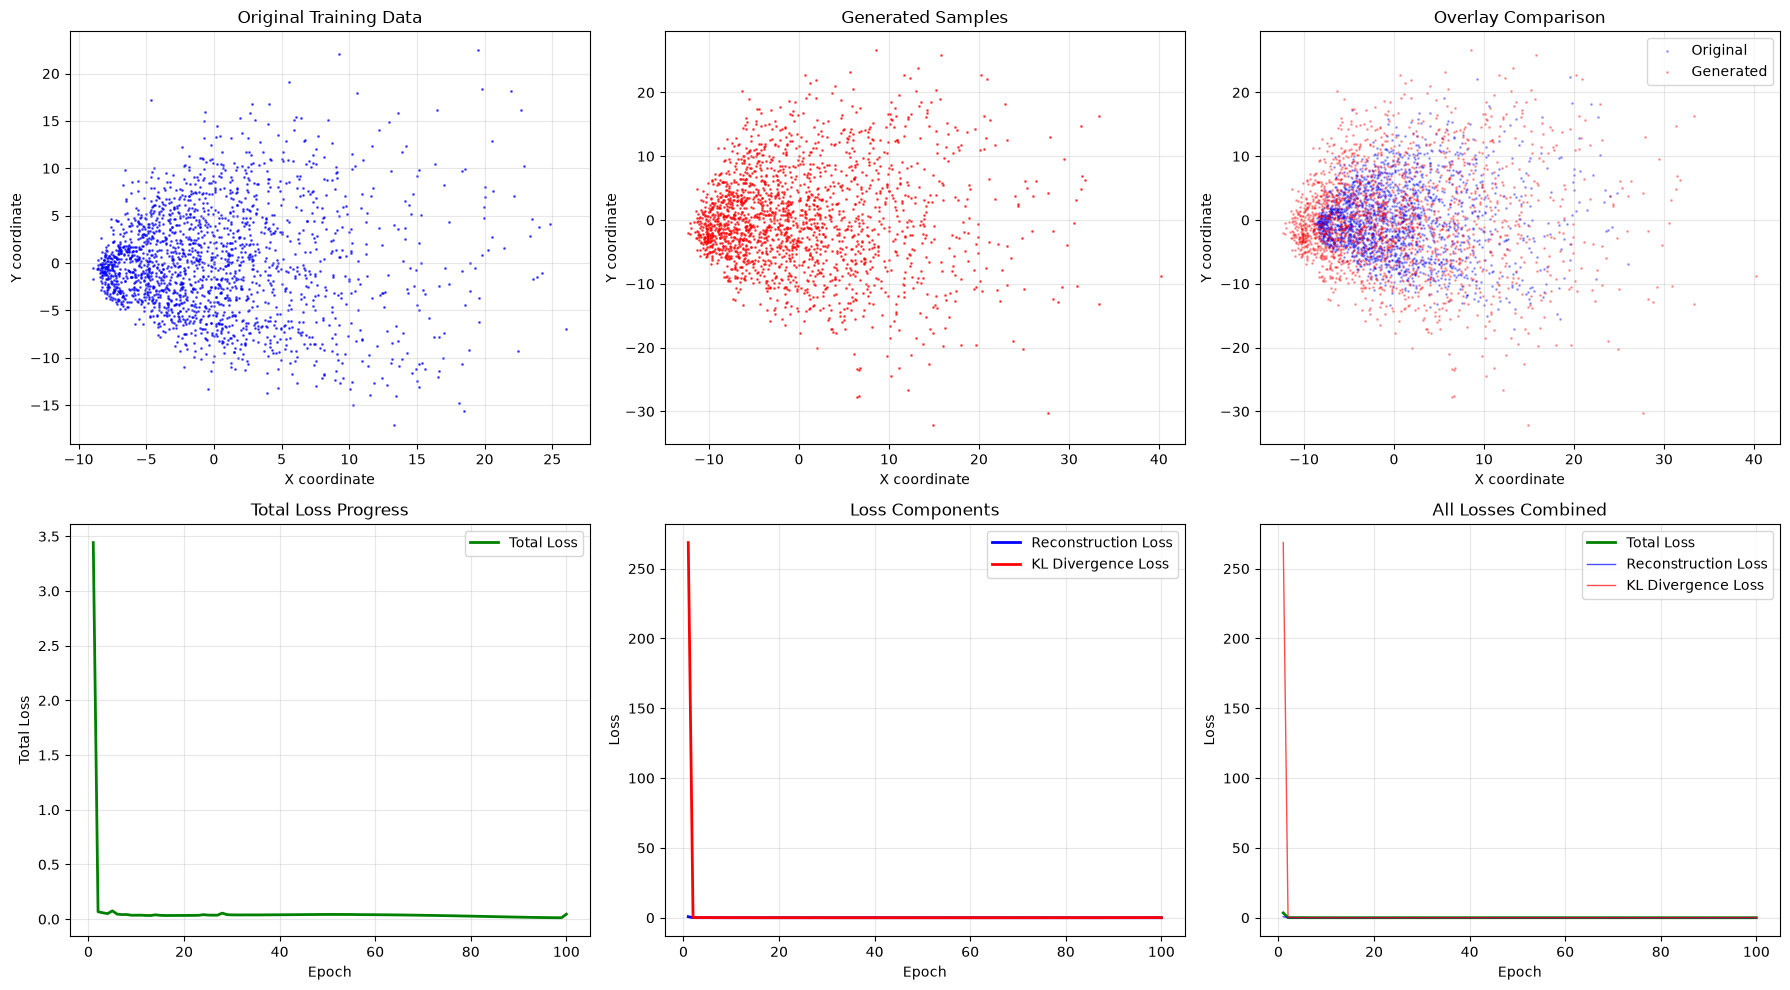

📈 Epoch 100 Summary:
   Total Loss: 0.0459
   Reconstruction Loss: 0.0259
   KL Divergence Loss: 0.0399
   Beta: 0.500
   Learning Rate: 0.000125

📊 Epoch 101/300
----------------------------------------
Epoch: 101 [0/60000 (0%)]	Total Loss: 0.041956	Recon Loss: 0.024029	KL Loss: 0.035890	Beta: 0.500
Epoch: 101 [51200/60000 (85%)]	Total Loss: 0.042236	Recon Loss: 0.024528	KL Loss: 0.035451	Beta: 0.500
====> Epoch: 101 Average Total Loss: 0.0419, Average Recon Loss: 0.0241, Average KL Loss: 0.0356, Beta: 0.500
📈 Epoch 101 Summary:
   Total Loss: 0.0419
   Reconstruction Loss: 0.0241
   KL Divergence Loss: 0.0356
   Beta: 0.500
   Learning Rate: 0.000125

📊 Epoch 102/300
----------------------------------------
Epoch: 102 [0/60000 (0%)]	Total Loss: 0.042206	Recon Loss: 0.024471	KL Loss: 0.035612	Beta: 0.498
Epoch: 102 [51200/60000 (85%)]	Total Loss: 0.041138	Recon Loss: 0.023655	KL Loss: 0.035104	Beta: 0.498
====> Epoch: 102 Average Total Loss: 0.0416, Average Recon Loss: 0.0240, Average

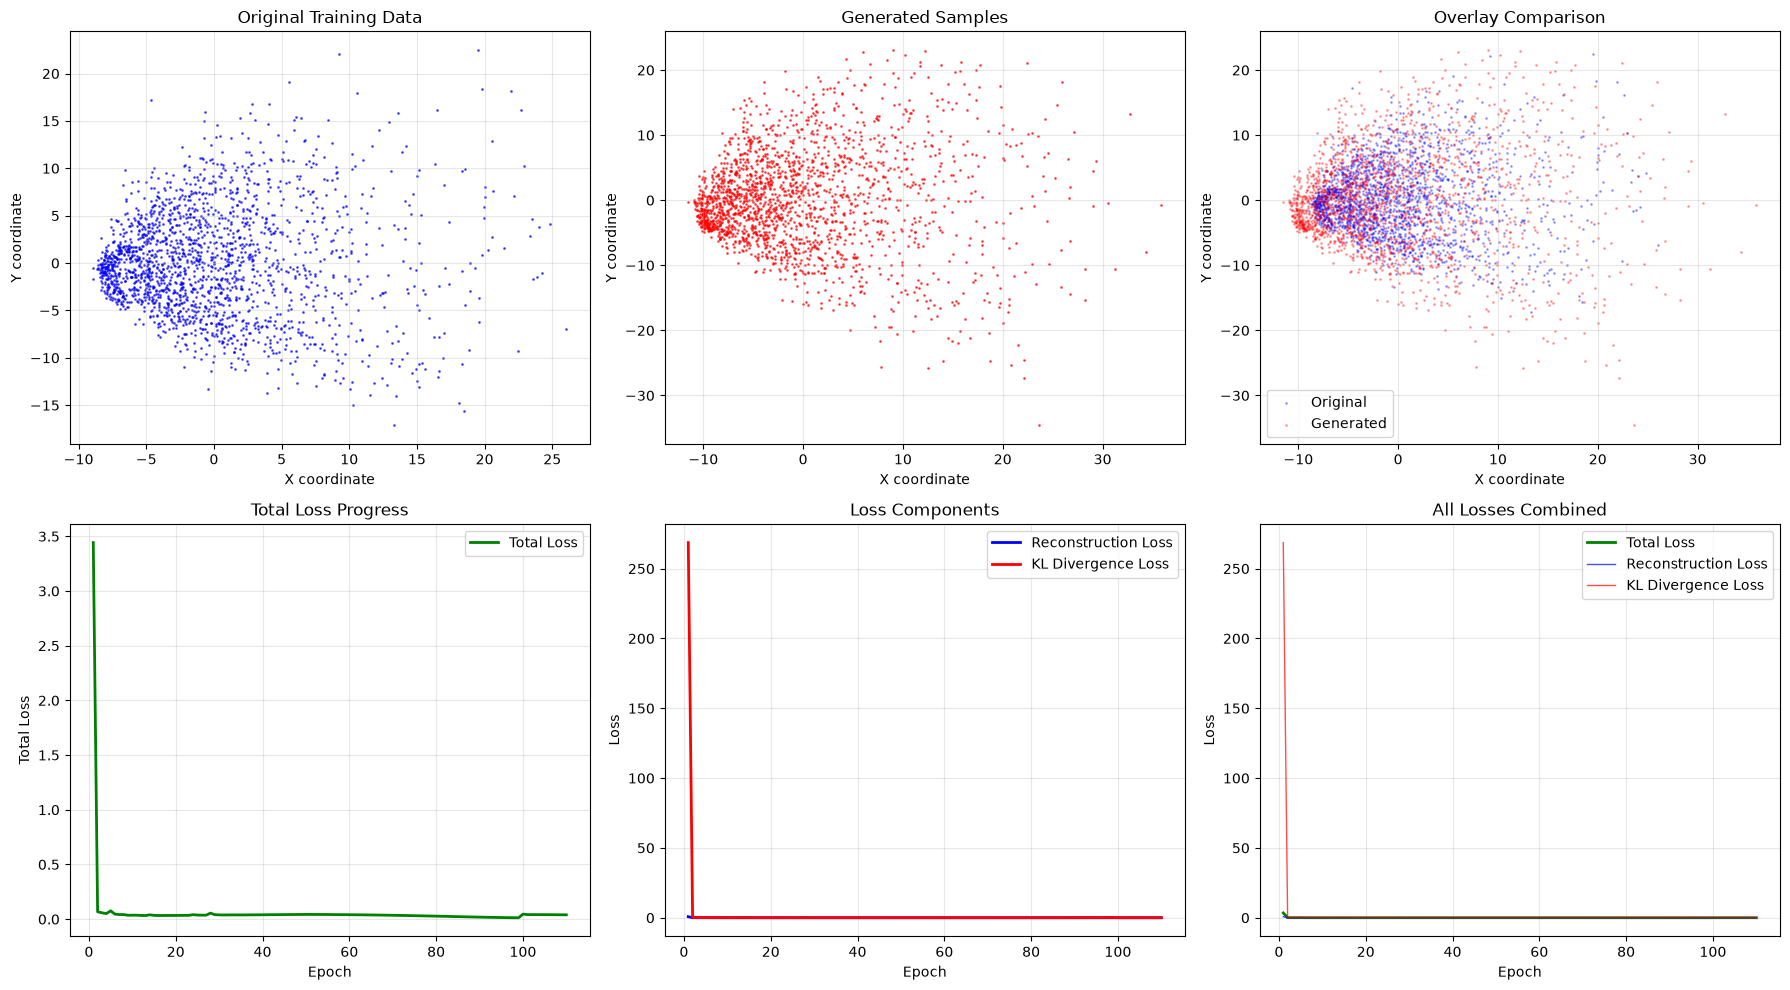

📈 Epoch 110 Summary:
   Total Loss: 0.0396
   Reconstruction Loss: 0.0231
   KL Divergence Loss: 0.0365
   Beta: 0.452
   Learning Rate: 0.000125

📊 Epoch 111/300
----------------------------------------
Epoch: 111 [0/60000 (0%)]	Total Loss: 0.039021	Recon Loss: 0.022911	KL Loss: 0.036397	Beta: 0.443
Epoch: 111 [51200/60000 (85%)]	Total Loss: 0.039492	Recon Loss: 0.023254	KL Loss: 0.036685	Beta: 0.443
====> Epoch: 111 Average Total Loss: 0.0392, Average Recon Loss: 0.0229, Average KL Loss: 0.0370, Beta: 0.443
📈 Epoch 111 Summary:
   Total Loss: 0.0392
   Reconstruction Loss: 0.0229
   KL Divergence Loss: 0.0370
   Beta: 0.443
   Learning Rate: 0.000125

📊 Epoch 112/300
----------------------------------------
Epoch: 112 [0/60000 (0%)]	Total Loss: 0.038414	Recon Loss: 0.022383	KL Loss: 0.037088	Beta: 0.432
Epoch: 112 [51200/60000 (85%)]	Total Loss: 0.038534	Recon Loss: 0.022349	KL Loss: 0.037445	Beta: 0.432
====> Epoch: 112 Average Total Loss: 0.0388, Average Recon Loss: 0.0227, Average

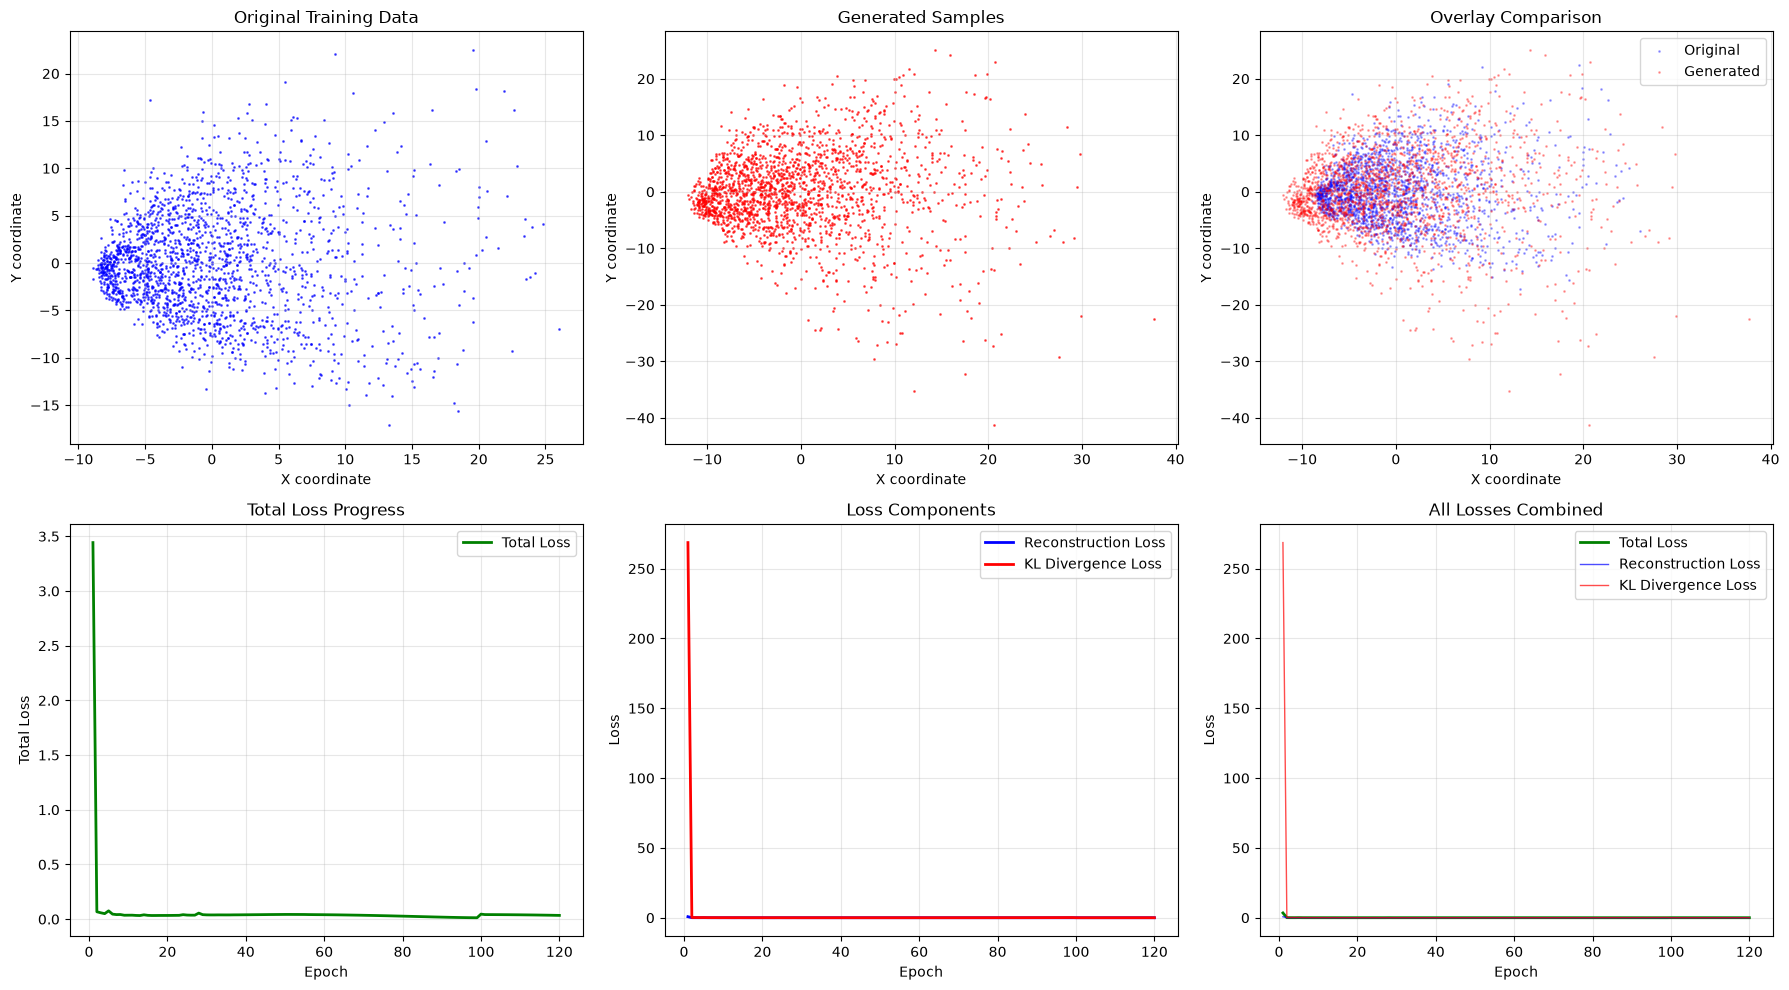

📈 Epoch 120 Summary:
   Total Loss: 0.0344
   Reconstruction Loss: 0.0204
   KL Divergence Loss: 0.0425
   Beta: 0.327
   Learning Rate: 0.000063

📊 Epoch 121/300
----------------------------------------
Epoch: 121 [0/60000 (0%)]	Total Loss: 0.033701	Recon Loss: 0.020332	KL Loss: 0.042826	Beta: 0.312
Epoch: 121 [51200/60000 (85%)]	Total Loss: 0.033308	Recon Loss: 0.019562	KL Loss: 0.044034	Beta: 0.312
====> Epoch: 121 Average Total Loss: 0.0332, Average Recon Loss: 0.0196, Average KL Loss: 0.0437, Beta: 0.312
📈 Epoch 121 Summary:
   Total Loss: 0.0332
   Reconstruction Loss: 0.0196
   KL Divergence Loss: 0.0437
   Beta: 0.312
   Learning Rate: 0.000063

📊 Epoch 122/300
----------------------------------------
Epoch: 122 [0/60000 (0%)]	Total Loss: 0.032495	Recon Loss: 0.019480	KL Loss: 0.043842	Beta: 0.297
Epoch: 122 [51200/60000 (85%)]	Total Loss: 0.032618	Recon Loss: 0.019316	KL Loss: 0.044811	Beta: 0.297
====> Epoch: 122 Average Total Loss: 0.0324, Average Recon Loss: 0.0191, Average

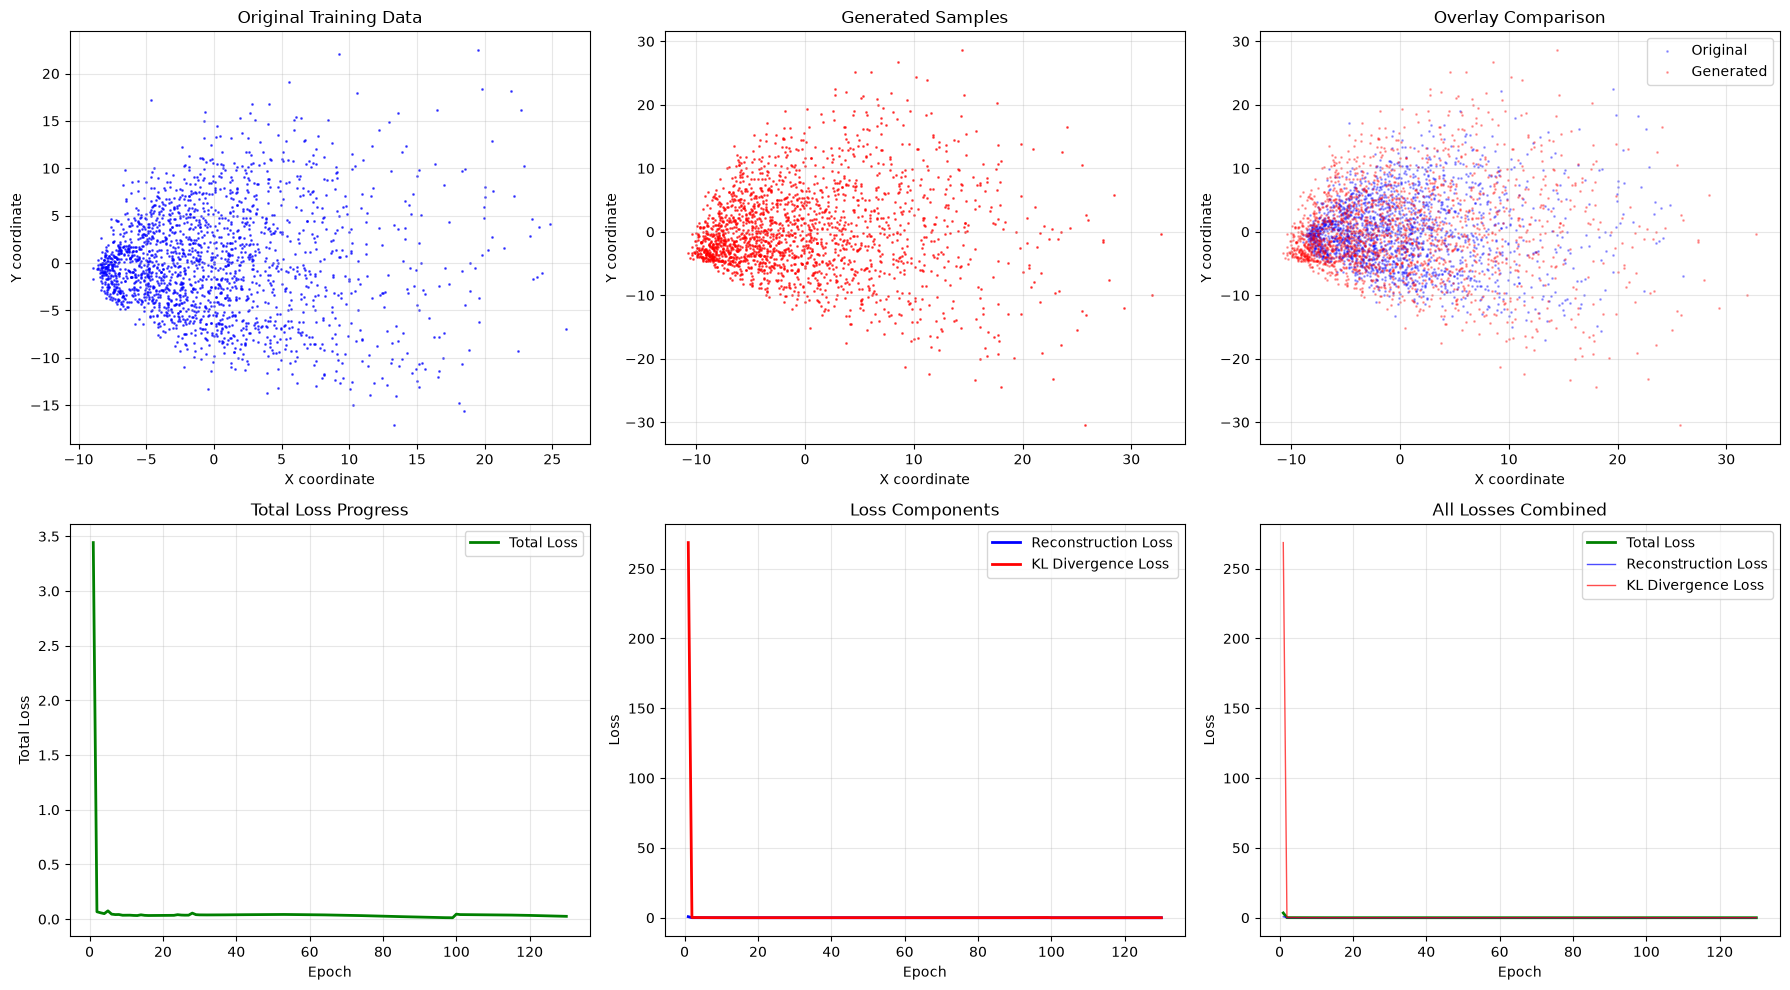

📈 Epoch 130 Summary:
   Total Loss: 0.0258
   Reconstruction Loss: 0.0163
   KL Divergence Loss: 0.0552
   Beta: 0.173
   Learning Rate: 0.000063

📊 Epoch 131/300
----------------------------------------
Epoch: 131 [0/60000 (0%)]	Total Loss: 0.024617	Recon Loss: 0.015837	KL Loss: 0.055583	Beta: 0.158
Epoch: 131 [51200/60000 (85%)]	Total Loss: 0.024913	Recon Loss: 0.015971	KL Loss: 0.056603	Beta: 0.158
====> Epoch: 131 Average Total Loss: 0.0249, Average Recon Loss: 0.0159, Average KL Loss: 0.0568, Beta: 0.158
📈 Epoch 131 Summary:
   Total Loss: 0.0249
   Reconstruction Loss: 0.0159
   KL Divergence Loss: 0.0568
   Beta: 0.158
   Learning Rate: 0.000063

📊 Epoch 132/300
----------------------------------------
Epoch: 132 [0/60000 (0%)]	Total Loss: 0.024070	Recon Loss: 0.015821	KL Loss: 0.057464	Beta: 0.144
Epoch: 132 [51200/60000 (85%)]	Total Loss: 0.024385	Recon Loss: 0.015915	KL Loss: 0.058998	Beta: 0.144
====> Epoch: 132 Average Total Loss: 0.0241, Average Recon Loss: 0.0156, Average

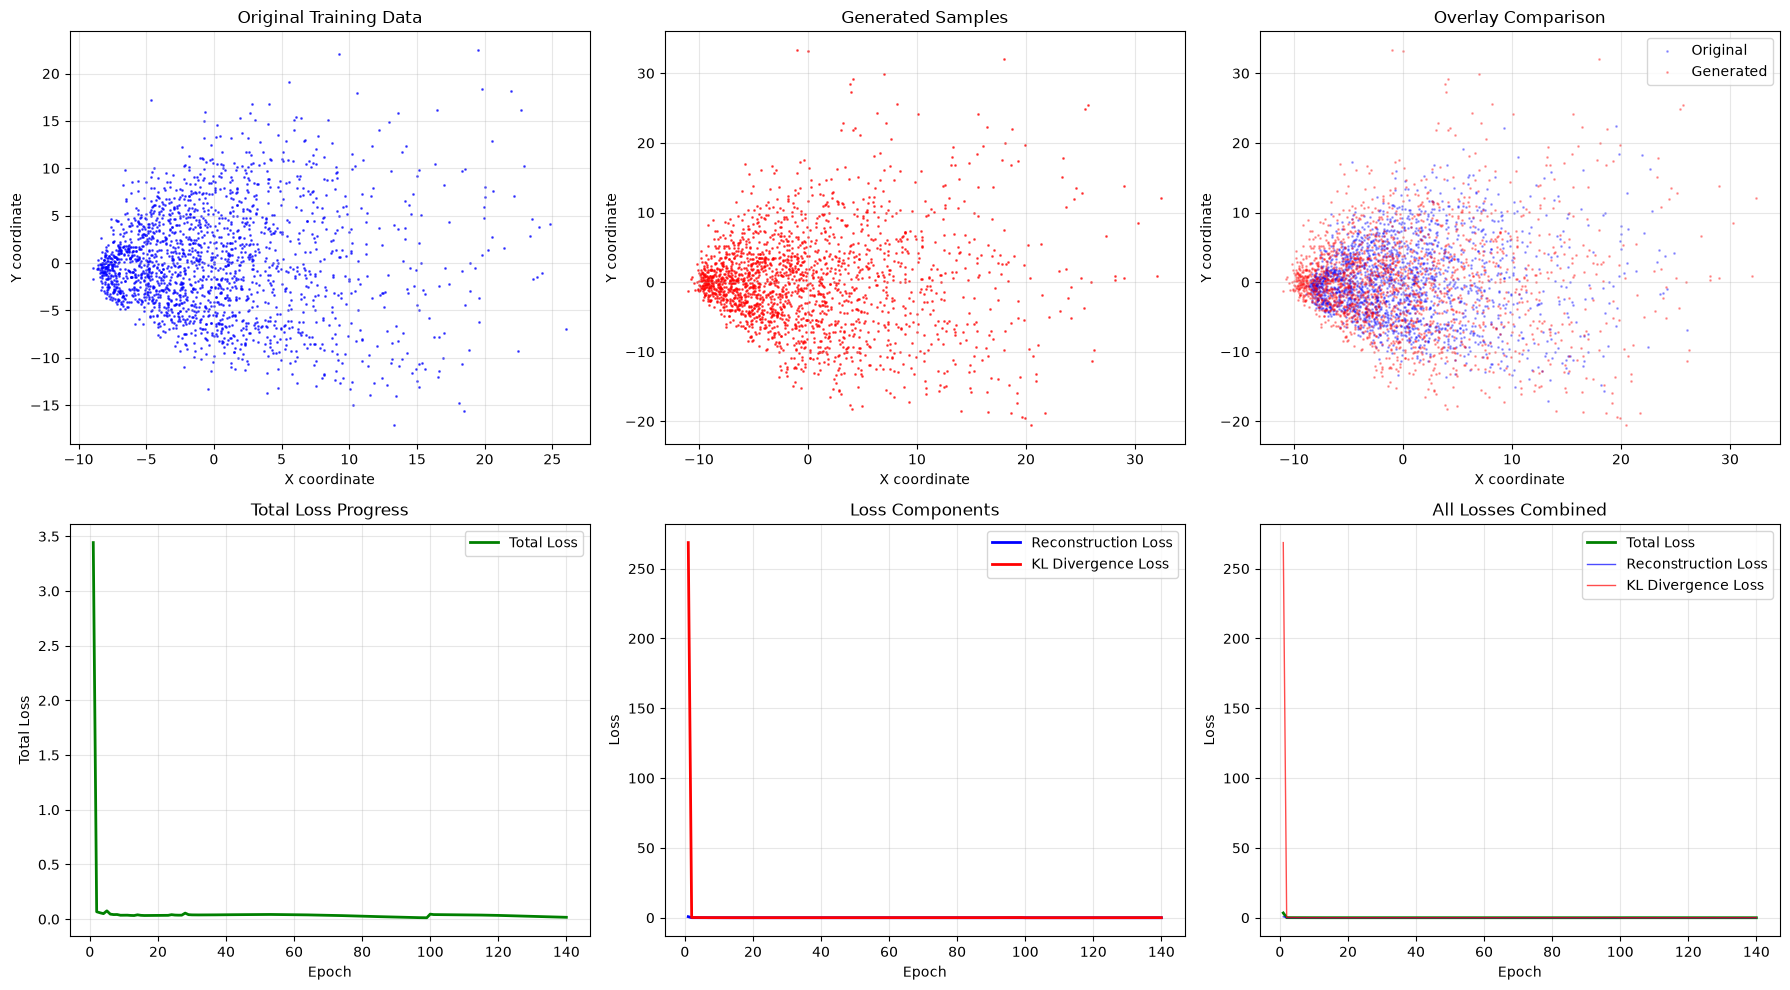

📈 Epoch 140 Summary:
   Total Loss: 0.0169
   Reconstruction Loss: 0.0131
   KL Divergence Loss: 0.0797
   Beta: 0.048
   Learning Rate: 0.000063

📊 Epoch 141/300
----------------------------------------
Epoch: 141 [0/60000 (0%)]	Total Loss: 0.016115	Recon Loss: 0.013007	KL Loss: 0.079860	Beta: 0.039
Epoch: 141 [51200/60000 (85%)]	Total Loss: 0.015840	Recon Loss: 0.012592	KL Loss: 0.083467	Beta: 0.039
====> Epoch: 141 Average Total Loss: 0.0162, Average Recon Loss: 0.0130, Average KL Loss: 0.0835, Beta: 0.039
📈 Epoch 141 Summary:
   Total Loss: 0.0162
   Reconstruction Loss: 0.0130
   KL Divergence Loss: 0.0835
   Beta: 0.039
   Learning Rate: 0.000031

📊 Epoch 142/300
----------------------------------------
Epoch: 142 [0/60000 (0%)]	Total Loss: 0.015672	Recon Loss: 0.013081	KL Loss: 0.083810	Beta: 0.031
Epoch: 142 [51200/60000 (85%)]	Total Loss: 0.014944	Recon Loss: 0.012218	KL Loss: 0.088152	Beta: 0.031
====> Epoch: 142 Average Total Loss: 0.0152, Average Recon Loss: 0.0124, Average

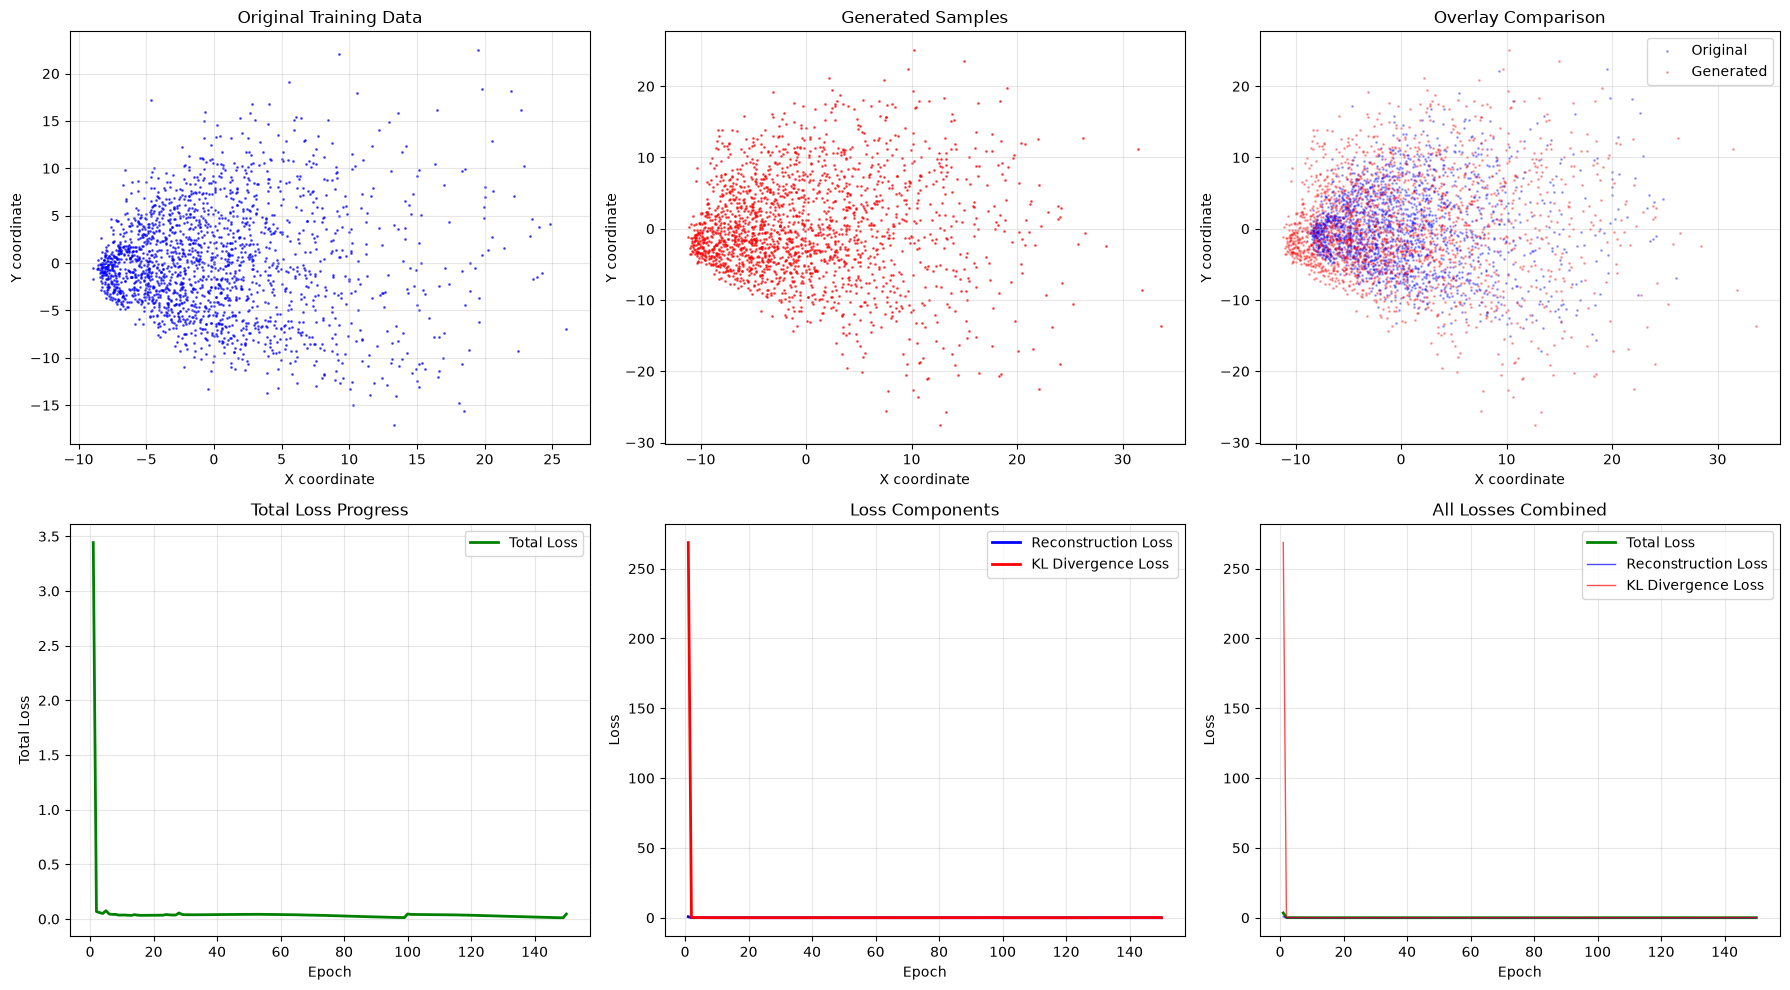

📈 Epoch 150 Summary:
   Total Loss: 0.0455
   Reconstruction Loss: 0.0208
   KL Divergence Loss: 0.0494
   Beta: 0.500
   Learning Rate: 0.000031

📊 Epoch 151/300
----------------------------------------
Epoch: 151 [0/60000 (0%)]	Total Loss: 0.040492	Recon Loss: 0.021144	KL Loss: 0.038734	Beta: 0.500
Epoch: 151 [51200/60000 (85%)]	Total Loss: 0.040195	Recon Loss: 0.021131	KL Loss: 0.038166	Beta: 0.500
====> Epoch: 151 Average Total Loss: 0.0405, Average Recon Loss: 0.0215, Average KL Loss: 0.0382, Beta: 0.500
📈 Epoch 151 Summary:
   Total Loss: 0.0405
   Reconstruction Loss: 0.0215
   KL Divergence Loss: 0.0382
   Beta: 0.500
   Learning Rate: 0.000031

📊 Epoch 152/300
----------------------------------------
Epoch: 152 [0/60000 (0%)]	Total Loss: 0.039968	Recon Loss: 0.020953	KL Loss: 0.038182	Beta: 0.498
Epoch: 152 [51200/60000 (85%)]	Total Loss: 0.040070	Recon Loss: 0.021422	KL Loss: 0.037442	Beta: 0.498
====> Epoch: 152 Average Total Loss: 0.0403, Average Recon Loss: 0.0214, Average

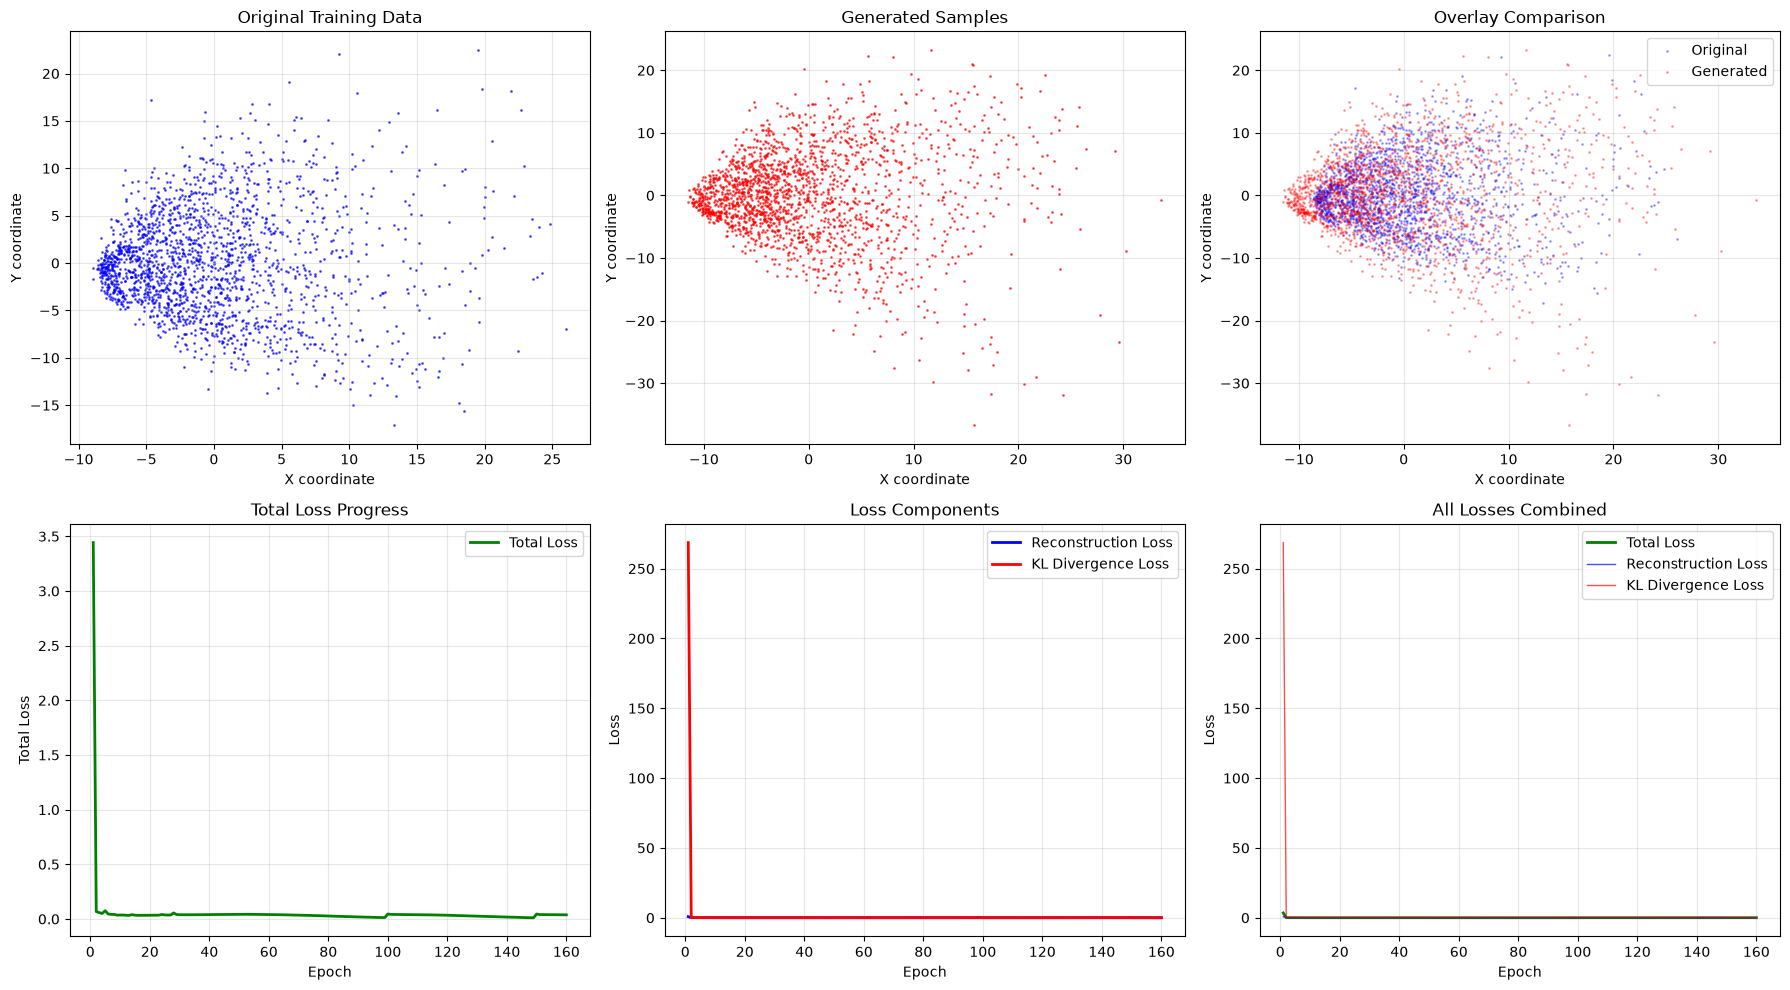

📈 Epoch 160 Summary:
   Total Loss: 0.0382
   Reconstruction Loss: 0.0206
   KL Divergence Loss: 0.0390
   Beta: 0.452
   Learning Rate: 0.000031

📊 Epoch 161/300
----------------------------------------
Epoch: 161 [0/60000 (0%)]	Total Loss: 0.038200	Recon Loss: 0.020898	KL Loss: 0.039089	Beta: 0.443
Epoch: 161 [51200/60000 (85%)]	Total Loss: 0.037768	Recon Loss: 0.020322	KL Loss: 0.039413	Beta: 0.443
====> Epoch: 161 Average Total Loss: 0.0378, Average Recon Loss: 0.0204, Average KL Loss: 0.0392, Beta: 0.443
📈 Epoch 161 Summary:
   Total Loss: 0.0378
   Reconstruction Loss: 0.0204
   KL Divergence Loss: 0.0392
   Beta: 0.443
   Learning Rate: 0.000031

📊 Epoch 162/300
----------------------------------------
Epoch: 162 [0/60000 (0%)]	Total Loss: 0.037320	Recon Loss: 0.020330	KL Loss: 0.039307	Beta: 0.432
Epoch: 162 [51200/60000 (85%)]	Total Loss: 0.037354	Recon Loss: 0.020060	KL Loss: 0.040010	Beta: 0.432
====> Epoch: 162 Average Total Loss: 0.0374, Average Recon Loss: 0.0202, Average

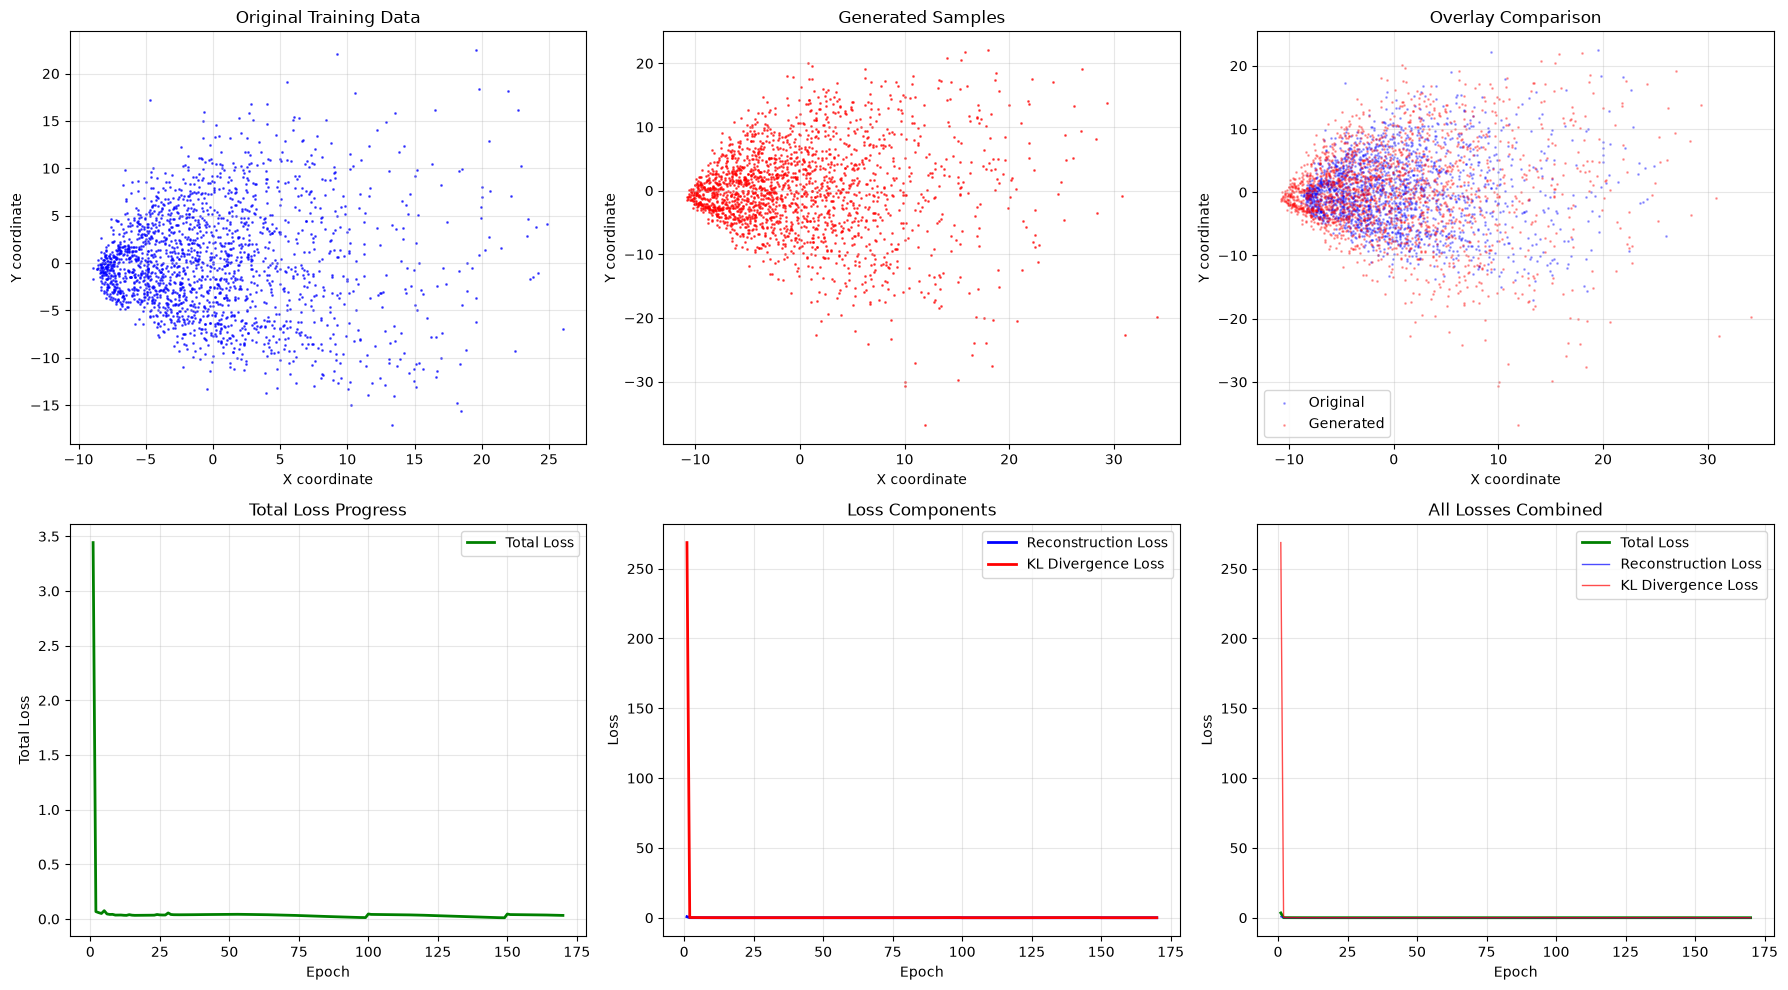

📈 Epoch 170 Summary:
   Total Loss: 0.0328
   Reconstruction Loss: 0.0182
   KL Divergence Loss: 0.0447
   Beta: 0.327
   Learning Rate: 0.000016

📊 Epoch 171/300
----------------------------------------
Epoch: 171 [0/60000 (0%)]	Total Loss: 0.032862	Recon Loss: 0.018758	KL Loss: 0.045178	Beta: 0.312
Epoch: 171 [51200/60000 (85%)]	Total Loss: 0.031585	Recon Loss: 0.017356	KL Loss: 0.045581	Beta: 0.312
====> Epoch: 171 Average Total Loss: 0.0319, Average Recon Loss: 0.0177, Average KL Loss: 0.0455, Beta: 0.312
📈 Epoch 171 Summary:
   Total Loss: 0.0319
   Reconstruction Loss: 0.0177
   KL Divergence Loss: 0.0455
   Beta: 0.312
   Learning Rate: 0.000016

📊 Epoch 172/300
----------------------------------------
Epoch: 172 [0/60000 (0%)]	Total Loss: 0.031107	Recon Loss: 0.017552	KL Loss: 0.045661	Beta: 0.297
Epoch: 172 [51200/60000 (85%)]	Total Loss: 0.031113	Recon Loss: 0.017271	KL Loss: 0.046631	Beta: 0.297
====> Epoch: 172 Average Total Loss: 0.0311, Average Recon Loss: 0.0173, Average

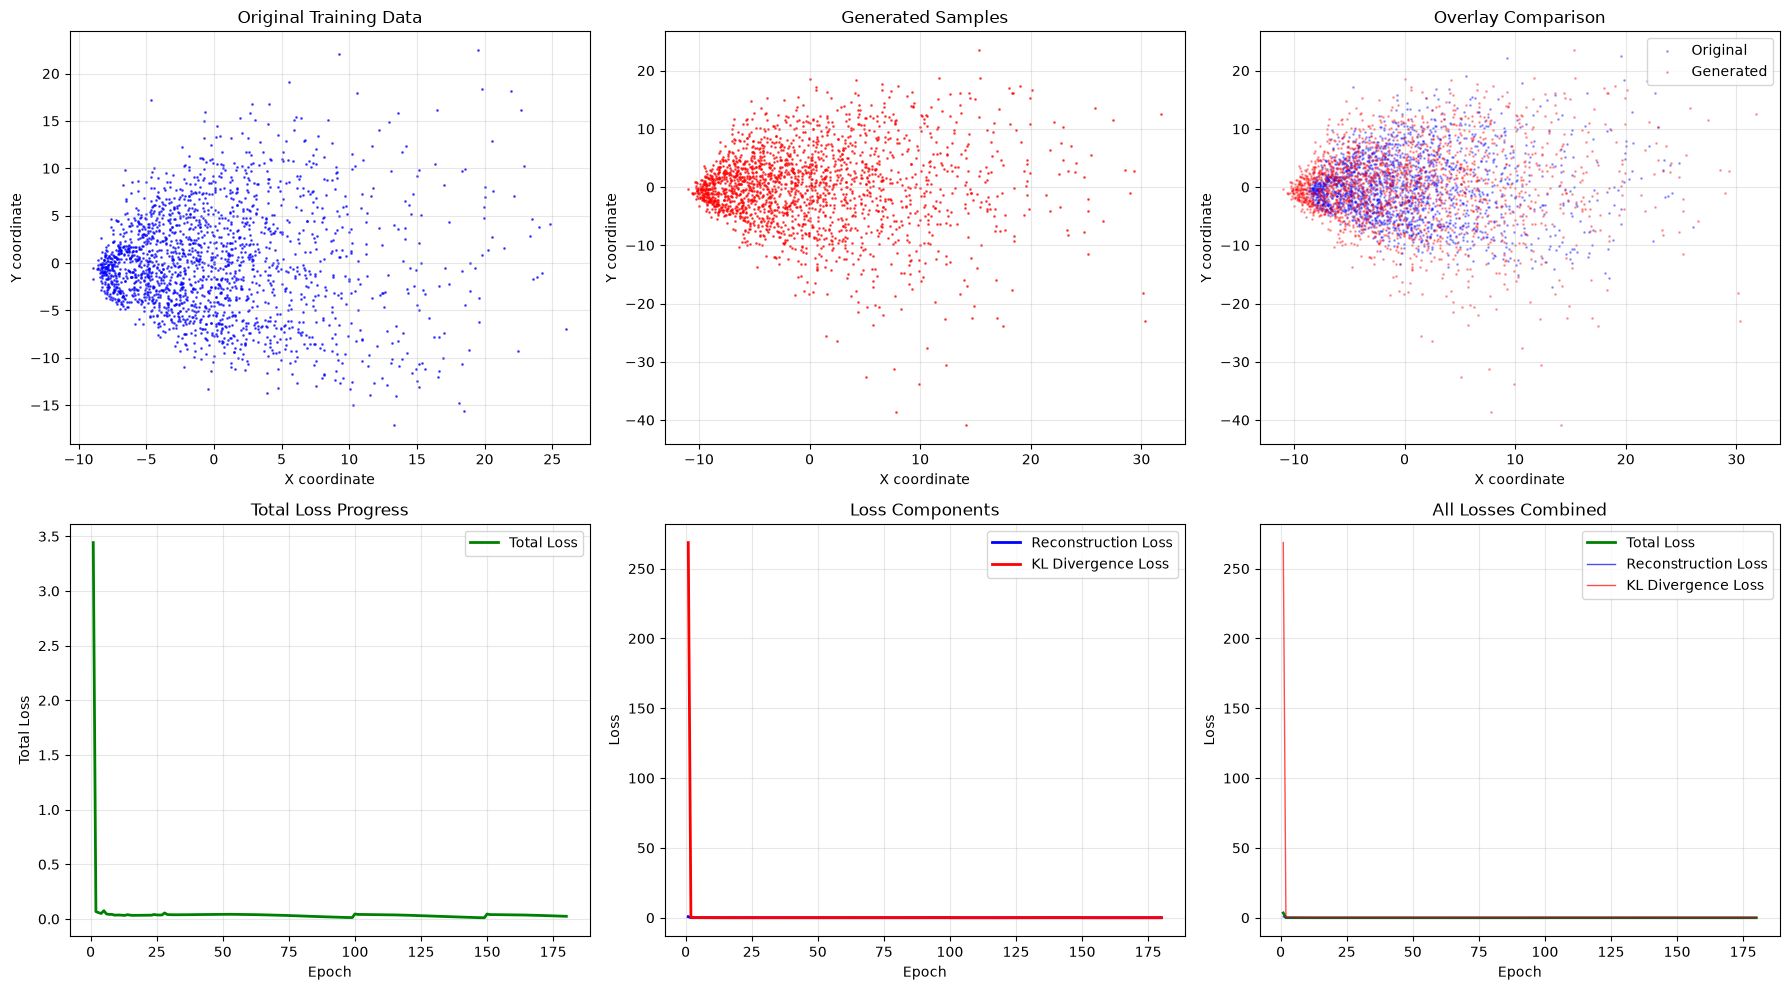

📈 Epoch 180 Summary:
   Total Loss: 0.0245
   Reconstruction Loss: 0.0148
   KL Divergence Loss: 0.0561
   Beta: 0.173
   Learning Rate: 0.000016

📊 Epoch 181/300
----------------------------------------
Epoch: 181 [0/60000 (0%)]	Total Loss: 0.023355	Recon Loss: 0.014461	KL Loss: 0.056299	Beta: 0.158
Epoch: 181 [51200/60000 (85%)]	Total Loss: 0.023443	Recon Loss: 0.014327	KL Loss: 0.057703	Beta: 0.158
====> Epoch: 181 Average Total Loss: 0.0237, Average Recon Loss: 0.0145, Average KL Loss: 0.0577, Beta: 0.158
📈 Epoch 181 Summary:
   Total Loss: 0.0237
   Reconstruction Loss: 0.0145
   KL Divergence Loss: 0.0577
   Beta: 0.158
   Learning Rate: 0.000016

📊 Epoch 182/300
----------------------------------------
Epoch: 182 [0/60000 (0%)]	Total Loss: 0.022736	Recon Loss: 0.014419	KL Loss: 0.057936	Beta: 0.144
Epoch: 182 [51200/60000 (85%)]	Total Loss: 0.022897	Recon Loss: 0.014307	KL Loss: 0.059835	Beta: 0.144
====> Epoch: 182 Average Total Loss: 0.0228, Average Recon Loss: 0.0142, Average

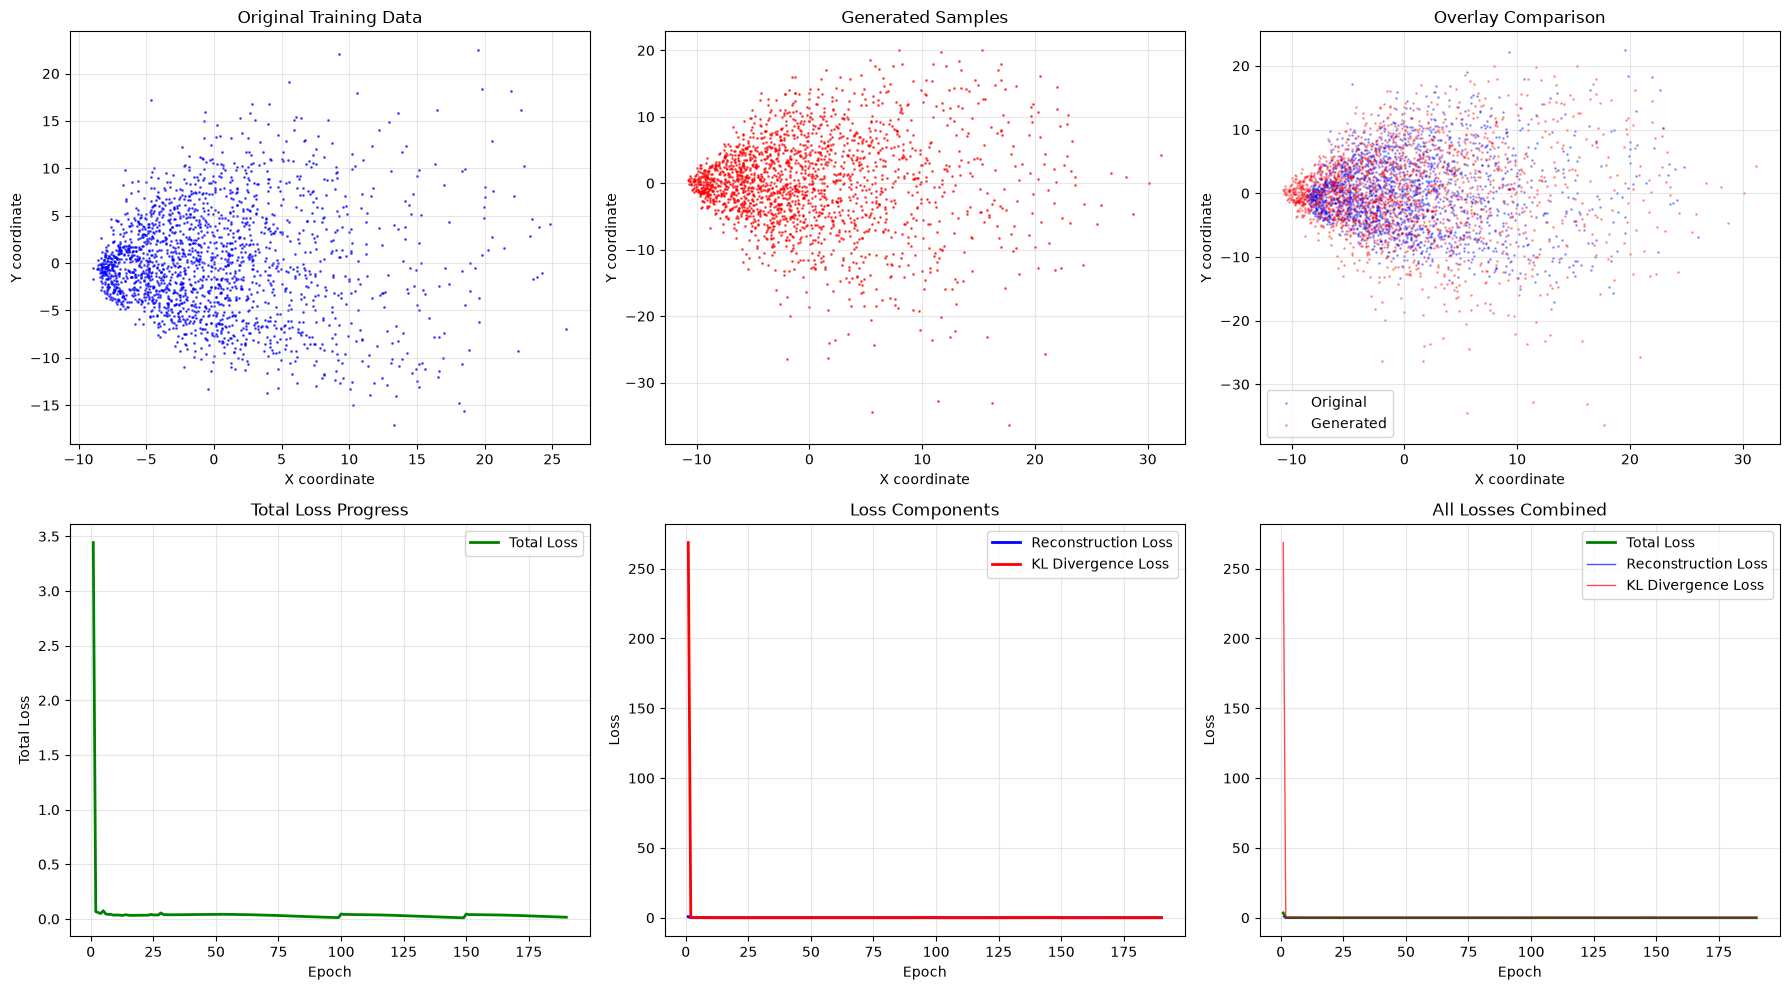

📈 Epoch 190 Summary:
   Total Loss: 0.0160
   Reconstruction Loss: 0.0122
   KL Divergence Loss: 0.0792
   Beta: 0.048
   Learning Rate: 0.000016

📊 Epoch 191/300
----------------------------------------
Epoch: 191 [0/60000 (0%)]	Total Loss: 0.015230	Recon Loss: 0.012134	KL Loss: 0.079550	Beta: 0.039
Epoch: 191 [51200/60000 (85%)]	Total Loss: 0.015325	Recon Loss: 0.012059	KL Loss: 0.083925	Beta: 0.039
====> Epoch: 191 Average Total Loss: 0.0152, Average Recon Loss: 0.0120, Average KL Loss: 0.0828, Beta: 0.039
📈 Epoch 191 Summary:
   Total Loss: 0.0152
   Reconstruction Loss: 0.0120
   KL Divergence Loss: 0.0828
   Beta: 0.039
   Learning Rate: 0.000008

📊 Epoch 192/300
----------------------------------------
Epoch: 192 [0/60000 (0%)]	Total Loss: 0.014203	Recon Loss: 0.011618	KL Loss: 0.083595	Beta: 0.031
Epoch: 192 [51200/60000 (85%)]	Total Loss: 0.014167	Recon Loss: 0.011475	KL Loss: 0.087035	Beta: 0.031
====> Epoch: 192 Average Total Loss: 0.0144, Average Recon Loss: 0.0117, Average

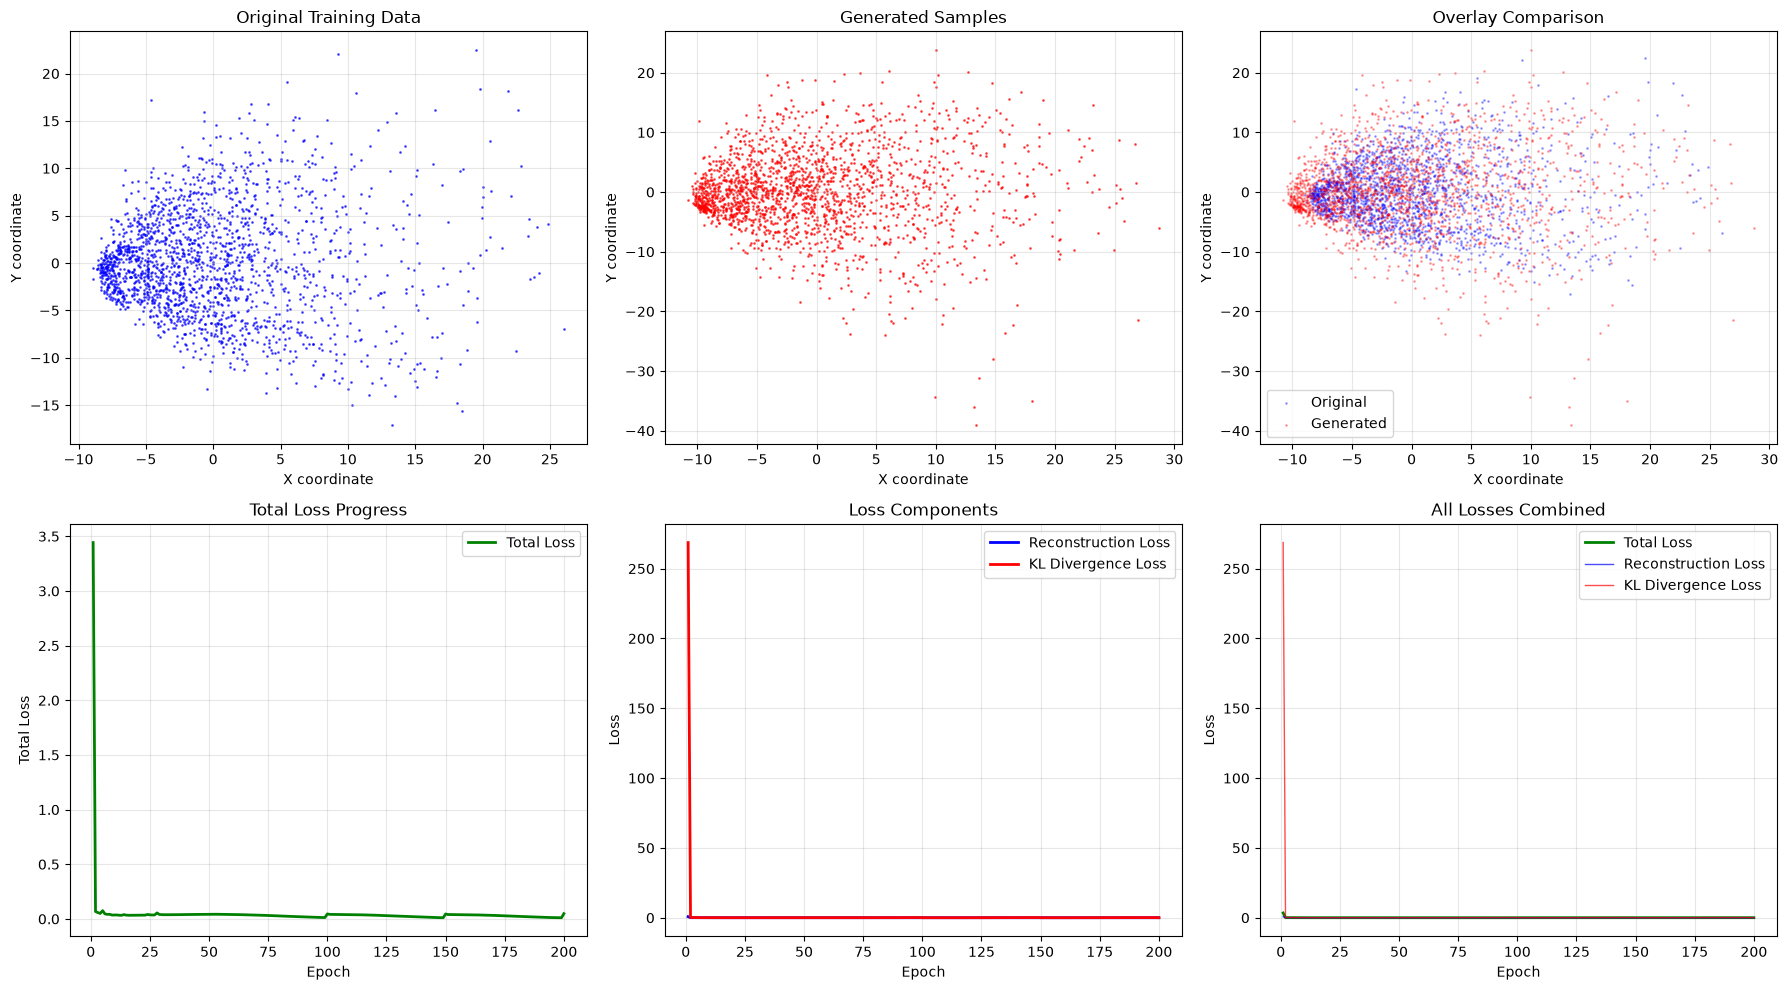

📈 Epoch 200 Summary:
   Total Loss: 0.0487
   Reconstruction Loss: 0.0162
   KL Divergence Loss: 0.0649
   Beta: 0.500
   Learning Rate: 0.000008

📊 Epoch 201/300
----------------------------------------
Epoch: 201 [0/60000 (0%)]	Total Loss: 0.040687	Recon Loss: 0.019094	KL Loss: 0.043227	Beta: 0.500
Epoch: 201 [51200/60000 (85%)]	Total Loss: 0.039775	Recon Loss: 0.019688	KL Loss: 0.040212	Beta: 0.500
====> Epoch: 201 Average Total Loss: 0.0400, Average Recon Loss: 0.0193, Average KL Loss: 0.0415, Beta: 0.500
📈 Epoch 201 Summary:
   Total Loss: 0.0400
   Reconstruction Loss: 0.0193
   KL Divergence Loss: 0.0415
   Beta: 0.500
   Learning Rate: 0.000008

📊 Epoch 202/300
----------------------------------------
Epoch: 202 [0/60000 (0%)]	Total Loss: 0.039773	Recon Loss: 0.019623	KL Loss: 0.040458	Beta: 0.498
Epoch: 202 [51200/60000 (85%)]	Total Loss: 0.039862	Recon Loss: 0.020100	KL Loss: 0.039680	Beta: 0.498
====> Epoch: 202 Average Total Loss: 0.0397, Average Recon Loss: 0.0197, Average

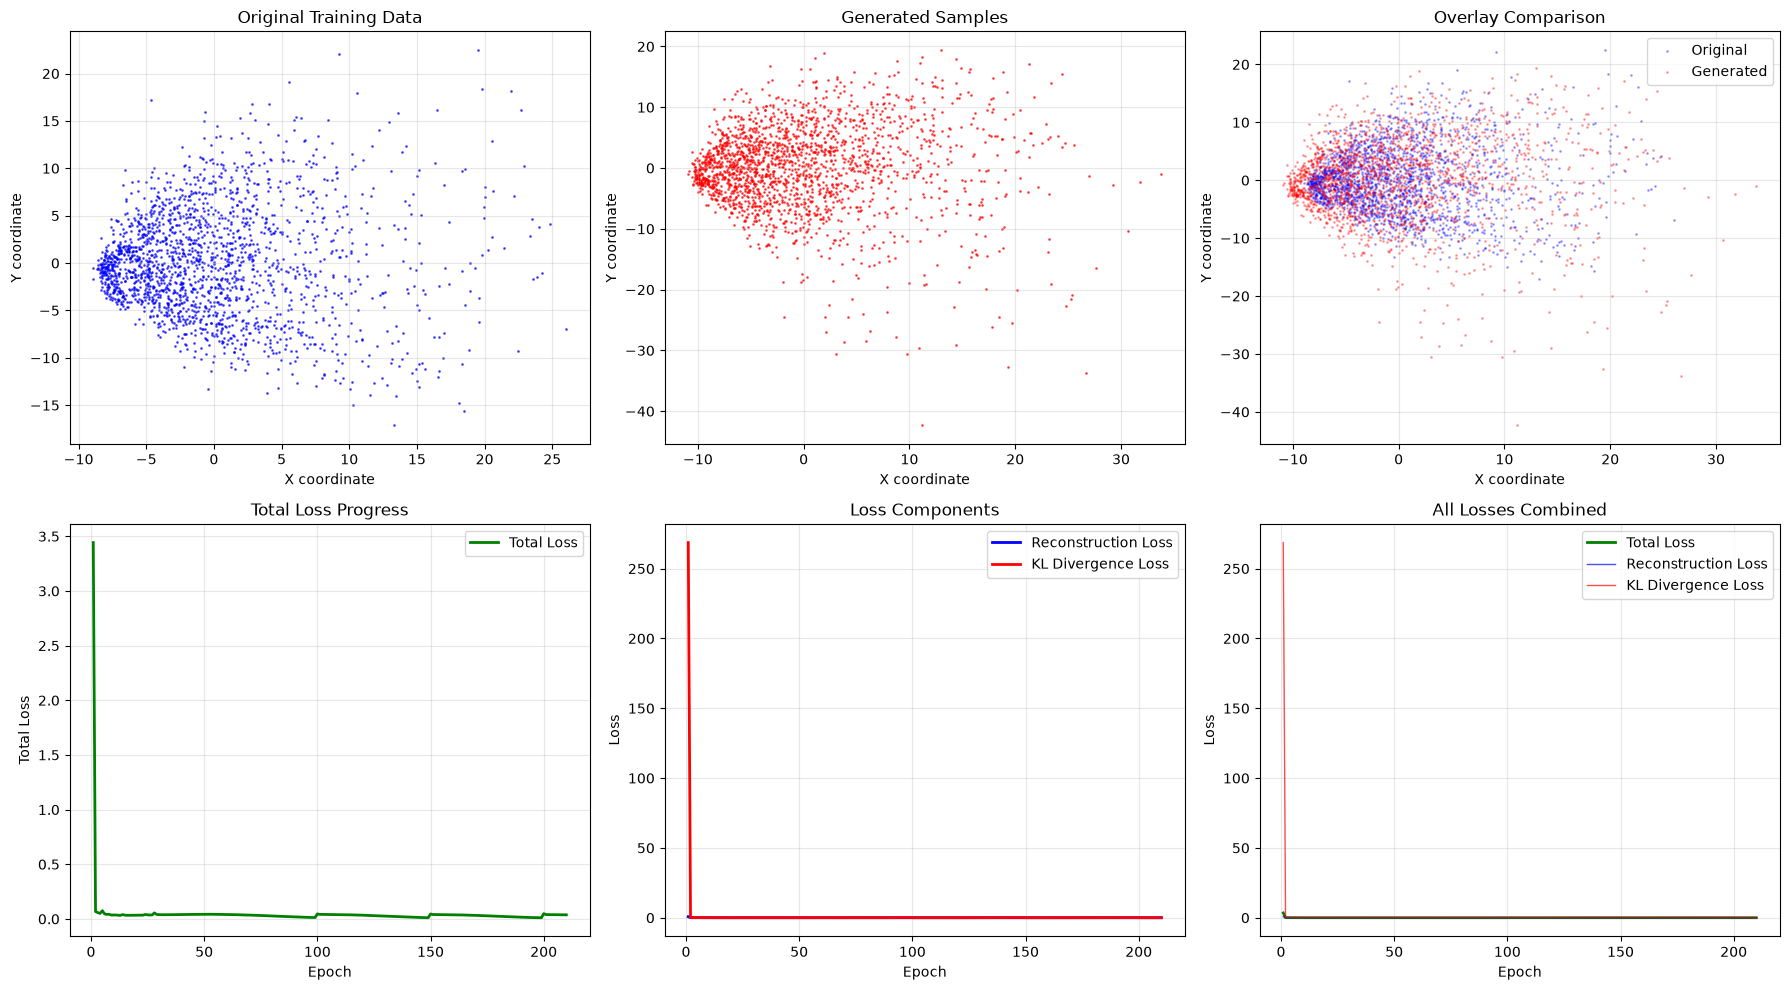

📈 Epoch 210 Summary:
   Total Loss: 0.0375
   Reconstruction Loss: 0.0193
   KL Divergence Loss: 0.0403
   Beta: 0.452
   Learning Rate: 0.000008

📊 Epoch 211/300
----------------------------------------
Epoch: 211 [0/60000 (0%)]	Total Loss: 0.036706	Recon Loss: 0.018910	KL Loss: 0.040204	Beta: 0.443
Epoch: 211 [51200/60000 (85%)]	Total Loss: 0.037842	Recon Loss: 0.019671	KL Loss: 0.041054	Beta: 0.443
====> Epoch: 211 Average Total Loss: 0.0372, Average Recon Loss: 0.0191, Average KL Loss: 0.0407, Beta: 0.443
📈 Epoch 211 Summary:
   Total Loss: 0.0372
   Reconstruction Loss: 0.0191
   KL Divergence Loss: 0.0407
   Beta: 0.443
   Learning Rate: 0.000008

📊 Epoch 212/300
----------------------------------------
Epoch: 212 [0/60000 (0%)]	Total Loss: 0.036249	Recon Loss: 0.018702	KL Loss: 0.040597	Beta: 0.432
Epoch: 212 [51200/60000 (85%)]	Total Loss: 0.036919	Recon Loss: 0.019226	KL Loss: 0.040933	Beta: 0.432
====> Epoch: 212 Average Total Loss: 0.0367, Average Recon Loss: 0.0190, Average

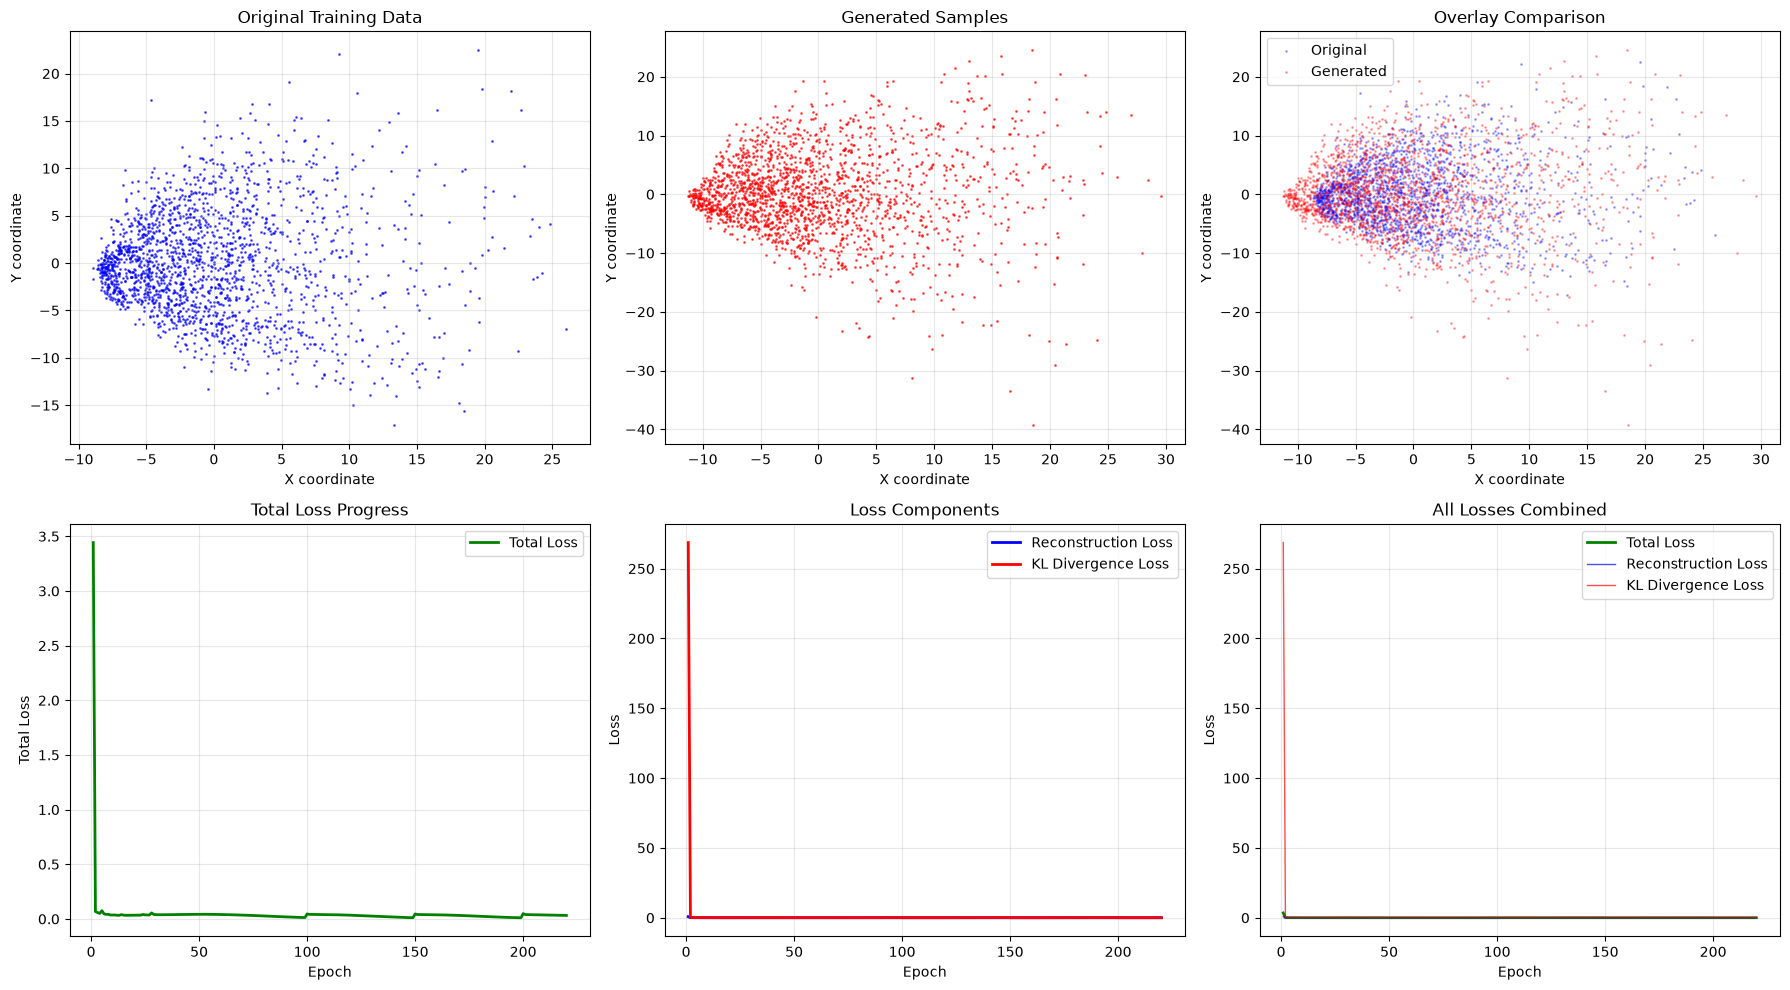

📈 Epoch 220 Summary:
   Total Loss: 0.0321
   Reconstruction Loss: 0.0171
   KL Divergence Loss: 0.0457
   Beta: 0.327
   Learning Rate: 0.000004

📊 Epoch 221/300
----------------------------------------
Epoch: 221 [0/60000 (0%)]	Total Loss: 0.031499	Recon Loss: 0.017134	KL Loss: 0.046015	Beta: 0.312
Epoch: 221 [51200/60000 (85%)]	Total Loss: 0.031634	Recon Loss: 0.017067	KL Loss: 0.046665	Beta: 0.312
====> Epoch: 221 Average Total Loss: 0.0313, Average Recon Loss: 0.0169, Average KL Loss: 0.0463, Beta: 0.312
📈 Epoch 221 Summary:
   Total Loss: 0.0313
   Reconstruction Loss: 0.0169
   KL Divergence Loss: 0.0463
   Beta: 0.312
   Learning Rate: 0.000004

📊 Epoch 222/300
----------------------------------------
Epoch: 222 [0/60000 (0%)]	Total Loss: 0.030301	Recon Loss: 0.016500	KL Loss: 0.046492	Beta: 0.297
Epoch: 222 [51200/60000 (85%)]	Total Loss: 0.030006	Recon Loss: 0.016045	KL Loss: 0.047031	Beta: 0.297
====> Epoch: 222 Average Total Loss: 0.0306, Average Recon Loss: 0.0166, Average

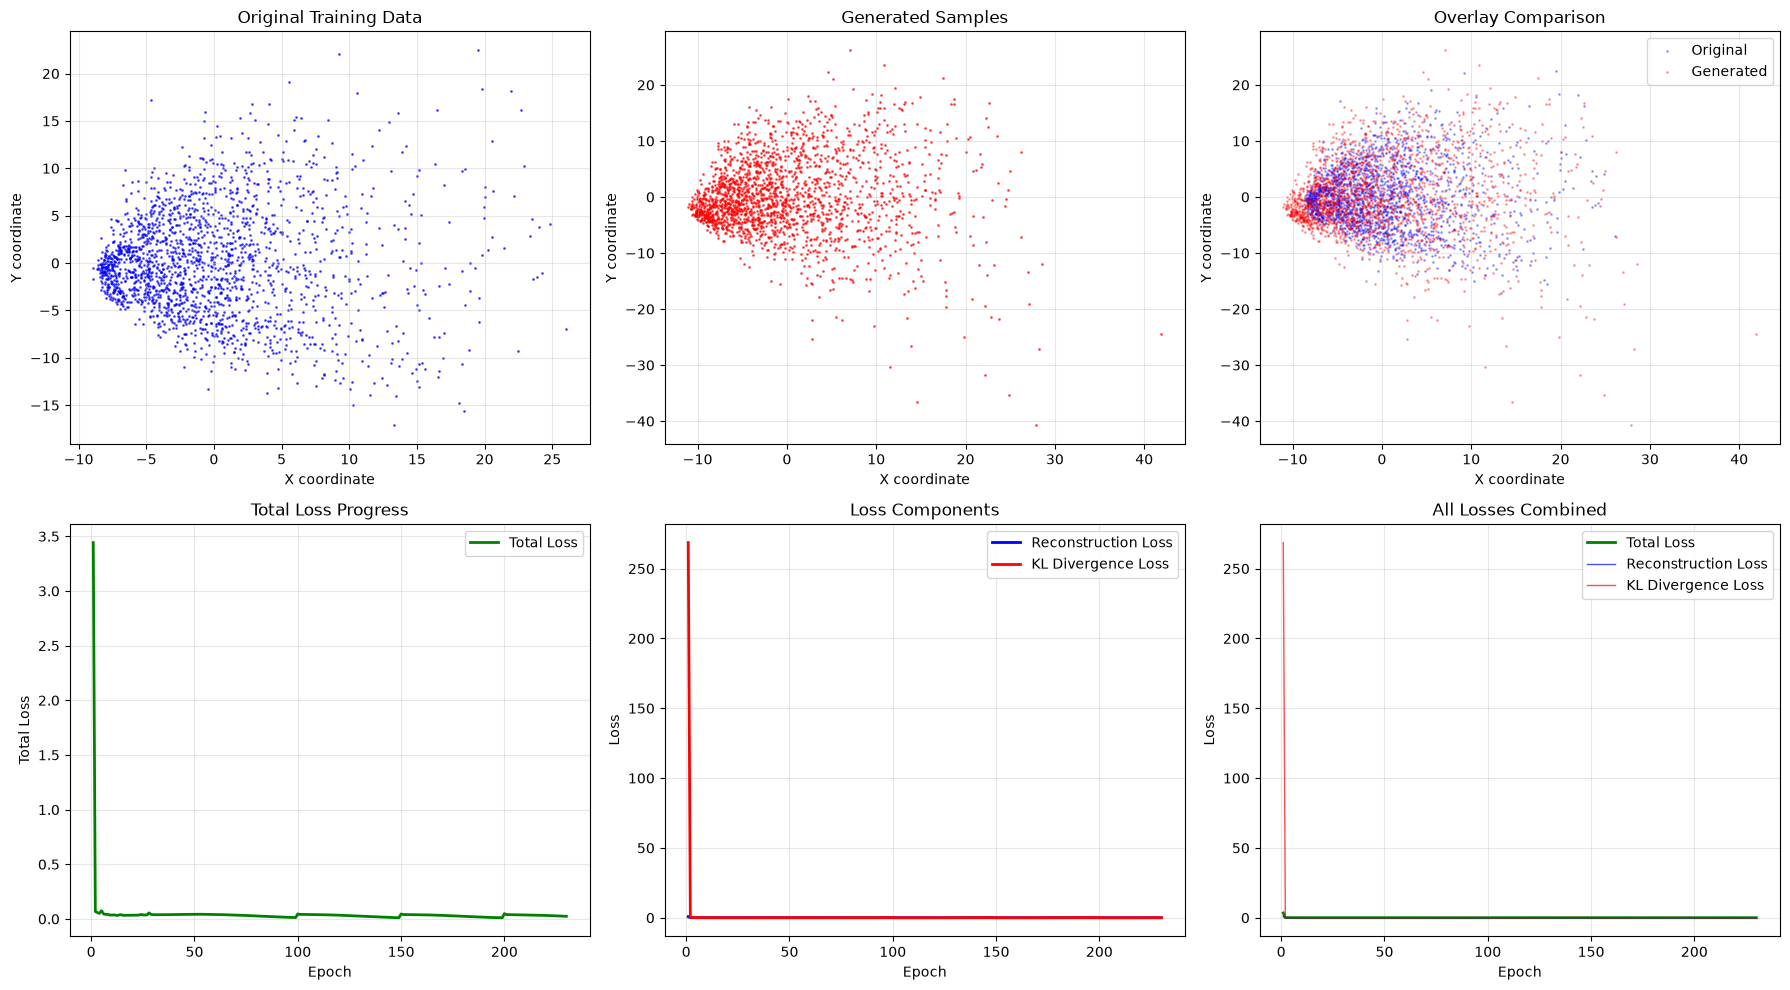

📈 Epoch 230 Summary:
   Total Loss: 0.0241
   Reconstruction Loss: 0.0144
   KL Divergence Loss: 0.0560
   Beta: 0.173
   Learning Rate: 0.000004

📊 Epoch 231/300
----------------------------------------
Epoch: 231 [0/60000 (0%)]	Total Loss: 0.023044	Recon Loss: 0.014122	KL Loss: 0.056481	Beta: 0.158
Epoch: 231 [51200/60000 (85%)]	Total Loss: 0.023429	Recon Loss: 0.014245	KL Loss: 0.058135	Beta: 0.158
====> Epoch: 231 Average Total Loss: 0.0232, Average Recon Loss: 0.0141, Average KL Loss: 0.0575, Beta: 0.158
📈 Epoch 231 Summary:
   Total Loss: 0.0232
   Reconstruction Loss: 0.0141
   KL Divergence Loss: 0.0575
   Beta: 0.158
   Learning Rate: 0.000004

📊 Epoch 232/300
----------------------------------------
Epoch: 232 [0/60000 (0%)]	Total Loss: 0.023011	Recon Loss: 0.014659	KL Loss: 0.058177	Beta: 0.144
Epoch: 232 [51200/60000 (85%)]	Total Loss: 0.022089	Recon Loss: 0.013557	KL Loss: 0.059431	Beta: 0.144
====> Epoch: 232 Average Total Loss: 0.0223, Average Recon Loss: 0.0139, Average

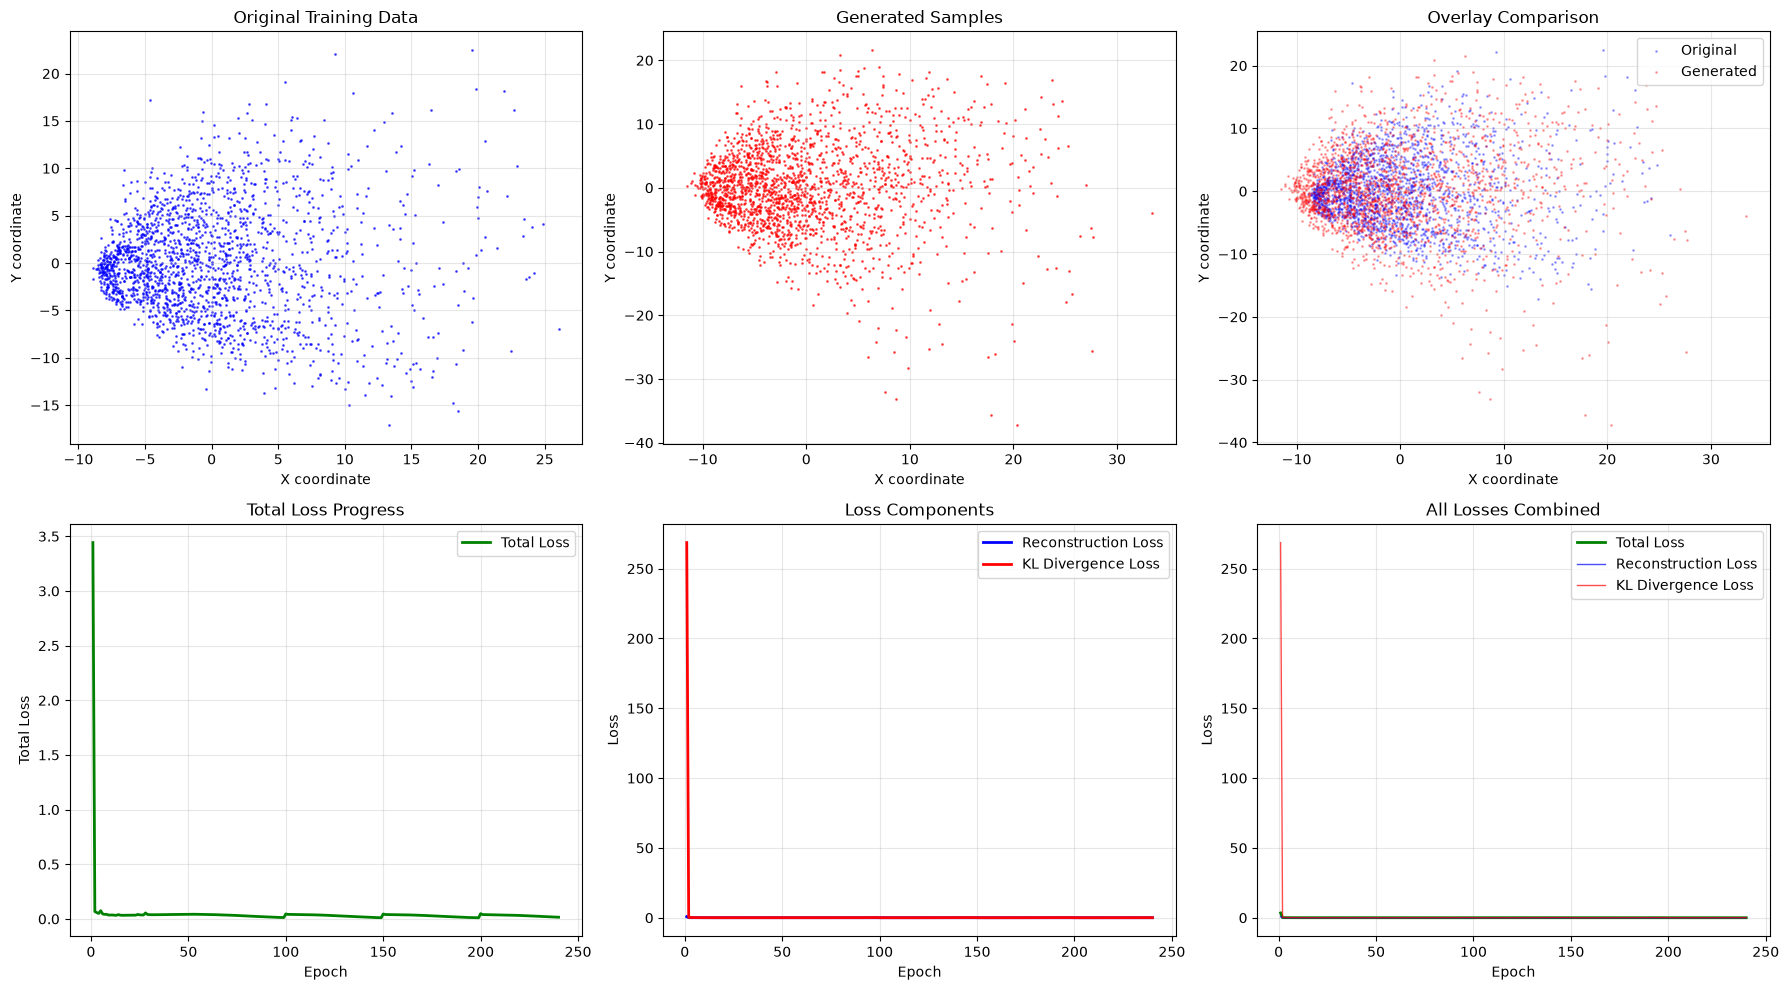

📈 Epoch 240 Summary:
   Total Loss: 0.0157
   Reconstruction Loss: 0.0120
   KL Divergence Loss: 0.0769
   Beta: 0.048
   Learning Rate: 0.000004

📊 Epoch 241/300
----------------------------------------
Epoch: 241 [0/60000 (0%)]	Total Loss: 0.014823	Recon Loss: 0.011791	KL Loss: 0.077916	Beta: 0.039
Epoch: 241 [51200/60000 (85%)]	Total Loss: 0.015030	Recon Loss: 0.011862	KL Loss: 0.081395	Beta: 0.039
====> Epoch: 241 Average Total Loss: 0.0149, Average Recon Loss: 0.0118, Average KL Loss: 0.0800, Beta: 0.039
📈 Epoch 241 Summary:
   Total Loss: 0.0149
   Reconstruction Loss: 0.0118
   KL Divergence Loss: 0.0800
   Beta: 0.039
   Learning Rate: 0.000002

📊 Epoch 242/300
----------------------------------------
Epoch: 242 [0/60000 (0%)]	Total Loss: 0.014256	Recon Loss: 0.011743	KL Loss: 0.081261	Beta: 0.031
Epoch: 242 [51200/60000 (85%)]	Total Loss: 0.014023	Recon Loss: 0.011437	KL Loss: 0.083605	Beta: 0.031
====> Epoch: 242 Average Total Loss: 0.0142, Average Recon Loss: 0.0117, Average

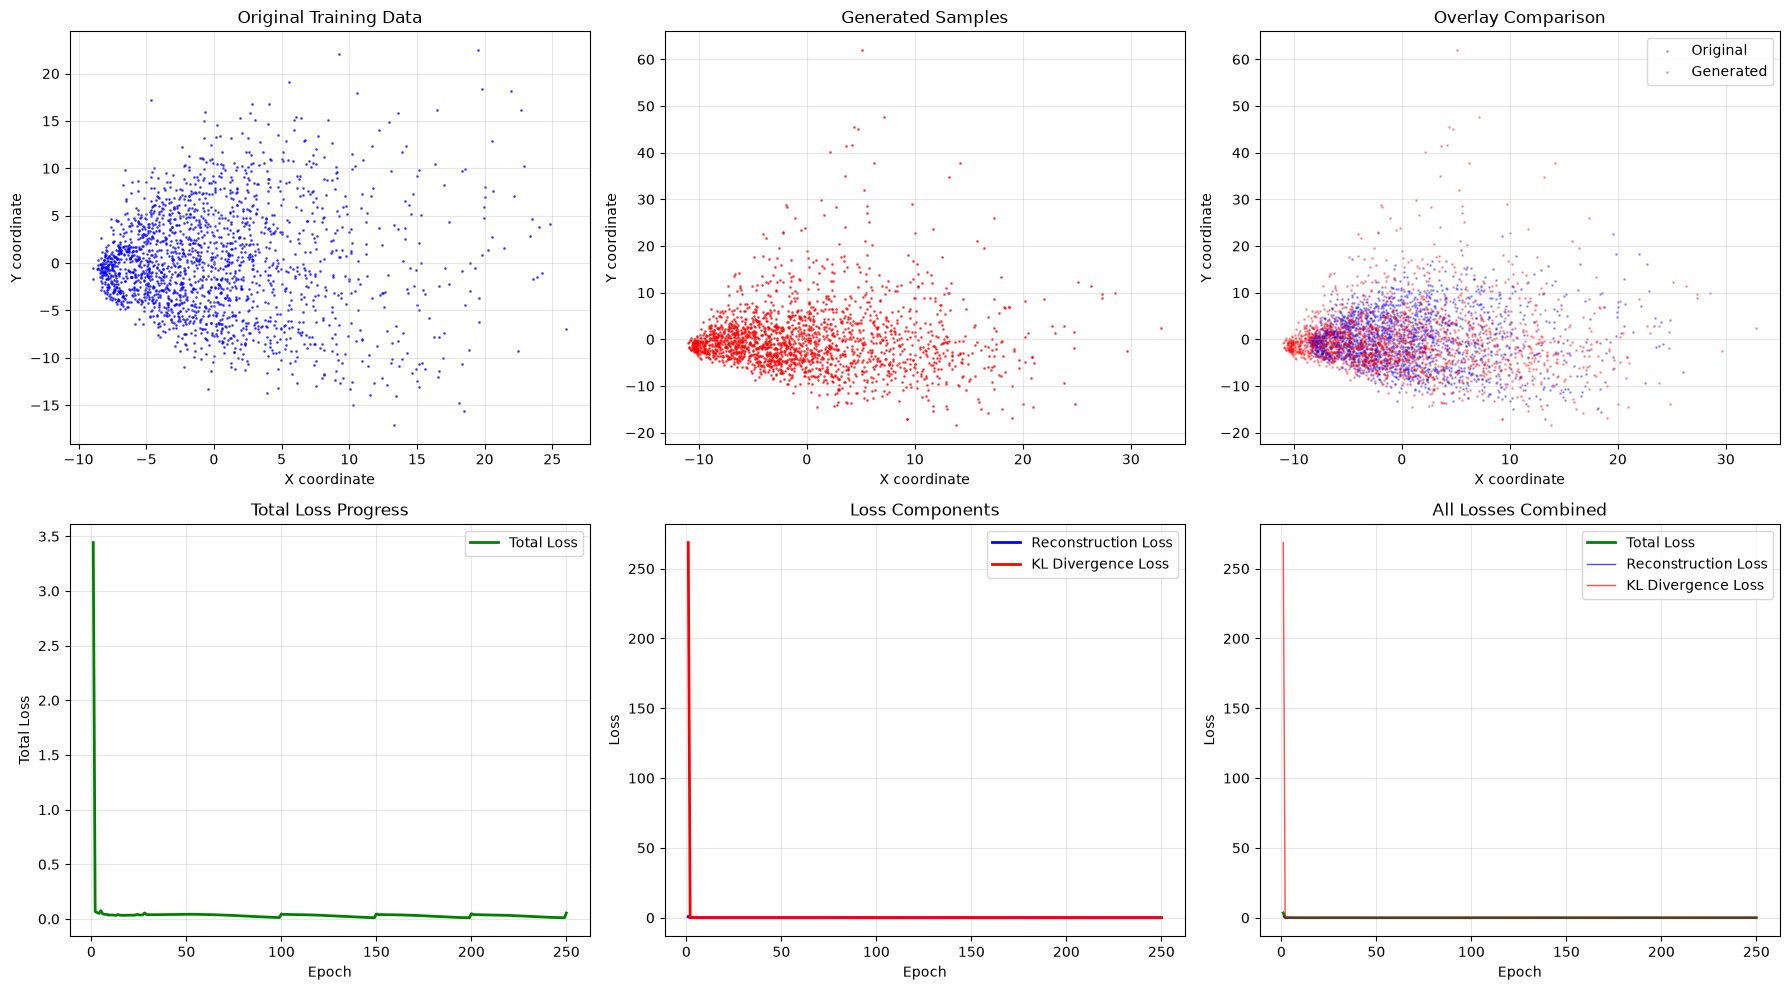

📈 Epoch 250 Summary:
   Total Loss: 0.0545
   Reconstruction Loss: 0.0120
   KL Divergence Loss: 0.0851
   Beta: 0.500
   Learning Rate: 0.000002

📊 Epoch 251/300
----------------------------------------
Epoch: 251 [0/60000 (0%)]	Total Loss: 0.044692	Recon Loss: 0.013164	KL Loss: 0.063118	Beta: 0.500
Epoch: 251 [51200/60000 (85%)]	Total Loss: 0.041805	Recon Loss: 0.016195	KL Loss: 0.051270	Beta: 0.500
====> Epoch: 251 Average Total Loss: 0.0429, Average Recon Loss: 0.0152, Average KL Loss: 0.0555, Beta: 0.500
📈 Epoch 251 Summary:
   Total Loss: 0.0429
   Reconstruction Loss: 0.0152
   KL Divergence Loss: 0.0555
   Beta: 0.500
   Learning Rate: 0.000002

📊 Epoch 252/300
----------------------------------------
Epoch: 252 [0/60000 (0%)]	Total Loss: 0.040820	Recon Loss: 0.015947	KL Loss: 0.049942	Beta: 0.498
Epoch: 252 [51200/60000 (85%)]	Total Loss: 0.040689	Recon Loss: 0.017611	KL Loss: 0.046339	Beta: 0.498
====> Epoch: 252 Average Total Loss: 0.0409, Average Recon Loss: 0.0170, Average

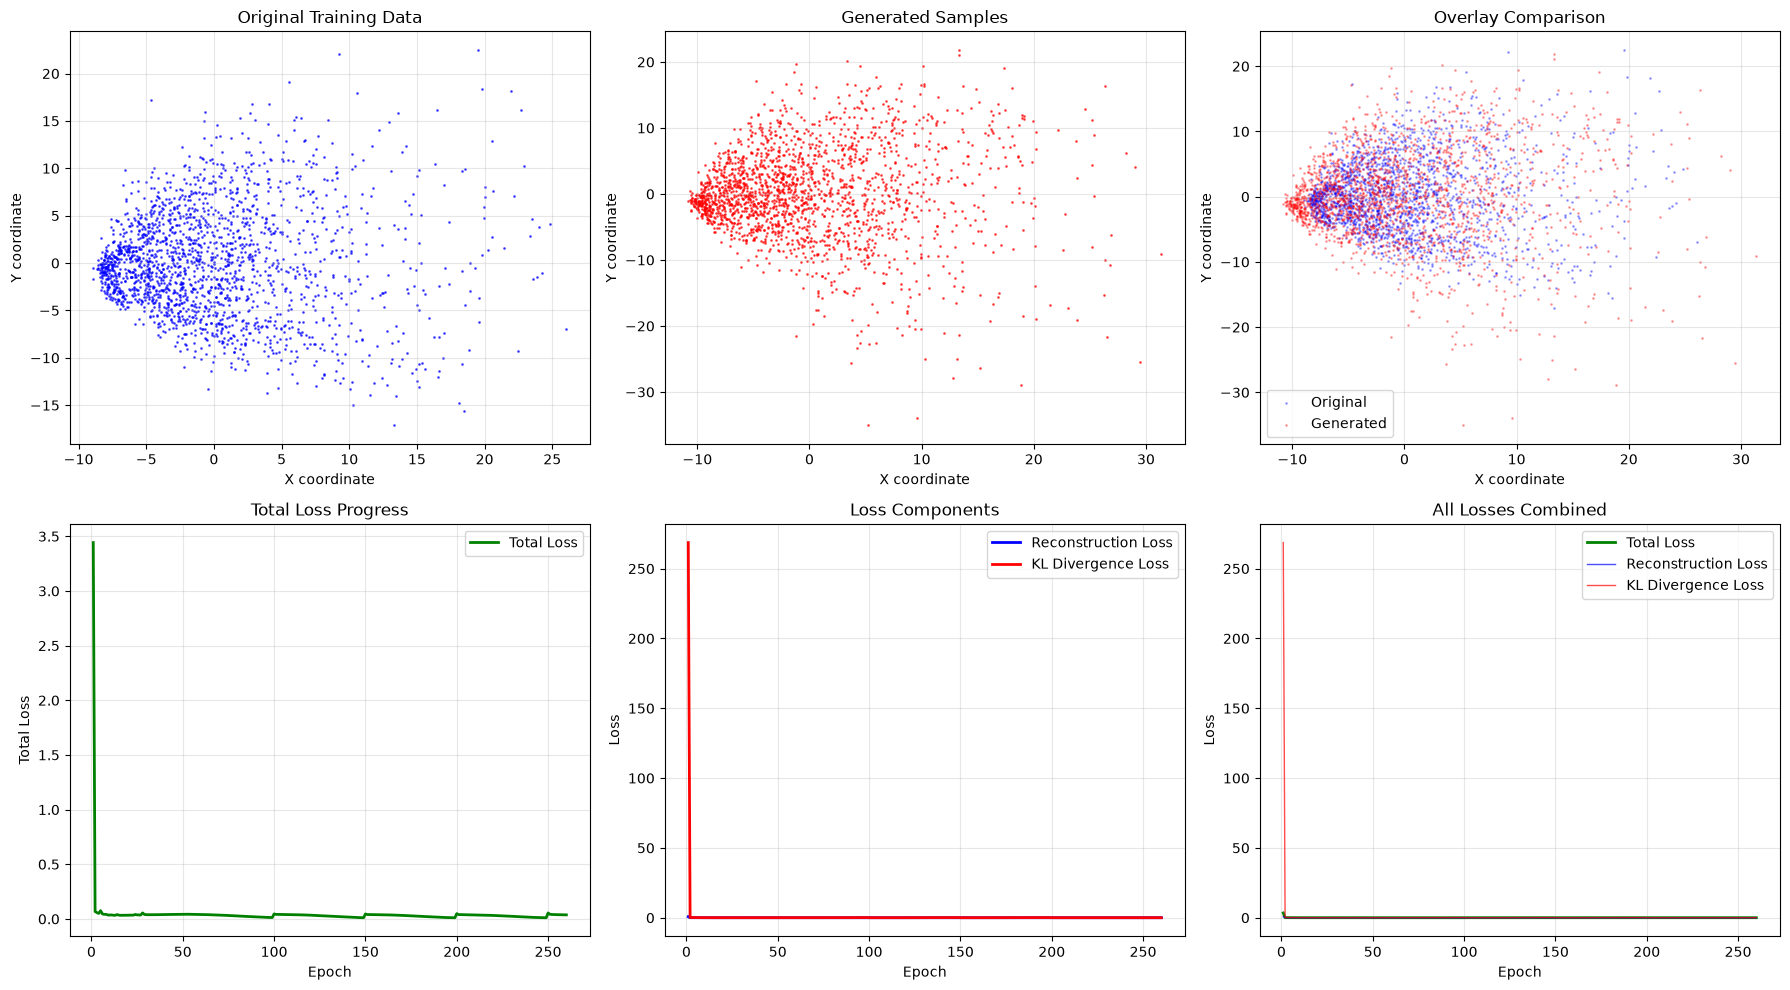

📈 Epoch 260 Summary:
   Total Loss: 0.0374
   Reconstruction Loss: 0.0186
   KL Divergence Loss: 0.0415
   Beta: 0.452
   Learning Rate: 0.000002

📊 Epoch 261/300
----------------------------------------
Epoch: 261 [0/60000 (0%)]	Total Loss: 0.036705	Recon Loss: 0.018424	KL Loss: 0.041300	Beta: 0.443
Epoch: 261 [51200/60000 (85%)]	Total Loss: 0.037579	Recon Loss: 0.019087	KL Loss: 0.041777	Beta: 0.443
====> Epoch: 261 Average Total Loss: 0.0370, Average Recon Loss: 0.0186, Average KL Loss: 0.0416, Beta: 0.443
📈 Epoch 261 Summary:
   Total Loss: 0.0370
   Reconstruction Loss: 0.0186
   KL Divergence Loss: 0.0416
   Beta: 0.443
   Learning Rate: 0.000002

📊 Epoch 262/300
----------------------------------------
Epoch: 262 [0/60000 (0%)]	Total Loss: 0.036795	Recon Loss: 0.018823	KL Loss: 0.041577	Beta: 0.432
Epoch: 262 [51200/60000 (85%)]	Total Loss: 0.036406	Recon Loss: 0.018341	KL Loss: 0.041794	Beta: 0.432
====> Epoch: 262 Average Total Loss: 0.0366, Average Recon Loss: 0.0185, Average

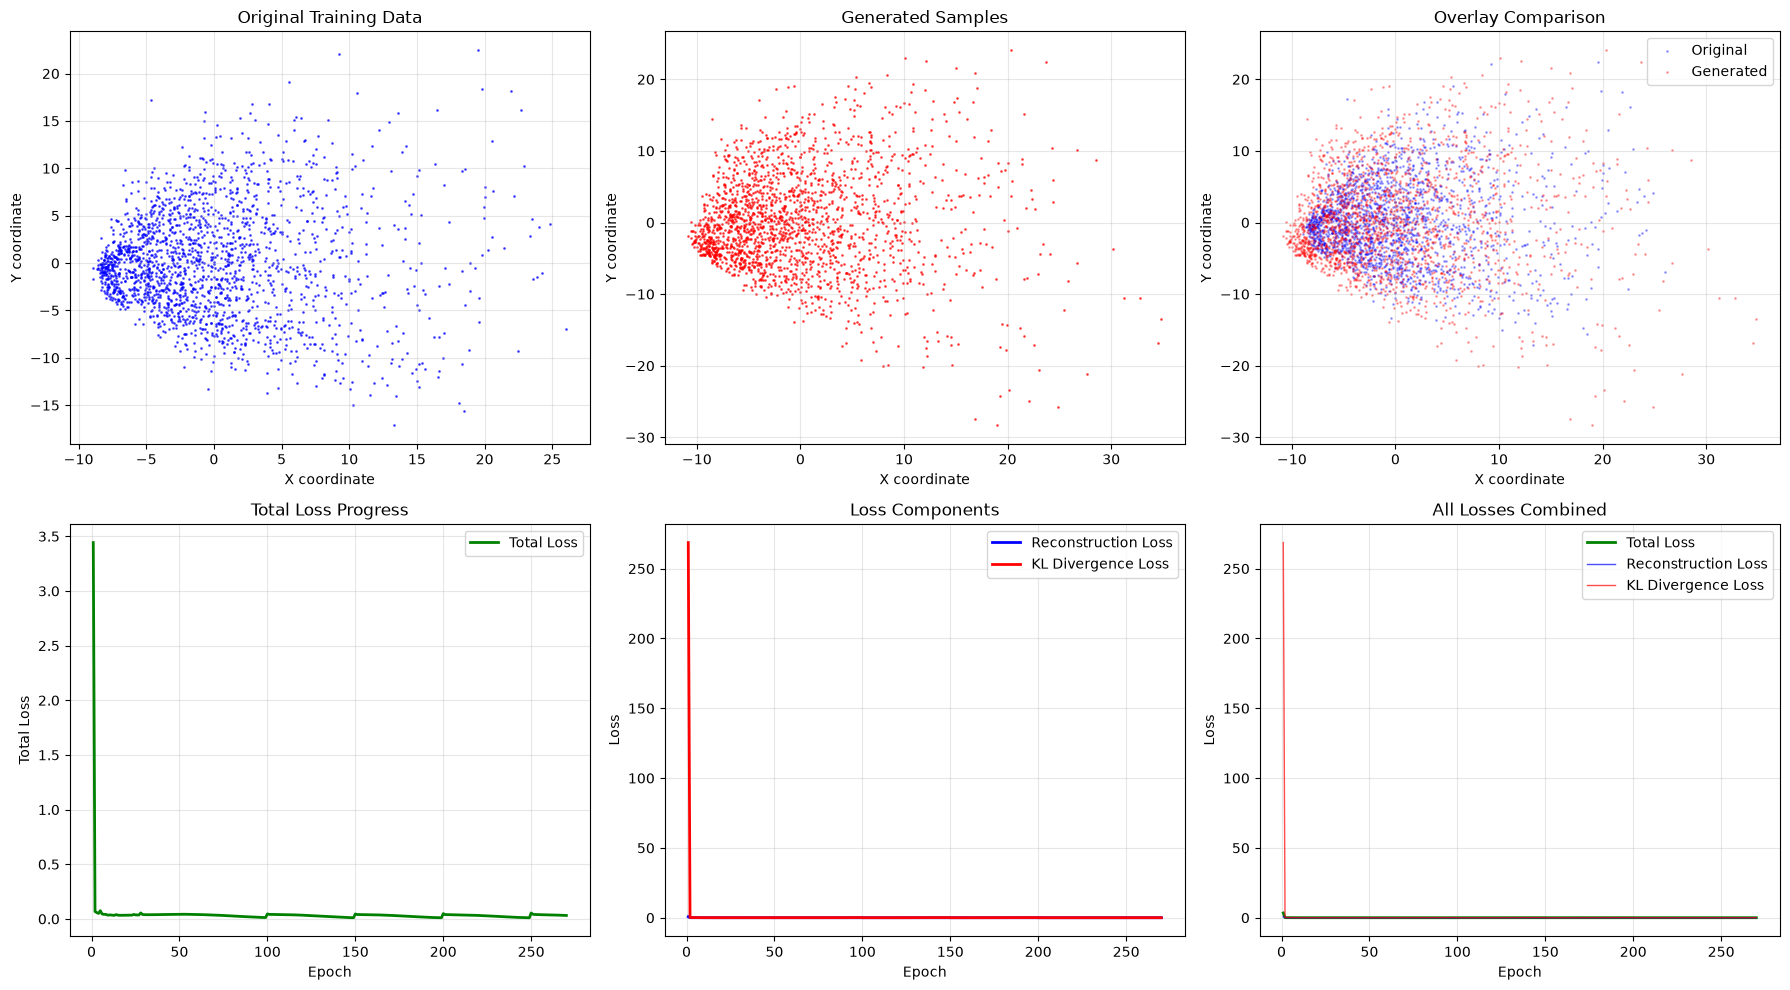

📈 Epoch 270 Summary:
   Total Loss: 0.0319
   Reconstruction Loss: 0.0170
   KL Divergence Loss: 0.0454
   Beta: 0.327
   Learning Rate: 0.000001

📊 Epoch 271/300
----------------------------------------
Epoch: 271 [0/60000 (0%)]	Total Loss: 0.030359	Recon Loss: 0.016233	KL Loss: 0.045249	Beta: 0.312
Epoch: 271 [51200/60000 (85%)]	Total Loss: 0.031251	Recon Loss: 0.016743	KL Loss: 0.046475	Beta: 0.312
====> Epoch: 271 Average Total Loss: 0.0311, Average Recon Loss: 0.0168, Average KL Loss: 0.0460, Beta: 0.312
📈 Epoch 271 Summary:
   Total Loss: 0.0311
   Reconstruction Loss: 0.0168
   KL Divergence Loss: 0.0460
   Beta: 0.312
   Learning Rate: 0.000001

📊 Epoch 272/300
----------------------------------------
Epoch: 272 [0/60000 (0%)]	Total Loss: 0.030413	Recon Loss: 0.016588	KL Loss: 0.046574	Beta: 0.297
Epoch: 272 [51200/60000 (85%)]	Total Loss: 0.030173	Recon Loss: 0.016369	KL Loss: 0.046501	Beta: 0.297
====> Epoch: 272 Average Total Loss: 0.0304, Average Recon Loss: 0.0166, Average

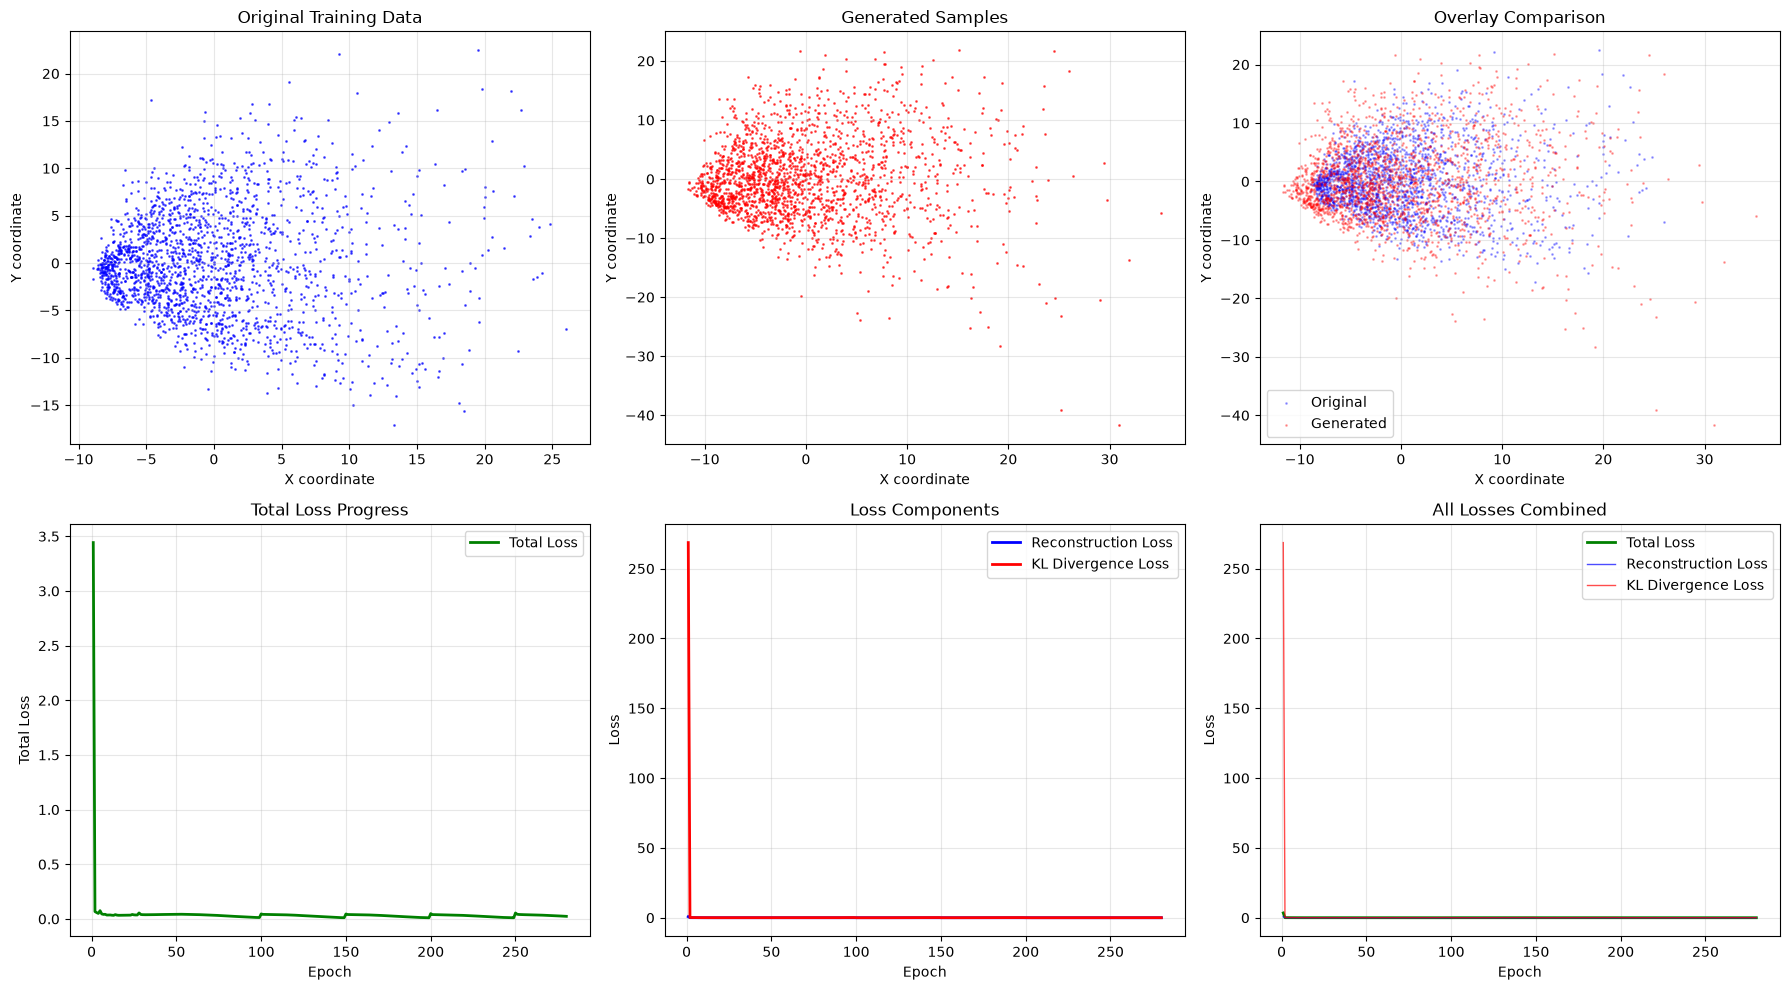

📈 Epoch 280 Summary:
   Total Loss: 0.0240
   Reconstruction Loss: 0.0146
   KL Divergence Loss: 0.0544
   Beta: 0.173
   Learning Rate: 0.000001

📊 Epoch 281/300
----------------------------------------
Epoch: 281 [0/60000 (0%)]	Total Loss: 0.023173	Recon Loss: 0.014459	KL Loss: 0.055162	Beta: 0.158
Epoch: 281 [51200/60000 (85%)]	Total Loss: 0.023270	Recon Loss: 0.014317	KL Loss: 0.056673	Beta: 0.158
====> Epoch: 281 Average Total Loss: 0.0231, Average Recon Loss: 0.0143, Average KL Loss: 0.0556, Beta: 0.158
📈 Epoch 281 Summary:
   Total Loss: 0.0231
   Reconstruction Loss: 0.0143
   KL Divergence Loss: 0.0556
   Beta: 0.158
   Learning Rate: 0.000001

📊 Epoch 282/300
----------------------------------------
Epoch: 282 [0/60000 (0%)]	Total Loss: 0.022383	Recon Loss: 0.014263	KL Loss: 0.056561	Beta: 0.144
Epoch: 282 [51200/60000 (85%)]	Total Loss: 0.022657	Recon Loss: 0.014407	KL Loss: 0.057472	Beta: 0.144
====> Epoch: 282 Average Total Loss: 0.0223, Average Recon Loss: 0.0141, Average

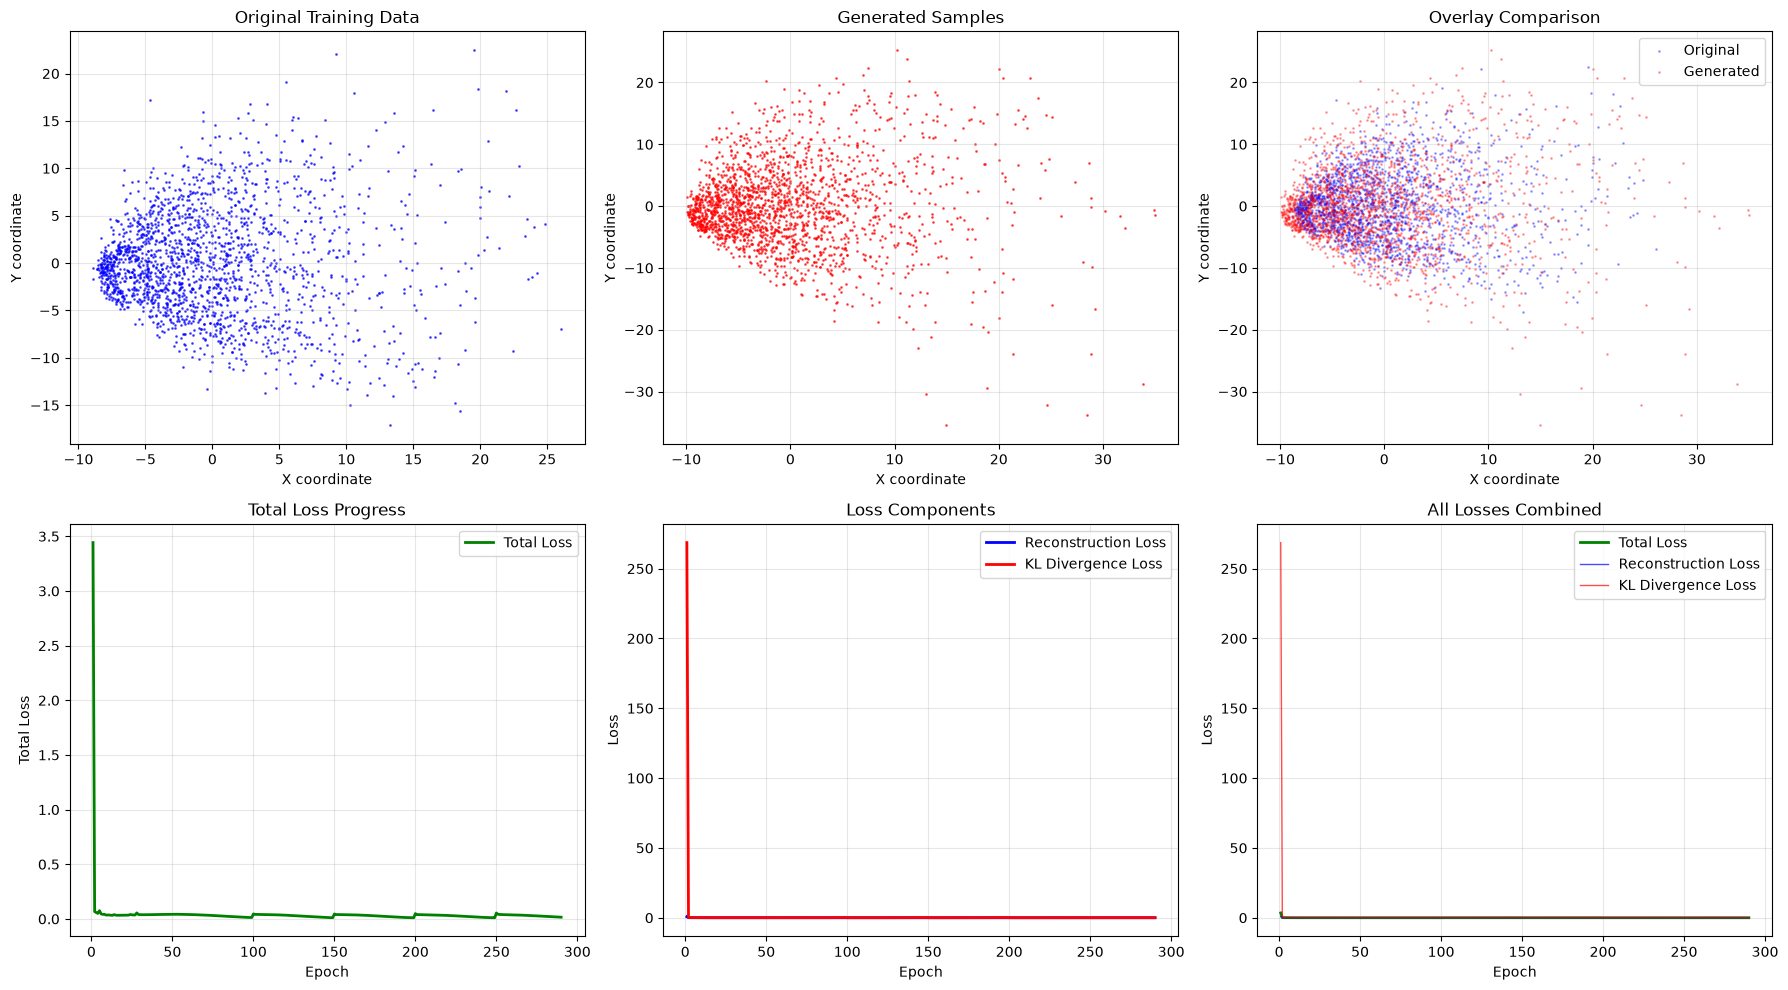

📈 Epoch 290 Summary:
   Total Loss: 0.0159
   Reconstruction Loss: 0.0127
   KL Divergence Loss: 0.0670
   Beta: 0.048
   Learning Rate: 0.000000

📊 Epoch 291/300
----------------------------------------
Epoch: 291 [0/60000 (0%)]	Total Loss: 0.015498	Recon Loss: 0.012843	KL Loss: 0.068218	Beta: 0.039
Epoch: 291 [51200/60000 (85%)]	Total Loss: 0.014908	Recon Loss: 0.012212	KL Loss: 0.069263	Beta: 0.039
====> Epoch: 291 Average Total Loss: 0.0152, Average Recon Loss: 0.0126, Average KL Loss: 0.0687, Beta: 0.039
📈 Epoch 291 Summary:
   Total Loss: 0.0152
   Reconstruction Loss: 0.0126
   KL Divergence Loss: 0.0687
   Beta: 0.039
   Learning Rate: 0.000000

📊 Epoch 292/300
----------------------------------------
Epoch: 292 [0/60000 (0%)]	Total Loss: 0.014750	Recon Loss: 0.012595	KL Loss: 0.069704	Beta: 0.031
Epoch: 292 [51200/60000 (85%)]	Total Loss: 0.014352	Recon Loss: 0.012159	KL Loss: 0.070912	Beta: 0.031
====> Epoch: 292 Average Total Loss: 0.0146, Average Recon Loss: 0.0124, Average

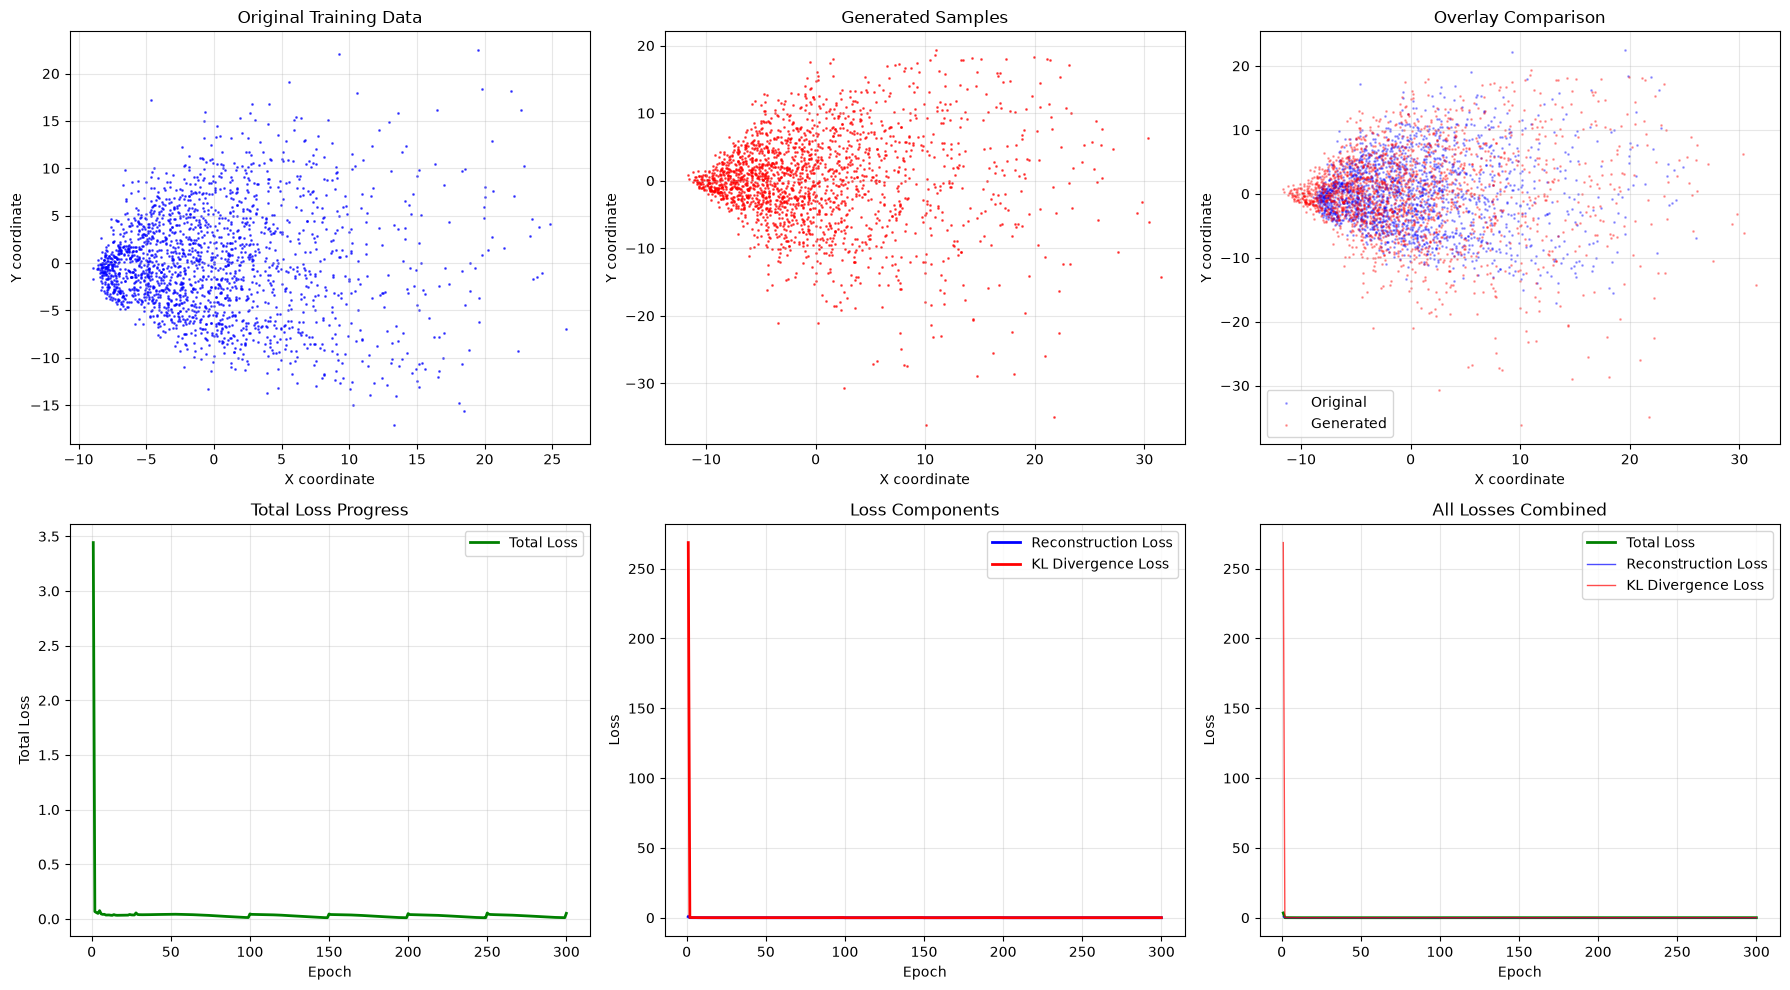

📈 Epoch 300 Summary:
   Total Loss: 0.0513
   Reconstruction Loss: 0.0119
   KL Divergence Loss: 0.0788
   Beta: 0.500
   Learning Rate: 0.000000

🎉 Training completed!
💾 Model saved as 'vae_model.pth'

🎨 Final comprehensive visualization:
💾 Saved plot: vae_results/vae_progress_epoch_300.png


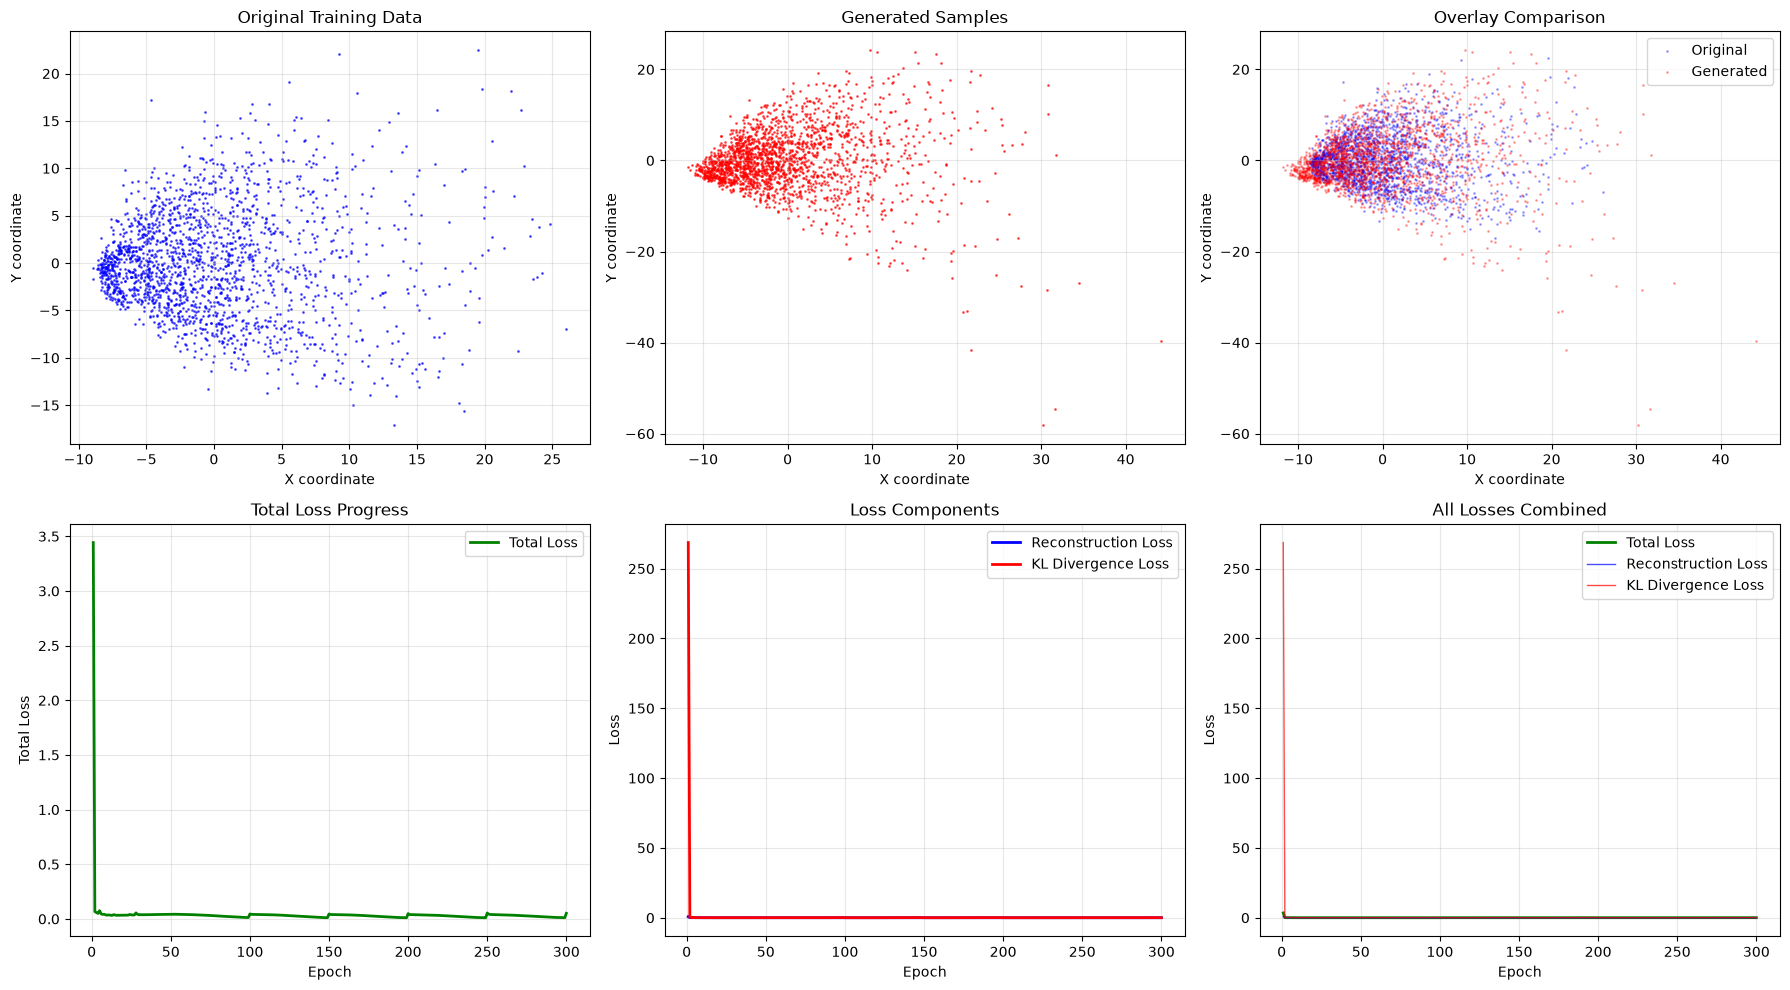

In [10]:
# Training loop
print("🎯 Starting VAE training...")
print("=" * 60)

# Lists to track training progress
total_losses = []
recon_losses = []
kl_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")
visualize_training_progress(0, [], [], [], save_plot=True)

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch
    avg_total_loss, avg_recon_loss, avg_kl_loss, current_beta = train_epoch(epoch)
    
    # Track losses
    total_losses.append(avg_total_loss)
    recon_losses.append(avg_recon_loss)
    kl_losses.append(avg_kl_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, total_losses, recon_losses, kl_losses, save_plot=True)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Total Loss: {avg_total_loss:.4f}")
    print(f"   Reconstruction Loss: {avg_recon_loss:.4f}")
    print(f"   KL Divergence Loss: {avg_kl_loss:.4f}")
    print(f"   Beta: {current_beta:.3f}")
    print(f"   Learning Rate: {optimizer.param_groups[0]['lr']:.6f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained model
torch.save(vae.state_dict(), 'models/vae_model.pth')
print("💾 Model saved as 'vae_model.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, total_losses, recon_losses, kl_losses, save_plot=True)


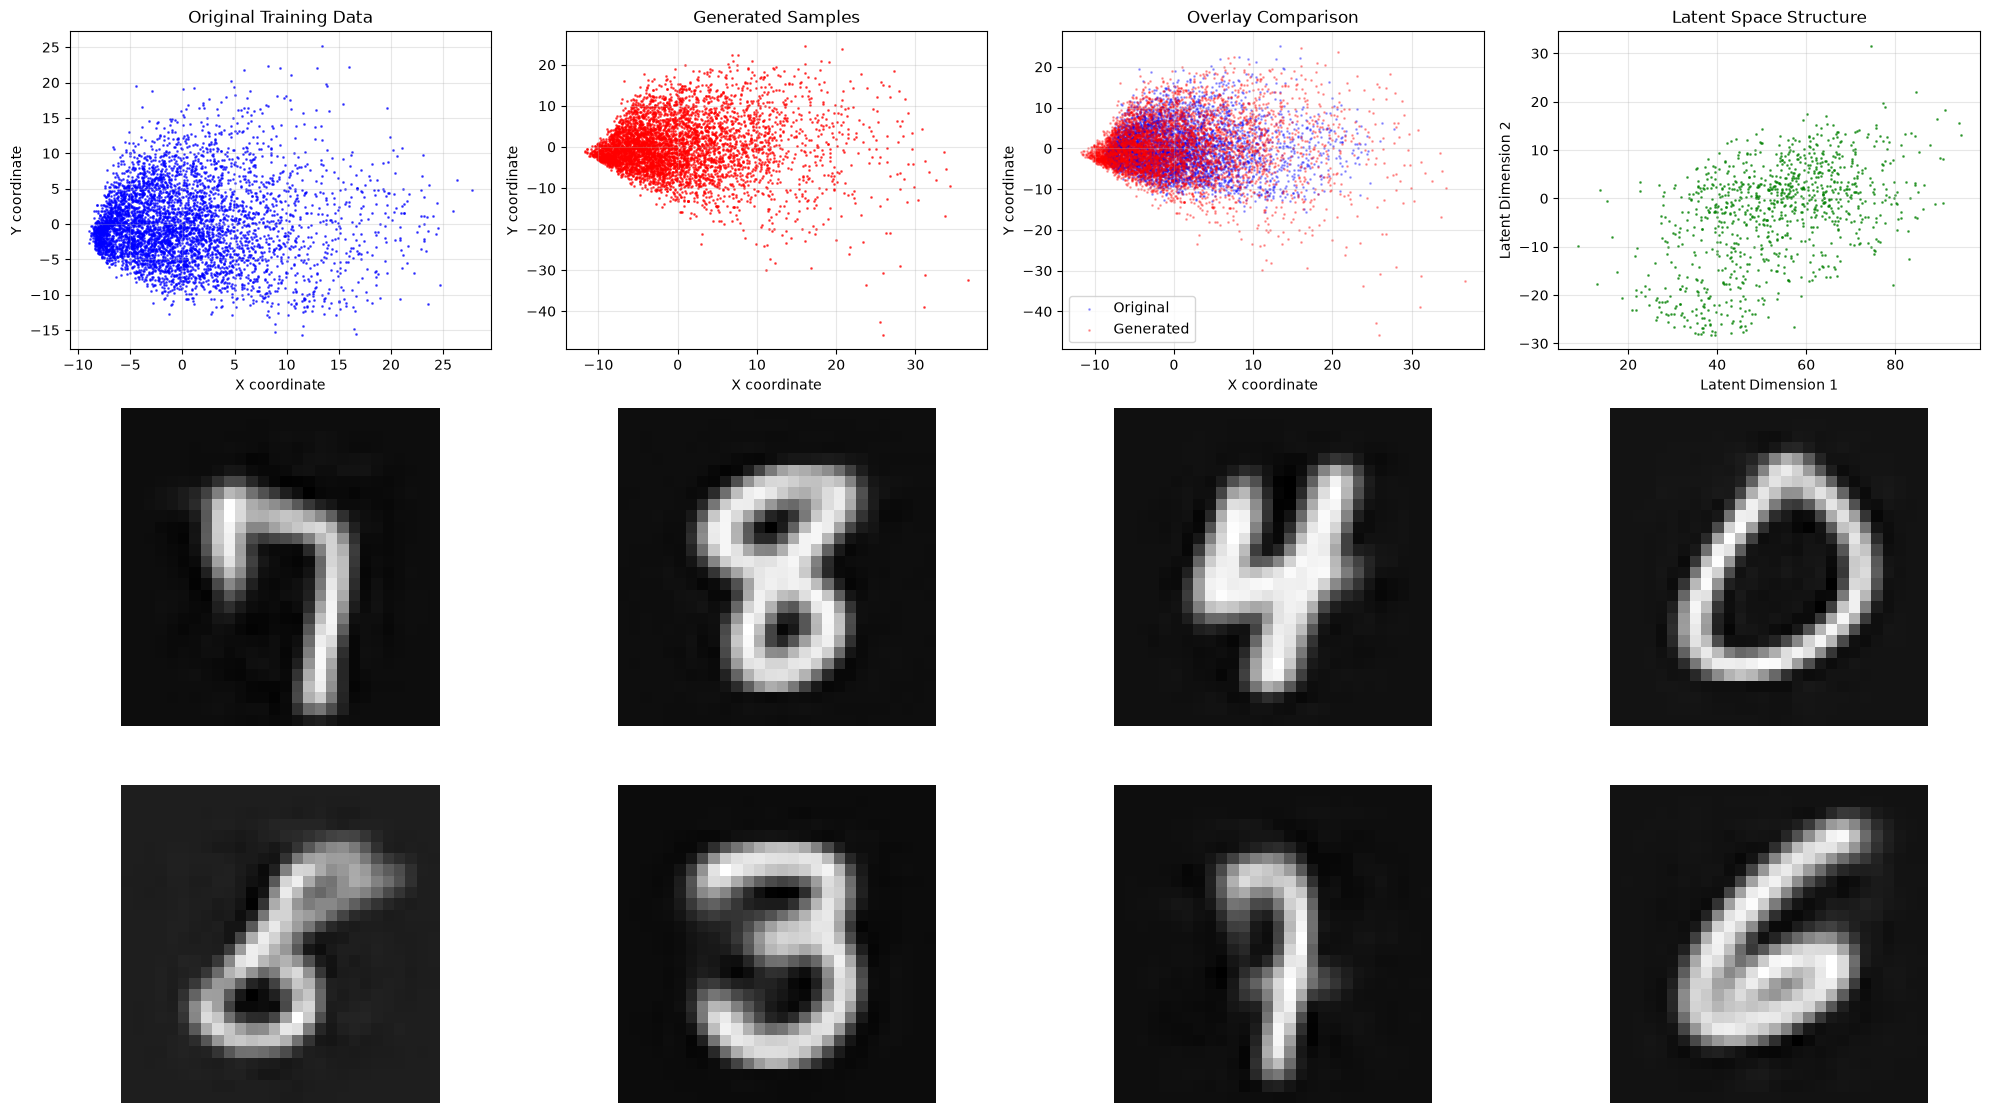

In [11]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 4, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 4, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 4, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)

# Show the latent space structure
plt.subplot(4, 4, 4)
# Encode some real data to see latent space
vae.eval()
with torch.no_grad():
    train_data_reshaped = np.reshape(train_data.data[:1000], [1000, INPUT_DIM])
    mu, logvar = vae.encode(train_data_reshaped.to(device).float())
    latent_points = mu.cpu().numpy()

plt.scatter(latent_points[:, 0], latent_points[:, 1], c='green', s=1, alpha=0.6)
plt.title('Latent Space Structure')
plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.grid(True, alpha=0.3)


for i in range(8):
    plt.subplot(4, 4, 4 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


## 🚀 Next Steps and Experiments

Now that you understand the basics, here are some exciting experiments you can try:

### Easy Experiments:
1. **Change the Dataset**: Try different datasets like circles, spirals, or your own 2D data
2. **Adjust Hyperparameters**: 
   - Change learning rate (try 1e-4, 1e-2)
   - Modify network sizes (try 128, 512 hidden units)
   - Adjust beta parameter (try 0.1, 2.0, 10.0)
3. **Visualize Training**: Watch how the latent space evolves during training

### Intermediate Experiments:
4. **Different Latent Dimensions**: Try 1D, 3D, or 4D latent spaces
5. **Beta-VAE**: Experiment with different beta values to control disentanglement
6. **Conditional VAE**: Generate different types of data based on labels

### Advanced Experiments:
7. **Higher Dimensions**: Apply to image data (MNIST, CIFAR-10)
8. **WAE (Wasserstein Autoencoder)**: Implement the Wasserstein variant
9. **VAE-GAN**: Combine VAE with GAN for better generation quality

### Code Modifications to Try:
```python
# Try different datasets
from sklearn.datasets import make_circles, make_spiral
train_data = make_circles(n_samples=50000, noise=0.05)[0].astype(np.float32)

# Try different architectures
LATENT_DIM = 4         # Higher dimensional latent space
HIDDEN_DIM = 512       # Larger networks

# Try different beta values
BETA = 0.1             # Less regularization
BETA = 10.0            # More regularization
```


## 📚 Further Reading and Resources

### Papers to Read:
1. **Original VAE Paper**: "Auto-Encoding Variational Bayes" by Kingma & Welling (2014)
2. **Beta-VAE**: "β-VAE: Learning Basic Visual Concepts with a Constrained Variational Framework" by Higgins et al. (2017)
3. **WAE**: "Wasserstein Auto-Encoders" by Tolstikhin et al. (2018)
4. **VAE-GAN**: "Autoencoding beyond pixels using a learned similarity metric" by Larsen et al. (2016)

### Libraries to Explore:
- **PyTorch Lightning**: For easier VAE training
- **Hugging Face Transformers**: For text-based VAEs
- **Pyro**: Probabilistic programming with VAEs

### Applications:
- **Image Generation**: Creating new images from scratch
- **Data Compression**: Learning efficient representations
- **Anomaly Detection**: Finding unusual patterns in data
- **Data Augmentation**: Generating more training data
- **Representation Learning**: Learning useful features for downstream tasks

### Key Takeaways:
- VAEs are powerful tools for generative modeling and representation learning
- The reparameterization trick is crucial for training
- The beta parameter controls the trade-off between reconstruction and regularization
- VAEs provide a principled way to learn continuous latent representations
- The latent space can be used for interpolation and manipulation

### Common VAE Challenges:
- **Blurry Reconstructions**: VAEs tend to produce smoother, less sharp outputs
- **Posterior Collapse**: When the latent space becomes uninformative
- **Beta Tuning**: Finding the right balance between reconstruction and regularization
- **Evaluation**: Measuring VAE quality objectively

---

**Happy Learning! 🎓**

*Remember: The best way to learn is by experimenting. Try modifying the code, changing parameters, and seeing what happens. Every experiment teaches you something new about how VAEs work!*
